# B8 · RL moderne : DQN, gradient de politique, PPO et RLHF — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/b8_rl_moderne/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | B8.Q1 à B8.Q12, B8.R1 à B8.R3, B8.1 à B8.6 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | B8.12 | CartPole pour le deep RL : espaces, politique aléatoire, evaluate_policy et la référence tabulaire du ch. 26 | 📦 | ★ | 15 |
|  | B8.13 | DQN sur CartPole : réseau Q, ReplayBuffer de rl.py, réseau cible, Huber, ε décroissant | 📦 | ★★★ | 60 |
|  | B8.14 | Le DQN qui diverge : quatre erreurs de cible, de fin d'épisode et d'exploration | 🐛 | ★★ | 30 |
|  | B8.15 | Ablations du DQN : sans réseau cible, sans rejeu, avec Double DQN — trois graines 🚀 | 🔬 | ★★★ | 50 |
| B | B8.16 | Prédire : REINFORCE sans baseline, avec baseline, avec retours normalisés — lequel apprend le plus vite ? | 🔮 | ★ | 10 |
|  | B8.17 | REINFORCE avec et sans baseline : variance du gradient et vitesse d'apprentissage | 📦 | ★★★ | 45 |
|  | B8.18 | compute_gae et explained_variance | 🔨 | ★★ | 30 |
|  | B8.19 | clipped_surrogate : valeur et gradient par rapport au ratio | 🔨 | ★★ | 20 |
|  | B8.20 | PPO from scratch sur CartPole : environnements vectorisés, acteur-critique, GAE, clip, entropie | 📦 | ★★★★ | 150 |
|  | B8.21 | Lire les journaux de PPO : KL approchée, fraction clippée, entropie, variance expliquée | 📈 | ★★ | 20 |
|  | B8.22 | Hyperparamètres de PPO : ε du clip, λ, nombre d'epochs — robustesse sur trois graines 🚀 | 🔬 | ★★★ | 45 |
|  | B8.23 | Prédire : l'agent PPO face à une gravité doublée ou à un mât deux fois plus long | 🔮 | ★ | 10 |
|  | B8.24 | Robustesse : modifier la physique de CartPole et mesurer la chute du retour | 🔬 | ★★ | 25 |
| C | B8.25 | bradley_terry_loss et dpo_loss | 🔨 | ★★ | 20 |
|  | B8.26 | RLHF miniature : un modèle de récompense appris sur des préférences simulées, puis PPO — et le piratage de la récompense | 📦 | ★★★★ | 90 |
|  | B8.27 | Revue de code : comparer ton PPO à une implémentation de référence et documenter chaque écart | 🛠️ | ★★ | 30 |
|  | B8.28 | Défi : CartPole-v1 résolu (≥ 475 sur 100 épisodes) en au plus 100 000 pas, trois graines sur trois | 🏆 | ★★★★ | 120 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Expliquer pourquoi et comment un réseau remplace la table Q, et ce qui rend DQN stable.
- Dériver le gradient de politique et justifier la baseline, l'avantage et GAE.
- Implémenter en PyTorch un DQN, REINFORCE et PPO sur CartPole, avec les calculs clés testés dans `mylearn`.
- Diagnostiquer un entraînement RL à partir de ses journaux et comparer des variantes sur plusieurs graines.
- Expliquer RLHF, DPO et GRPO et entraîner un modèle de récompense sur des préférences.

**Rappel express.** Cible DQN $y = r + \gamma(1 - d)\max_{a'} Q_{\bar\theta}(s', a')$ ; Double DQN : $Q_{\bar\theta}(s', \arg\max_{a'} Q_\theta(s', a'))$. Huber : $\frac12 x^2$ si $|x| \le \delta$, $\delta(|x| - \frac{\delta}{2})$ sinon. $\nabla_{\mathbf z} \log \operatorname{softmax}(\mathbf z)_a = \mathbf e_a - \operatorname{softmax}(\mathbf z)$. $\delta_t = r_t + \gamma(1 - \text{terminated}_t)V(s_{t+1}) - V(s_t)$, $\hat A_t = \delta_t + \gamma\lambda(1 - \text{done}_t)\hat A_{t+1}$. PPO : $-\operatorname{mean}\min(\rho \hat A, \operatorname{clip}(\rho, 1 \pm \varepsilon)\hat A)$. Bradley-Terry : $-\log\sigma(r_w - r_l)$ ; DPO : $-\log\sigma\big(\beta[(\log\pi_w - \log\pi^{\text{ref}}_w) - (\log\pi_l - \log\pi^{\text{ref}}_l)]\big)$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ B8.1 à B8.6)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; plusieurs choix : les lettres ensemble, entre guillemets, dans n'importe quel ordre (`"EF"`) ; une forme : entre guillemets (`"(3, 5)"`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la dérivation ∂ B8.7, l'estimation 🧮 B8.8, la réflexion (🗣️ B8.9, ⚖️ B8.10, 📄 B8.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math
from itertools import product

import numpy as np


def sigmoid(u):
    return 1.0 / (1.0 + math.exp(-u))


def softplus(u):                                       # -log sigmoid(-u) = log(1 + e^u)
    return math.log1p(math.exp(u))


# quiz Q1: CartPole discretised into 6 intervals per variable, 2 actions ; a Q network on a batch of 32 states
Q1A = 6 ** 4 * 2
# quiz Q3: a full memory of 10 000 transitions, one replaced per step, 64 distinct transitions drawn per update
CAP_Q3, BATCH_Q3 = 10_000, 64
Q3A = CAP_Q3 * BATCH_Q3 / CAP_Q3                       # steps of stay x probability of being drawn at each step
Q3D = (1 - 0.005) ** 200                                # weight left on the target weights of 200 steps ago
# quiz Q4: three actions of value 0, estimates +1 or -1 with probability 1/2, independently
OUTCOMES_Q4 = list(product([-1, 1], repeat=3))
Q4B = float(np.mean([max(o) for o in OUTCOMES_Q4]))
Q4C = float(np.mean([second[int(np.argmax(first))] for first in OUTCOMES_Q4 for second in OUTCOMES_Q4]))
# quiz Q5: 6 motors with 10 values each ; a softmax with logits (ln 2, ln 6, 0)
Q5B = 10 ** 6
LOGITS_Q5 = np.array([math.log(2), math.log(6), 0.0])
Q5C = float(np.exp(LOGITS_Q5)[1] / np.exp(LOGITS_Q5).sum())
# quiz Q6: a biased coin, p(heads) = theta = 0.3 ; the score function d/dtheta log p(x)
THETA_Q6 = 0.3
SCORE_TAILS_Q6 = -1 / (1 - THETA_Q6)
Q6B = THETA_Q6 * (1 / THETA_Q6) + (1 - THETA_Q6) * SCORE_TAILS_Q6
# quiz Q7: one TD error ; the weight of delta_(t+10) with gamma = 0.99 and lambda = 0.95
Q7A = 1 + 0.9 * 2.5 - 3.0
Q7D = (0.99 * 0.95) ** 10
# quiz Q8: N = 8 environments, T = 256 steps, 4 epochs, mini-batches of 256 ; a ratio from two log-probabilities
Q8C = 4 * (8 * 256) // 256
Q8D = math.exp(-0.9 - (-1.2))
# quiz Q10: an evaluation cut at max_steps = 300 ; the standard error of a mean of 100 returns
Q10A, Q10B = 300, 40 / math.sqrt(100)
# quiz Q11: GRPO advantages in a group (1, 0, 0, 0), population standard deviation
REWARDS_Q11 = np.array([1.0, 0.0, 0.0, 0.0])
Q11C = float((REWARDS_Q11[0] - REWARDS_Q11.mean()) / REWARDS_Q11.std())
Q11C_DDOF1 = float((REWARDS_Q11[0] - REWARDS_Q11.mean()) / REWARDS_Q11.std(ddof=1))
# recall R1: one Q-learning update
Q_R1, R_R1, GAMMA_R1, MAX_R1, ALPHA_R1 = 0.5, 0.3, 0.8, 0.6, 0.2
R1A = R_R1 + GAMMA_R1 * MAX_R1
R1B = Q_R1 + ALPHA_R1 * (R1A - Q_R1)
R1C = Q_R1 + ALPHA_R1 * (R_R1 - Q_R1)
# recall R2: the first step of Adam with bias correction ; clipping by the global norm (PyTorch adds 1e-6)
W_R2, G_R2, LR_R2, B1_R2, B2_R2, EPS_R2 = 1.0, -40.0, 1e-3, 0.9, 0.999, 1e-8
M_R2, V_R2 = (1 - B1_R2) * G_R2, (1 - B2_R2) * G_R2 ** 2
R2A = W_R2 - LR_R2 * (M_R2 / (1 - B1_R2)) / (math.sqrt(V_R2 / (1 - B2_R2)) + EPS_R2)
R2A_NO_CORRECTION = W_R2 - LR_R2 * M_R2 / (math.sqrt(V_R2) + EPS_R2)
GRADS_R2 = [np.array([3.0, 4.0]), np.array([12.0])]
NORM_R2 = math.sqrt(sum(float((g ** 2).sum()) for g in GRADS_R2))
R2B = 3.0 * min(1.0, 0.5 / (NORM_R2 + 1e-6))
# recall R3: epsilon-greedy over 2 actions ; a softmax with temperature 0.5 ; an incremental mean
R3A = 1 - 0.2 + 0.2 / 2
R3B = float(np.exp(1.5 / 0.5) / (np.exp(1.0 / 0.5) + np.exp(1.5 / 0.5)))
R3C = 4 + (8 - 4) / 4

# ✏️ B8.1: three transitions, gamma = 0.99, r = 1 ; transition 2 is terminated, transition 3 truncated
GAMMA_B81 = 0.99
QT_B81 = np.array([[12.0, 13.7], [4.0, 3.1], [40.2, 41.6]])        # Q_target(s', .)
QO_B81 = np.array([[12.6, 12.2], [2.5, 3.8], [42.5, 41.7]])        # Q_online(s', .)
TERM_B81 = np.array([False, True, False])
PRED_B81 = np.array([15.0, 2.9, 45.3])                              # Q_online(s, a) of the played action
DQN_B81 = 1 + GAMMA_B81 * (1 - TERM_B81) * QT_B81.max(axis=1)
DDQN_B81 = 1 + GAMMA_B81 * (1 - TERM_B81) * QT_B81[np.arange(3), QO_B81.argmax(axis=1)]
GAP_B81 = float(np.mean(DQN_B81 - DDQN_B81))
AGREE_B81 = bool(QT_B81[0].argmax() == QO_B81[0].argmax())
X3_B81 = float(PRED_B81[2] - DQN_B81[2])

# ✏️ B8.2: three gaps x = Q - y, Huber threshold 1.5
X_B82, DELTA_B82 = np.array([0.6, -2.4, 3.2]), 1.5


def huber_b82(x, delta=DELTA_B82):
    x = np.asarray(x, float)
    return np.where(np.abs(x) <= delta, 0.5 * x ** 2, delta * (np.abs(x) - delta / 2))


def huber_grad_b82(x, delta=DELTA_B82):
    return np.clip(np.asarray(x, float), -delta, delta)


TERMS_B82 = huber_b82(X_B82)
MEAN_B82 = float(TERMS_B82.mean())
GRAD3_B82 = float(huber_grad_b82(X_B82)[2] / 3)
GRAD3_MSE_B82 = float(X_B82[2] / 3)
SMOOTH_B82 = MEAN_B82 / DELTA_B82                                   # smooth_l1_loss(beta) = huber(delta=beta) / beta
SAME_GRAD_B82 = bool(huber_grad_b82(0.6) == 0.6)

# ✏️ B8.3: softmax policy with logits (0.5, 1.5, -0.5), action 2 played, advantage -2, step 0.1
Z_B83, A_B83, ADV_B83, STEP_B83 = np.array([0.5, 1.5, -0.5]), 2, -2.0, 0.1


def softmax_b83(z):
    e = np.exp(np.asarray(z, float) - np.max(z))
    return e / e.sum()


PI_B83 = softmax_b83(Z_B83)
GRAD_B83 = np.eye(3)[A_B83] - PI_B83                                # grad_z log softmax(z)_a = e_a - softmax(z)
Z_NEW_B83 = Z_B83 + STEP_B83 * ADV_B83 * GRAD_B83
PI_NEW_B83 = softmax_b83(Z_NEW_B83)
ENTROPY_B83 = float(-(PI_B83 * np.log(PI_B83)).sum())

# ✏️ B8.4: four steps, gamma = 0.9, truncated at step 1 (no terminated step), the rollout ends after step 3
R_B84 = np.ones(4)
V_B84 = np.array([4.0, 3.8, 2.0, 2.4])
NEXT_B84 = np.array([3.8, 3.6, 2.4, 2.6])
TERM_B84 = np.zeros(4, dtype=bool)
TRUNC_B84 = np.array([False, True, False, False])
GAMMA_B84 = 0.9


def gae_b84(lam, terminated=TERM_B84, truncated=TRUNC_B84, values=V_B84, next_values=NEXT_B84):
    """Backward loop of 208.4: delta_t = r + gamma (1 - term) V(s') - V(s), A_t = delta_t + gamma lam (1 - done) A_(t+1)."""
    deltas = R_B84 + GAMMA_B84 * (1 - terminated) * next_values - values
    adv, future = np.zeros(4), 0.0
    for t in range(3, -1, -1):
        future = deltas[t] + GAMMA_B84 * lam * (1 - (terminated[t] or truncated[t])) * future
        adv[t] = future
    return deltas, adv


DELTA_B84, ADV0_B84 = gae_b84(0.0)
_, ADV95_B84 = gae_b84(0.95)
_, ADV1_B84 = gae_b84(1.0)
RET95_B84 = ADV95_B84 + V_B84
_, ADV95_AS_END_B84 = gae_b84(0.95, terminated=TRUNC_B84, truncated=TERM_B84)    # truncation taken as a true end
_, ADV95_NO_STOP_B84 = gae_b84(0.95, truncated=TERM_B84)                          # the recursion does not stop
MC_B84 = bool(math.isclose(ADV1_B84[0] + V_B84[0], 1 + GAMMA_B84 * 1 + GAMMA_B84 ** 2 * 3.6))

# ✏️ B8.5: four transitions, eps = 0.2 (then 0.3)
RATIO_B85 = np.array([1.4, 0.6, 0.75, 1.35])
ADV_B85 = np.array([2.0, 1.5, -1.2, -0.8])


def clip_b85(eps):
    unclipped = RATIO_B85 * ADV_B85
    clipped = np.clip(RATIO_B85, 1 - eps, 1 + eps) * ADV_B85
    terms = np.minimum(unclipped, clipped)
    grad = np.where(unclipped <= clipped, -ADV_B85 / 4, 0.0)
    return terms, -float(terms.mean()), grad


TERMS_B85, LOSS_B85, GRAD_B85 = clip_b85(0.2)
ZERO_B85 = int((GRAD_B85 == 0).sum())
CLIPFRAC_B85 = float(np.mean(np.abs(RATIO_B85 - 1) > 0.2))
ZERO_EPS3_B85 = int((clip_b85(0.3)[2] == 0).sum())
# a classic mistake for d): the max instead of the min
LOSS_MAX_B85 = -float(np.maximum(RATIO_B85 * ADV_B85, np.clip(RATIO_B85, 0.8, 1.2) * ADV_B85).mean())

# ✏️ B8.6: Bradley-Terry on one pair, then DPO
RW_B86, RL_B86 = 2.3, 1.1
P_B86 = sigmoid(RW_B86 - RL_B86)
LOSS_B86 = softplus(-(RW_B86 - RL_B86))
GRAD_W_B86 = -(1 - P_B86)
LOSS_SWAP_B86 = softplus(RW_B86 - RL_B86)
LOGP_B86 = {"pc": -35.2, "pr": -38.9, "rc": -36.0, "rr": -37.5}


def dpo_b86(beta):
    chosen = LOGP_B86["pc"] - LOGP_B86["rc"]
    rejected = LOGP_B86["pr"] - LOGP_B86["rr"]
    margin = beta * (chosen - rejected)
    return beta * chosen, margin, softplus(-margin), -beta * sigmoid(-margin)


IMPLICIT_B86, MARGIN_B86, DPO_B86, DPO_GRAD_B86 = dpo_b86(0.1)
DPO5_B86 = dpo_b86(0.5)[2]

# The same answers from the libraries (no download, no training): the reference mylearn.deep_rl and mylearn.rl,
# PyTorch (losses, autograd, Adam, clip_grad_norm_, Categorical) and gymnasium (CartPole-v1, seeds)
import warnings

import gymnasium as gym
import torch
import torch.nn.functional as F

DRL, RL = mylearn.deep_rl, mylearn.rl

# quiz Q1: CartPole-v1 has 4 state variables and 2 actions ; a Q network rends one value per action
env = gym.make("CartPole-v1")
assert env.observation_space.shape == (4,) and env.action_space.n == 2
assert env.spec.max_episode_steps == 500 and env.spec.reward_threshold == 475.0
assert Q1A == 6 ** env.observation_space.shape[0] * env.action_space.n
torch.manual_seed(0)
q_net = torch.nn.Sequential(torch.nn.Linear(4, 16), torch.nn.ReLU(), torch.nn.Linear(16, 2))
assert tuple(q_net(torch.zeros(32, 4)).shape) == (32, 2)

# quiz Q1 d): the semi-gradient (target detached) and the full gradient differ
s, s_next = torch.randn(1, 4), torch.randn(1, 4)
semi = (q_net(s)[0, 0] - (1 + 0.9 * q_net(s_next).max().detach())) ** 2
full = (q_net(s)[0, 0] - (1 + 0.9 * q_net(s_next).max())) ** 2
g_semi = torch.autograd.grad(semi, list(q_net.parameters()))
g_full = torch.autograd.grad(full, list(q_net.parameters()))
assert any((a - b).abs().max() > 1e-6 for a, b in zip(g_semi, g_full))

# quiz Q3 a): simulate the full memory of rl.ReplayBuffer, 64 distinct transitions per update
buffer = RL.ReplayBuffer(capacity=1_000, obs_shape=(4,), obs_dtype="float32", random_state=0)
for i in range(1_000):
    buffer.push(np.zeros(4, np.float32), 0, float(i), np.zeros(4, np.float32), False)
draws = np.zeros(1_000)
for _ in range(2_000):
    batch = buffer.sample(64)
    assert len(np.unique(batch["rewards"])) == 64                     # distinct transitions within a mini-batch
    draws[batch["rewards"].astype(int)] += 1
assert abs(draws.mean() * 1_000 / 2_000 - BATCH_Q3) < 1               # per 1 000 steps of stay: 64 draws
buffer.push(np.ones(4, np.float32), 1, -1.0, np.ones(4, np.float32), True)
assert len(buffer) == 1_000 and -1.0 in buffer.sample(1_000)["rewards"] and 0.0 not in buffer.sample(1_000)["rewards"]

# quiz Q4: Monte Carlo check of the exact enumerations
rng = np.random.default_rng(0)
est = rng.choice([-1, 1], size=(200_000, 2, 3))
assert abs(est[:, 0].max(axis=1).mean() - Q4B) < 0.01
assert abs(est[np.arange(200_000), 1, est[:, 0].argmax(axis=1)].mean() - Q4C) < 0.01

# quiz Q5 c), quiz R3 b): softmax by torch
assert math.isclose(torch.softmax(torch.tensor(LOGITS_Q5), 0)[1].item(), Q5C, rel_tol=1e-9)
assert math.isclose(torch.softmax(torch.tensor([1.0, 1.5], dtype=torch.float64) / 0.5, 0)[1].item(), R3B)

# quiz Q6: the score of a Bernoulli by autograd
theta = torch.tensor(THETA_Q6, dtype=torch.float64, requires_grad=True)
torch.log(1 - theta).backward()
assert math.isclose(theta.grad.item(), SCORE_TAILS_Q6) and abs(Q6B) < 1e-12

# quiz Q7: one TD error and the GAE weight with the reference compute_gae (lambda = 0 gives the TD error)
adv, _ = DRL.compute_gae([1.0], [3.0], [2.5], [False], [False], gamma=0.9, lam=0.0)
assert math.isclose(adv[0], Q7A)
impulse = np.zeros(11)
impulse[10] = 1.0                                  # a TD error of 1 at step 10 only: r = delta, V = 0
adv, _ = DRL.compute_gae(impulse, np.zeros(11), np.zeros(11), np.zeros(11, bool), np.zeros(11, bool), gamma=0.99, lam=0.95)
assert math.isclose(adv[0], Q7D)

# quiz Q8 f), ✏️ B8.5: the clipped objective by torch.min/torch.clamp and autograd, and the reference
for eps, (terms, loss, grad) in ((0.2, clip_b85(0.2)), (0.3, clip_b85(0.3))):
    ratio = torch.tensor(RATIO_B85, requires_grad=True)
    adv_t = torch.tensor(ADV_B85)
    loss_t = -torch.min(ratio * adv_t, ratio.clamp(1 - eps, 1 + eps) * adv_t).mean()
    loss_t.backward()
    assert math.isclose(loss_t.item(), loss) and np.allclose(ratio.grad.numpy(), grad)
    ref_loss, ref_grad = DRL.clipped_surrogate(RATIO_B85, ADV_B85, clip_eps=eps)
    assert math.isclose(ref_loss, loss) and np.allclose(ref_grad, grad)
_, grad_zero_adv = DRL.clipped_surrogate([0.3, 1.0, 2.5], [0.0, 0.0, 0.0])
assert np.all(grad_zero_adv == 0)

# quiz Q10: gymnasium seeds ; evaluate_policy cut at max_steps (a perfect rule of 208.1)
env.reset(seed=3)
first = env.reset(seed=3)[0]
assert not np.allclose(env.reset()[0], first)                     # reset() without a seed continues the sequence
env.reset(seed=3)
a1 = [env.action_space.sample() for _ in range(20)]
env.reset(seed=3)
a2 = [env.action_space.sample() for _ in range(20)]
assert a1 != a2                                                   # reset(seed=...) does not seed the action space
rule = lambda state, info: int(state[2] + 0.5 * state[3] > 0)    # noqa: E731
assert RL.evaluate_policy(env, rule, n_episodes=5, max_steps=Q10A, rng=np.random.default_rng(1))["mean_return"] == Q10A

# quiz Q11: the GRPO advantages of a group
assert math.isclose(Q11C, 3 / math.sqrt(3)) and math.isclose(Q11C_DDOF1, 1.5)

# recall R2: Adam and clip_grad_norm_ in PyTorch
w = torch.nn.Parameter(torch.tensor([W_R2], dtype=torch.float64))
opt = torch.optim.Adam([w], lr=LR_R2, betas=(B1_R2, B2_R2), eps=EPS_R2)
w.grad = torch.tensor([G_R2], dtype=torch.float64)
opt.step()
assert math.isclose(w.item(), R2A, rel_tol=1e-12)
p1, p2 = torch.nn.Parameter(torch.zeros(2)), torch.nn.Parameter(torch.zeros(1))
p1.grad, p2.grad = torch.tensor([3.0, 4.0]), torch.tensor([12.0])
assert math.isclose(torch.nn.utils.clip_grad_norm_([p1, p2], max_norm=0.5).item(), NORM_R2)
assert math.isclose(p1.grad[0].item(), R2B, rel_tol=1e-6)
assert math.isclose(float(torch.cat([p1.grad, p2.grad]).norm()), 0.5, rel_tol=1e-5)

# ✏️ B8.1: the targets in PyTorch (max, then argmax + gather), under no_grad
with torch.no_grad():
    qt, qo = torch.tensor(QT_B81), torch.tensor(QO_B81)
    term = torch.tensor(TERM_B81)
    y = 1 + GAMMA_B81 * (1 - term.double()) * qt.max(dim=1).values
    y_double = 1 + GAMMA_B81 * (1 - term.double()) * qt.gather(1, qo.argmax(dim=1, keepdim=True)).squeeze(1)
assert np.allclose(y.numpy(), DQN_B81) and np.allclose(y_double.numpy(), DDQN_B81)

# ✏️ B8.2: F.huber_loss and F.smooth_l1_loss, values and gradients
pred = torch.tensor(X_B82, requires_grad=True)
target = torch.zeros(3, dtype=torch.float64)
huber = F.huber_loss(pred, target, delta=DELTA_B82)
huber.backward()
assert math.isclose(huber.item(), MEAN_B82) and math.isclose(pred.grad[2].item(), GRAD3_B82)
assert np.allclose(F.huber_loss(pred.detach(), target, delta=DELTA_B82, reduction="none").numpy(), TERMS_B82)
assert math.isclose(F.smooth_l1_loss(pred.detach(), target, beta=DELTA_B82).item(), SMOOTH_B82)
mse = pred.detach().clone().requires_grad_()
(0.5 * mse ** 2).mean().backward()
assert math.isclose(mse.grad[2].item(), GRAD3_MSE_B82)

# ✏️ B8.3: log_softmax and autograd, one step, Categorical's entropy
z = torch.tensor(Z_B83, requires_grad=True)
torch.log_softmax(z, dim=0)[A_B83].backward()
assert np.allclose(z.grad.numpy(), GRAD_B83)
assert np.allclose(torch.softmax(torch.tensor(Z_NEW_B83), 0).numpy(), PI_NEW_B83)
assert math.isclose(torch.distributions.Categorical(logits=torch.tensor(Z_B83)).entropy().item(), ENTROPY_B83)

# ✏️ B8.4: the reference compute_gae for the three lambdas, and the two classic mistakes
for lam, expected in ((0.0, ADV0_B84), (0.95, ADV95_B84), (1.0, ADV1_B84)):
    adv, ret = DRL.compute_gae(R_B84, V_B84, NEXT_B84, TERM_B84, TRUNC_B84, gamma=GAMMA_B84, lam=lam)
    assert np.allclose(adv, expected) and np.allclose(ret, expected + V_B84)
adv, _ = DRL.compute_gae(R_B84, V_B84, NEXT_B84, TRUNC_B84, TERM_B84, gamma=GAMMA_B84, lam=0.95)
assert np.allclose(adv, ADV95_AS_END_B84)

# ✏️ B8.6: the reference losses and F.logsigmoid with autograd
loss, g_w, g_l = DRL.bradley_terry_loss([RW_B86], [RL_B86])
assert math.isclose(loss, LOSS_B86) and math.isclose(g_w[0], GRAD_W_B86) and math.isclose(g_l[0], -GRAD_W_B86)
assert math.isclose(DRL.bradley_terry_loss([RW_B86 + 10], [RL_B86 + 10])[0], LOSS_B86, rel_tol=1e-9)
assert math.isclose(DRL.bradley_terry_loss([RL_B86], [RW_B86])[0], LOSS_SWAP_B86)
pc = torch.tensor([LOGP_B86["pc"]], dtype=torch.float64, requires_grad=True)
for beta, expected in ((0.1, DPO_B86), (0.5, DPO5_B86)):
    loss_d, margins = DRL.dpo_loss([LOGP_B86["pc"]], [LOGP_B86["pr"]], [LOGP_B86["rc"]], [LOGP_B86["rr"]], beta=beta)
    assert math.isclose(loss_d, expected)
margin_t = 0.1 * ((pc - LOGP_B86["rc"]) - (LOGP_B86["pr"] - LOGP_B86["rr"]))
(-F.logsigmoid(margin_t)).mean().backward()
assert math.isclose(pc.grad.item(), DPO_GRAD_B86) and math.isclose(margin_t.item(), MARGIN_B86)
env.close()
print("✅ the paper answers agree with mylearn.deep_rl, mylearn.rl, PyTorch and gymnasium")

✅ the paper answers agree with mylearn.deep_rl, mylearn.rl, PyTorch and gymnasium


**B8.Q1 — Pourquoi une table Q ne suffit plus pour CartPole**

In [3]:
wb.record("B8.Q1a", Q1A, mistakes={"une case par état discrétisé et par action : n'oublie pas les actions": 6 ** 4,
          "les intervalles des quatre variables se combinent : ils se multiplient, ils ne s'additionnent pas": 48,
          "6 intervalles pour chacune des 4 variables : vérifie la base et l'exposant": 4 ** 6 * 2,
          "relis la question : 6 intervalles par variable, et quatre variables": 24})
wb.record("B8.Q1b", 1, mistakes={"relis ce que rend le réseau de 208.1 : une valeur pour un couple (état, action), ou un vecteur ?": 2,
          "il faut bien calculer les valeurs pour choisir : relis « Pourquoi la table ne suffit plus » (§208.1)": 0})
wb.record("B8.Q1c", True, mistakes={"relis « Pourquoi la table ne suffit plus » (§208.1) : que partagent deux états voisins dans un réseau ?": False})
wb.record("B8.Q1d", False, mistakes={"relis « Apprendre une valeur par régression » (§208.1) : que devient la méthode si la cible est dérivée aussi ?": True})
wb.record("B8.Q1e", "(32, 2)", mistakes={"le réseau rend une valeur par action : combien d'actions a CartPole ?": "(32, 1)",
          "4 est la dimension de l'entrée : que rend le réseau ?": "(32, 4)",
          "relis la question : un batch de 32 états passe d'un coup, pas un seul état": "(2,)",
          "la forme commence par l'axe des exemples": "(2, 32)"})

WB_ANSWER {"hash": "d2fa5a37ad88529b6d0be6d384471d428548b2c7bd4f9a9a8a66151d0670fd3d", "id": "B8.Q1a", "kind": "int", "magnitude": 3, "mistakes": {"30fd59084e4b088d912ea30af167c8546d7b614a99ebc07561bd41a01ffdfc8f": "une case par état discrétisé et par action : n'oublie pas les actions", "9d4f016d4beaeb1ab2a37ea4fe3c68e3186f48c11457aeb58ae8f924f7c33317": "les intervalles des quatre variables se combinent : ils se multiplient, ils ne s'additionnent pas", "d310ca425a3d252a219fe6736169238c20e88306f825fff358b0c745c8e773b4": "relis la question : 6 intervalles par variable, et quatre variables", "f72571d3ea2c6ee99dbc554700dbed511840c1ffcc39777f6330a291c0a5fb4c": "6 intervalles pour chacune des 4 variables : vérifie la base et l'exposant"}, "sign": 1}
📝 Ex B8.Q1a : réponse enregistrée (int).
WB_ANSWER {"hash": "13c28f05d5fc79a998845407e2f5cbd7b7c0de1e6547569629c06d215a474536", "id": "B8.Q1b", "kind": "int", "magnitude": 0, "mistakes": {"88ca780ed2dd1acc60bddf06801bf0252b62e46a0d06a25f470be74c6

**B8.Q2 — La triade mortelle : approximation, amorçage et apprentissage off-policy**

In [4]:
wb.record("B8.Q2a", "ACD", mistakes={"il manque au moins une lettre : relis « Instabilité : la triade mortelle » (§208.1)": {'C', 'A', 'AD', 'D', 'CD', 'AC'}, "au moins une des lettres choisies n'a pas sa place : relis « Instabilité : la triade mortelle » (§208.1)": {'ACDE', 'ABCD', 'ABCDE'}, "il manque au moins une lettre, et une autre n'a pas sa place : relis « Instabilité : la triade mortelle » (§208.1)": {'ACE', 'ABCE', 'BCDE', 'BCD', 'BD', 'E', 'BE', 'CDE', 'CE', 'ABDE', 'DE', 'B', 'AE', 'ABC', 'BDE', 'BC', 'ABD', 'AB', 'ADE', 'BCE', 'ABE'}})
wb.record("B8.Q2b", 2, mistakes={"une table est-elle une approximation de fonction ? Relis la triade (§208.1)": 3,
          "relis la cible du Q-learning (ch. 26) : amorce-t-elle ? Et apprend-elle la valeur de la politique qui explore ?": 1,
          "compte chaque ingrédient séparément : approximation, amorçage, off-policy": 0})
wb.record("B8.Q2c", 1, mistakes={"des retours observés jusqu'à la fin d'un épisode : y a-t-il une estimation dans la cible ?": 2,
          "un réseau qui estime V est-il une approximation de fonction ?": 0,
          "relis les trois ingrédients : les transitions viennent-elles d'une autre politique ?": 3})
wb.record("B8.Q2d", 2, mistakes={"SARSA apprend la valeur de la politique qu'il suit (ch. 26) : est-ce off-policy ?": 3,
          "la cible de SARSA contient Q(s', a') : est-ce un amorçage ? Et un réseau, une approximation ?": 1,
          "compte chaque ingrédient séparément : approximation, amorçage, off-policy": 0})
wb.record("B8.Q2e", False, mistakes={"relis la fin de « Instabilité : la triade mortelle » (§208.1) : DQN renonce-t-il à l'un des trois ?": True})
wb.record("B8.Q2f", True, mistakes={"relis le troisième ingrédient (§208.1) : de quelle politique viennent les transitions de la mémoire ?": False})

WB_ANSWER {"hash": "0d0aa6cd1868543159c78e36e26b846e6238a4c0ef6b5d82e8d86b600d14b4cc", "id": "B8.Q2a", "kind": "str", "mistakes": {"140f221fee457f71db71d17fb043a92dc0ea384e861f1b7bc2417888cc56db31": "il manque au moins une lettre, et une autre n'a pas sa place : relis « Instabilité : la triade mortelle » (§208.1)", "18f06a5eb269408bea690252c17b1fcb7165911e1a300f36e917021b99633e96": "il manque au moins une lettre : relis « Instabilité : la triade mortelle » (§208.1)", "22cac5f1cd24d54268048d8a1f468b4a40b9cf16dabada34e14e398adafc278b": "au moins une des lettres choisies n'a pas sa place : relis « Instabilité : la triade mortelle » (§208.1)", "24ed11aa4d17fd3ad455b7eb1a5472e4bac5653bc981e6479104ed34ddfb8961": "au moins une des lettres choisies n'a pas sa place : relis « Instabilité : la triade mortelle » (§208.1)", "28c66432e0cdef45f696d929f1a6eb927235693ada951db7c10830582f2c4dbb": "il manque au moins une lettre, et une autre n'a pas sa place : relis « Instabilité : la triade mortelle » (

**B8.Q3 — Réseau cible et mémoire de rejeu : quel problème chacun résout-il ?**

In [5]:
wb.record("B8.Q3a", round(Q3A), mistakes={"une mise à jour tire 64 transitions, pas une seule : ta probabilité d'être tirée à chaque pas en tient-elle compte ?": 1,
          "relis la question : combien de fois une même transition est-elle tirée, pas combien de mini-batches tient la mémoire": 156,
          "une transition reste dans la mémoire plus d'un pas : combien de pas, et quelle chance d'être tirée à chacun ?": 0},
          fractional="compte les tirages d'une transition pendant tout son séjour : un nombre entier en moyenne ici")
wb.record("B8.Q3b", False, mistakes={"refais le calcul de a) avec 1 000 : la durée du séjour et la probabilité d'être tirée changent toutes les deux": True})
wb.record("B8.Q3c", True, mistakes={"relis « Les deux stabilisateurs » (§208.2) : quels poids calculent la cible entre deux copies ?": False})
wb.record("B8.Q3d", Q3D, decimals=2, mistakes={"les parts se multiplient d'un pas à l'autre, elles ne se retranchent pas": 0.0,
          "relis la question : 200 pas, pas un seul": 0.995,
          "relis la question : la part des poids d'il y a 200 pas qui reste, pas celle de ce qui a été ajouté depuis": 1 - Q3D})
wb.record("B8.Q3e", True, mistakes={"relis « Les deux stabilisateurs » (§208.2) : combien de fois sert chaque transition de la mémoire ?": False})

WB_ANSWER {"fractional": "compte les tirages d'une transition pendant tout son séjour : un nombre entier en moyenne ici", "hash": "0ab77d41892dfa45ebe2aebcf6eef896b528e5be6e9e0e4f8235341c7c724d50", "id": "B8.Q3a", "kind": "int", "magnitude": 1, "mistakes": {"3f06b79c65509de91d7203204cea7c87c2f1d8429cd99e01d043851bed5c6a42": "une mise à jour tire 64 transitions, pas une seule : ta probabilité d'être tirée à chaque pas en tient-elle compte ?", "970e3e1cdd6ce7a18765e891100b7f855c019fe9be1f2b653b3f35620e8f6356": "relis la question : combien de fois une même transition est-elle tirée, pas combien de mini-batches tient la mémoire", "d4ee8d1a04948066577cb296ab8310adafb461e7b05417dbb7ba538b4fb4fcb5": "une transition reste dans la mémoire plus d'un pas : combien de pas, et quelle chance d'être tirée à chacun ?"}, "sign": 1}
📝 Ex B8.Q3a : réponse enregistrée (int).
WB_ANSWER {"hash": "90cc7240c6adba6b59a4c5a9358facfbedfdd22c26a4a7fc4a7179e01154dbf1", "id": "B8.Q3b", "kind": "bool", "mistakes": {

**B8.Q4 — Double DQN : d'où vient la surestimation des valeurs Q ?**

In [6]:
wb.record("B8.Q4a", "B", mistakes={"chaque estimation est juste en moyenne, mais leur maximum ? Relis « La surestimation, et Double DQN » (§208.2)": "A", "le max choisit l'estimation la plus haute : dans quel sens penche-t-il ?": "C"})
wb.record("B8.Q4b", Q4B, decimals=2, mistakes={"chaque estimation est juste en moyenne, mais le maximum des trois ?": 0.0,
          "compte les huit cas de trois estimations, pas les quatre cas de deux": 0.5,
          "le maximum vaut −1 dans un cas : lequel, et avec quelle probabilité ?": 1.0,
          "relis la question : l'espérance du maximum, pas la probabilité qu'il vaille +1": 0.875})
wb.record("B8.Q4c", round(Q4C), mistakes={"le bruit qui a fait gagner l'action dans le premier jeu est-il celui qu'on lit dans le second ?": 1,
          "les deux jeux sont indépendants : relis « La surestimation, et Double DQN » (§208.2)": -1},
          fractional="la valeur lue ne profite plus du bruit qui a fait gagner l'action : son espérance est un entier ici")
wb.record("B8.Q4d", "A", mistakes={"relis la formule de Double DQN (§208.2) : quel réseau prend l'argmax ?": "B", "Double DQN n'ajoute aucun réseau : relis la fin de « La surestimation, et Double DQN »": "C"})
wb.record("B8.Q4e", False, mistakes={"relis la fin de « La surestimation, et Double DQN » (§208.2) : combien de paramètres le changement ajoute-t-il ?": True})
wb.record("B8.Q4f", True, mistakes={"la politique gloutonne prend l'argmax : que lui fait une même constante ajoutée à toutes les valeurs ?": False})

WB_ANSWER {"hash": "37847f32439eb9d6dec2de6f5742f47e43b2c89a823edc62297372128dc538bf", "id": "B8.Q4a", "kind": "str", "mistakes": {"540e066f30f4ec6aaf5d00569a177b51771c552488cfb3b1a82f4bedb036c130": "le max choisit l'estimation la plus haute : dans quel sens penche-t-il ?", "830af59c0f6fbba9f6a6ac0451ecde9ed733123b41ac413cfdaf7ea55e677f77": "chaque estimation est juste en moyenne, mais leur maximum ? Relis « La surestimation, et Double DQN » (§208.2)"}}
📝 Ex B8.Q4a : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "a59dc9b18a46fb76c948ae716233240f878e04510ffc10623710f089d72b1eef", "hash_coarse": "8d7f55e1beacba85ce6c1b1b9f0e76dc783688b97c7fe294be53f3b986493574", "id": "B8.Q4b", "kind": "float", "magnitude": -1, "mistakes": {"65a44f5b0683174e602f13d0e51b8ef70bcd7ef6ad72f893cbc93a333683cfda": "relis la question : l'espérance du maximum, pas la probabilité qu'il vaille +1", "de7722eea6f2c515b1320d8f8a926679cb1c21b74bbc3fced57f49160ac1169c": "compte les huit cas de trois estim

**B8.Q5 — Méthodes par valeur ou par politique : actions continues et politiques aléatoires**

In [7]:
wb.record("B8.Q5a", "C", mistakes={"calcule b) : combien de colonnes aurait cette table, et que perd-on entre deux valeurs d'un moteur ?": "A", "un DQN prend un argmax sur une liste d'actions : relis la première raison de « Apprendre la politique elle-même » (§208.3)": "B"})
wb.record("B8.Q5b", Q5B, mistakes={"les choix des six moteurs se combinent : ils se multiplient": 60,
          "relis : 10 valeurs pour chacun des 6 moteurs (vérifie la base et l'exposant)": 6 ** 10,
          "relis la question : 10 valeurs possibles par moteur": 2 ** 6})
wb.record("B8.Q5c", Q5C, decimals=2, mistakes={"c'est la probabilité d'une autre action : relis la numérotation à partir de 0": 2 / 9,
          "la softmax passe par l'exponentielle des logits, pas par les logits eux-mêmes": math.log(6) / (math.log(2) + math.log(6)),
          "relis la question : trois actions, et l'exponentielle de 0 vaut 1": 0.75,
          "trois logits différents ne donnent pas trois probabilités égales": 1 / 3})
wb.record("B8.Q5d", "ABD", mistakes={"il manque au moins une lettre : relis « Apprendre la politique elle-même » (§208.3) et la mémoire de rejeu (§208.2)": {'A', 'BD', 'AB', 'AD', 'D', 'B'}, "au moins une des lettres choisies n'a pas sa place : relis « Apprendre la politique elle-même » (§208.3) et la mémoire de rejeu (§208.2)": {'ABCD'}, "il manque au moins une lettre, et une autre n'a pas sa place : relis « Apprendre la politique elle-même » (§208.3) et la mémoire de rejeu (§208.2)": {'C', 'ABC', 'BC', 'ACD', 'CD', 'BCD', 'AC'}})
wb.record("B8.Q5e", False, mistakes={"si ta politique est déterministe, que fait un adversaire qui l'a devinée ? Relis la deuxième raison de « Apprendre la politique elle-même » (§208.3)": True})

WB_ANSWER {"hash": "3c4cc7e12cbcfec7abb6dc40df4e27d36397db651c5ccd7b213400b115ad34f1", "id": "B8.Q5a", "kind": "str", "mistakes": {"77002c747651795c17489eda989c9beb00c6f6f4cbb5cadbc9c36467887bb74c": "un DQN prend un argmax sur une liste d'actions : relis la première raison de « Apprendre la politique elle-même » (§208.3)", "7a0f3c58b0689b2b14f6b044141e5dc5d766d054f73b99f7c191582c64c0844e": "calcule b) : combien de colonnes aurait cette table, et que perd-on entre deux valeurs d'un moteur ?"}}
📝 Ex B8.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "ef534a8d9b751970c1acded11fc6f74f77d7751cf878d5221c261d36ae7d9662", "id": "B8.Q5b", "kind": "int", "magnitude": 6, "mistakes": {"0b5b6639794901c3d4fd3e08dbc95a5992487f535df3363240420247a04ac57a": "relis la question : 10 valeurs possibles par moteur", "0cfbed4c23f1a3a95e4ef368303924c1ed4c76c957446d865b407122bb9c5229": "les choix des six moteurs se combinent : ils se multiplient", "a64cbed8e28db4bcb7d9b963b9455af5556e346f09a19f6ab7db3d2e109

**B8.Q6 — REINFORCE : pourquoi soustraire une baseline ne biaise pas le gradient**

In [8]:
wb.record("B8.Q6a", SCORE_TAILS_Q6, decimals=2, mistakes={"c'est le score de pile : relis la question": 1 / THETA_Q6,
          "vérifie le signe : ln(1 − θ) baisse quand θ monte": -SCORE_TAILS_Q6,
          "dérive ln(1 − θ), pas ln θ": -1 / THETA_Q6})
wb.record("B8.Q6b", Q6B, decimals=2, mistakes={"pondère chaque issue par sa probabilité": 1 / THETA_Q6 + SCORE_TAILS_Q6,
          "relis la question : l'espérance sur les deux issues, pas le score d'une seule": SCORE_TAILS_Q6})
wb.record("B8.Q6c", "C", mistakes={"une moyenne d'épisodes passés dépend-elle de l'action jouée maintenant ? Relis « La baseline et la variance » (§208.3)": "A", "un critique dépend de l'état, pas de l'action : relis « La baseline et la variance » (§208.3)": "B"})
wb.record("B8.Q6d", True, mistakes={"une constante ne dépend pas de l'action : que devient l'espérance ? Et (G − b)², quand b est loin des retours ?": False})
wb.record("B8.Q6e", False, mistakes={"relis la fin de « REINFORCE » (§208.3) : l'estimation de REINFORCE a-t-elle un biais à corriger ?": True})

WB_ANSWER {"decimals": 2, "hash": "eca824caab7cfe7a2ed225449dfab4b80ce0eda846a364dbb7d2292c499c0ae7", "hash_coarse": "c35035e61a2c6f512d8b17a67c14af2d22cd6682dcd981a7af666dc294828fa6", "id": "B8.Q6a", "kind": "float", "magnitude": 0, "mistakes": {"9324794d40697fb771d1119d7690249c5eec47a06a354ea104082571d2e896cc": "c'est le score de pile : relis la question", "d6331dc6caf9596dc85d590e91434fc4ef917bdcf336d6bbe9cf3899ce1c8552": "dérive ln(1 − θ), pas ln θ", "fd3da39c97fa7edb5496495bd03895f243cf80a7a5eeb443e11da0a87fdfc9ca": "vérifie le signe : ln(1 − θ) baisse quand θ monte"}, "sign": -1}
📝 Ex B8.Q6a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "f7bd168d1fbebc6d0db9e3e5cb88af21654d077b22b62bf33fe2335e0cf0bc2f", "hash_coarse": "61c8022cd72da67df00cae57bb8e9611c8a573a2e9f4b948012371c4f36f4285", "id": "B8.Q6b", "kind": "float", "magnitude": null, "mistakes": {"a342fb9f40c9e4a679aae5925b06110d65232b3eea03c94c56f4937939bf24c1": "relis la question : l'espéranc

**B8.Q7 — Avantage, erreur TD et GAE : ce que règle λ**

In [9]:
wb.record("B8.Q7a", Q7A, decimals=2, mistakes={"γ multiplie la valeur de l'état suivant": 1 + 2.5 - 3.0,
          "l'épisode continue : la cible amorce sur V(s_{t+1})": 1 - 3.0,
          "l'erreur TD retranche la valeur de l'état actuel": 1 + 0.9 * 2.5,
          "vérifie le signe : la cible moins la valeur prévue": -Q7A})
wb.record("B8.Q7b", "A", mistakes={"relis les cas particuliers de GAE (§208.4) : quel λ redonne G_t − V(s_t) ?": "B", "relis la formule de GAE (§208.4) : que reste-t-il de la somme quand γλ = 0 ?": "C"})
wb.record("B8.Q7c", "C", mistakes={"relis les cas particuliers de GAE (§208.4) : quel réglage porte le hasard de tout le reste de l'épisode ?": "A", "λ = 0 ne garde qu'un pas de hasard : relis « L'erreur TD, première estimation de l'avantage »": "B"})
wb.record("B8.Q7d", Q7D, decimals=2, mistakes={"le poids combine γ et λ, à chaque pas": 0.95 ** 10,
          "le poids combine γ et λ, à chaque pas : λ manque": 0.99 ** 10,
          "relis la question : dix pas plus loin, pas un seul": 0.99 * 0.95,
          "vérifie l'exposant : δ_{t+10} est dix pas après δ_t": (0.99 * 0.95) ** 11})
wb.record("B8.Q7e", False, mistakes={"relis le cas λ = 1 (§208.4) : que reste-t-il du critique dans G_t − V(s_t) ?": True})
wb.record("B8.Q7f", True, mistakes={"relis « Fin d'épisode ou limite de temps » (§208.4) : la récursion continue-t-elle après un pas tronqué ?": False})

WB_ANSWER {"alt_coarse": ["428601344d41ede56fc6ea84751f6d022826cc360cbdbcbc4e610ad617f605fb"], "decimals": 2, "hash": "d666846928b7f02f895f1a912038a178af742127cece4667fa8b3913df0f3f9a", "hash_coarse": "1693c13ec06df28033337d664b310b0a854bd38959de7133e06359cc5125cee3", "id": "B8.Q7a", "kind": "float", "magnitude": -1, "mistakes": {"1165a39bf3807647a8b72ea43b3166b9adbe4d413f3c16895a925b315be75e06": "l'épisode continue : la cible amorce sur V(s_{t+1})", "a06b4294e1e0663336ac35ad799da82abb4ff054f80795d4ea2f9c6cc42cf584": "vérifie le signe : la cible moins la valeur prévue", "aa419b6627c540fbbaff96bbbda9c476a56cdd7983c7bd04008857889557610e": "l'erreur TD retranche la valeur de l'état actuel", "f25ec8aeba47a42f0fcbe3b0b20776ced5746d1faf2fbc6aa0f1f678d22390ee": "γ multiplie la valeur de l'état suivant"}, "sign": 1}
📝 Ex B8.Q7a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "3b5018ff2cfa6231110897ba3983c1057c778b882acb96c3f56ec63aa0f64952", "id": "B8.Q7b", "kind": "str", "mis

**B8.Q8 — PPO : à quoi sert le clip, et pourquoi réutiliser plusieurs fois le même lot ?**

In [10]:
wb.record("B8.Q8a", "B", mistakes={"relis « Réutiliser un rollout sans tout casser » (§208.5) : le clip rend-il l'estimation exacte ?": "A", "relis le début de « Réutiliser un rollout sans tout casser » (§208.5) : un gradient de politique est-il off-policy ?": "C"})
wb.record("B8.Q8b", False, mistakes={"relis le cas de l'avantage négatif (§208.5) : quel terme est le minimum quand le ratio est monté ?": True})
wb.record("B8.Q8c", Q8C, mistakes={"relis la question : 4 epochs, pas une seule": Q8C // 4,
          "chaque epoch découpe tout le rollout en mini-batches : combien en tient-il ?": 4,
          "relis la question : on demande des pas d'Adam, pas des transitions": 8 * 256})
wb.record("B8.Q8d", Q8D, decimals=2, mistakes={"vérifie le sens du ratio : la nouvelle politique sur l'ancienne": 1 / Q8D,
          "le ratio est l'exponentielle de la différence des log-probabilités": 0.3,
          "on divise des probabilités, pas des log-probabilités": 0.75})
wb.record("B8.Q8e", False, mistakes={"relis « Une région de confiance » (§208.5) : comment TRPO résout-il son problème ?": True})
wb.record("B8.Q8f", True, mistakes={"relis le gradient par rapport au ratio (§208.5) : que vaut −A/n quand A = 0 ?": False})

WB_ANSWER {"hash": "c0c7fffeeb39be3b52a599f7f1a843013348c264db2f5df5095d813007415bcd", "id": "B8.Q8a", "kind": "str", "mistakes": {"246c1c6b75a0a68a095ac040926748d1a017af98c0a8bfe9ae4ceb471b459a7a": "relis « Réutiliser un rollout sans tout casser » (§208.5) : le clip rend-il l'estimation exacte ?", "c99755ef4d0e3a16f3345bbc3cb14f7f2bd527ab1d74f54de3d4899ab6de6fb3": "relis le début de « Réutiliser un rollout sans tout casser » (§208.5) : un gradient de politique est-il off-policy ?"}}
📝 Ex B8.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "6c9e05ce913f77dc589d79551daf8b42ae6dcbb7f9384090a32cd0e192d5a991", "id": "B8.Q8b", "kind": "bool", "mistakes": {"15756c8b84145a550bf54bbb75ee353579f46c1bf09f9f15a429a03ca2732767": "relis le cas de l'avantage négatif (§208.5) : quel terme est le minimum quand le ratio est monté ?"}}
📝 Ex B8.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "5d14b064c091a5e8f96d3833204303cf4eca19876dc7a683d7ec1e62e10eb728", "id": "B8.Q8c", "kind": "int", "magnit

**B8.Q9 — On-policy ou off-policy : DQN, REINFORCE et PPO**

In [11]:
wb.record("B8.Q9a", "B", mistakes={"relis la fin de « REINFORCE » (§208.3) : un épisode sert-il encore après le pas ?": "A", "PPO corrige l'écart par un ratio : relis « Réutiliser un rollout sans tout casser » (§208.5)": "C"})
wb.record("B8.Q9b", False, mistakes={"relis l'encadré 💼 de 208.5 : quelle famille consomme beaucoup d'interactions, et pourquoi ?": True})
wb.record("B8.Q9c", True, mistakes={"relis la fin de « REINFORCE » (§208.3) : pour quelle politique le gradient vaut-il ?": False})
wb.record("B8.Q9d", "A", mistakes={"le ratio de probabilités appartient à PPO : relis la cible de DQN (§208.2)": "B", "même avec ε = 0,1, la cible reste celle de la politique gloutonne : relis la cible de DQN (§208.2)": "C"})
wb.record("B8.Q9e", "C", mistakes={"relis l'encadré 💼 de 208.5 : que coûte PPO en interactions, ici où chacune prend du temps réel ?": "A", "une estimation sans biais mais très dispersée demande beaucoup d'épisodes : relis « La baseline et la variance » (§208.3)": "B"})

WB_ANSWER {"hash": "121ab4387789a8492e7b71836e8a2c5cda67a23fb59dccb9075c47db4d599ba6", "id": "B8.Q9a", "kind": "str", "mistakes": {"2da6d51117d3ac88db23386a976e6bd5927aa784ecbe7475b06112ba9e9ac425": "relis la fin de « REINFORCE » (§208.3) : un épisode sert-il encore après le pas ?", "b76cf330b6199d9d2ef2f8485158181390d2775bfb78ad9c9403569dd71c66ac": "PPO corrige l'écart par un ratio : relis « Réutiliser un rollout sans tout casser » (§208.5)"}}
📝 Ex B8.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "3bb327d869ab76c608eda78d4ce77298575ff83738d869255325b37b9ea0d55b", "id": "B8.Q9b", "kind": "bool", "mistakes": {"d3dc298d8c719f0e923ae86ed19e96bb8dc48435ae890770f47d6c898b518d7c": "relis l'encadré 💼 de 208.5 : quelle famille consomme beaucoup d'interactions, et pourquoi ?"}}
📝 Ex B8.Q9b : réponse enregistrée (bool).
WB_ANSWER {"hash": "f9b17c26694b67f290ff7080635de1d936b7f1a4f2ddfe1921b90c51a7244f20", "id": "B8.Q9c", "kind": "bool", "mistakes": {"f8442743e1cb24a4dc8dca00a8b4f9af04e1648

**B8.Q10 — Évaluer un agent : graines, épisodes, politique déterministe**

In [12]:
wb.record("B8.Q10a", Q10A, mistakes={"relis l'encadré ⚠️ « un plafond caché dans l'évaluation » (§208.6) : que fait max_steps ?": 500,
          "relis l'appel : max_steps n'a pas sa valeur par défaut ici": 200,
          "relis la question : une politique parfaite, qui ne tombe jamais": 475})
wb.record("B8.Q10b", Q10B, decimals=1, mistakes={"relis la question : l'erreur type de la moyenne, pas l'écart-type des retours": 40.0,
          "l'erreur type ne divise pas l'écart-type par le nombre d'épisodes : relis le ch. 2": 0.4})
wb.record("B8.Q10c", False, mistakes={"relis « Les graines » (§208.6) : que font les reset() suivants, sans graine ?": True})
wb.record("B8.Q10d", "B", mistakes={"plus d'épisodes d'évaluation réduisent le bruit de l'évaluation, pas celui de l'entraînement : relis « Les graines » (§208.6)": "A", "garder la meilleure graine, c'est choisir un tirage favorable : relis « Rapporter plusieurs graines » (§208.6)": "C"})
wb.record("B8.Q10e", True, mistakes={"relis « Les graines » (§208.6) : l'espace d'actions a-t-il son propre générateur ?": False})
wb.record("B8.Q10f", "A", mistakes={"relis « Évaluer un agent » (§208.6) : quelle politique évalue-t-on, et sans quel hasard ?": "B", "V dépend de l'état seul : peut-il choisir une action ?": "C"})

WB_ANSWER {"hash": "b36430aeb04c607fafd98c70d6875f0a38d9c5d25ce56191ecc1fedd02c3efbb", "id": "B8.Q10a", "kind": "int", "magnitude": 2, "mistakes": {"09237e2aece28fddfbed32487f397459412dc7c179c0ffefd31a30e05513c43a": "relis l'appel : max_steps n'a pas sa valeur par défaut ici", "b8fb9d1cea478a7296a070c8dcbd1806a2d5ee192e144aeadb8af7cb63aab1f1": "relis l'encadré ⚠️ « un plafond caché dans l'évaluation » (§208.6) : que fait max_steps ?", "cb48d90df213eb8ceacc72559c882a6ee06b7d9fd7ba783170b283edd1f2a375": "relis la question : une politique parfaite, qui ne tombe jamais"}, "sign": 1}
📝 Ex B8.Q10a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "b41a1243209fa378f74e2ced5bc6f2e8795d9f65430469701bcb80dfceec70bb", "hash_coarse": "622889d20ef39413406ff9edcd74c053cb8cdd70bcfd4ff84ab8907f0a8acad6", "id": "B8.Q10b", "kind": "float", "magnitude": 0, "mistakes": {"17a22be6631c69e8f8a8a554a22cf52638d7ac2de954e25aabf25f3c45fd5407": "relis la question : l'erreur type de la moyenne, pas l'

**B8.Q11 — RLHF, DPO, GRPO : qui a besoin d'un modèle de récompense ou d'un critique ?**

In [13]:
wb.record("B8.Q11a", "A", mistakes={"au moins une des lettres choisies n'a pas sa place : relis 208.7 : DPO apprend-il une récompense à part, et d'où vient celle de GRPO ?": {'AB', 'AC', 'ABC'}, "il manque au moins une lettre, et une autre n'a pas sa place : relis 208.7 : DPO apprend-il une récompense à part, et d'où vient celle de GRPO ?": {'B', 'C', 'BC'}})
wb.record("B8.Q11b", "AC", mistakes={"il manque au moins une lettre : relis 208.7 : lesquelles sont des méthodes de RL, et laquelle est une loss supervisée ?": {'C', 'A'}, "au moins une des lettres choisies n'a pas sa place : relis 208.7 : lesquelles sont des méthodes de RL, et laquelle est une loss supervisée ?": {'ABC'}, "il manque au moins une lettre, et une autre n'a pas sa place : relis 208.7 : lesquelles sont des méthodes de RL, et laquelle est une loss supervisée ?": {'AB', 'B', 'BC'}})
wb.record("B8.Q11c", Q11C, decimals=2, mistakes={"relis la question : l'écart-type de population, divisé par le nombre de réponses": Q11C_DDOF1,
          "l'avantage divise l'écart à la moyenne par l'écart-type du groupe": 0.75,
          "relis la question : l'avantage de la première réponse, celle qui a la récompense 1": -1 / math.sqrt(3)})
wb.record("B8.Q11d", True, mistakes={"relis le dernier piège du tableau de la fiche : π_ref bouge-t-elle ?": False})
wb.record("B8.Q11e", "B", mistakes={"une récompense 0 ou 1 varie d'une réponse à l'autre : relis « GRPO et les récompenses vérifiables » (§208.7)": "A", "relis « GRPO et les récompenses vérifiables » (§208.7) : que coûte le critique de PPO ?": "C"})
wb.record("B8.Q11f", True, mistakes={"calcule les avantages d'un groupe de récompenses toutes égales : que pousse le gradient ?": False})

WB_ANSWER {"hash": "56fa5eb299b0dbba107d38d52061df7d3ee9843396dd2c468938982df5678f4d", "id": "B8.Q11a", "kind": "str", "mistakes": {"02a5d98de0da64e6a780813d7678d47fc1873f62f8ca702075f595e2a5c054df": "au moins une des lettres choisies n'a pas sa place : relis 208.7 : DPO apprend-il une récompense à part, et d'où vient celle de GRPO ?", "2403b10ca6373d88fb5c66a9f3230fc219b79cdcc04a0a046ac49de896166886": "il manque au moins une lettre, et une autre n'a pas sa place : relis 208.7 : DPO apprend-il une récompense à part, et d'où vient celle de GRPO ?", "870f04294670b351467284f90c51ed3c2c3f063a31e3c428c88149d9b4f9c7bd": "au moins une des lettres choisies n'a pas sa place : relis 208.7 : DPO apprend-il une récompense à part, et d'où vient celle de GRPO ?", "8b69f75625da79ff844b65f60000b36da4eecb5703908e3262439996f57bbb5b": "au moins une des lettres choisies n'a pas sa place : relis 208.7 : DPO apprend-il une récompense à part, et d'où vient celle de GRPO ?", "9c78c42b306169516555148e691f122dd

**B8.Q12 — Piratage de la récompense (reward hacking) : quand l'agent optimise la lettre et pas l'esprit**

In [14]:
wb.record("B8.Q12a", "BD", mistakes={"il manque au moins une lettre : relis « Le piratage de la récompense » (§208.7) : l'agent atteint-il la récompense sans faire ce qu'on voulait ?": {'B', 'D'}, "au moins une des lettres choisies n'a pas sa place : relis « Le piratage de la récompense » (§208.7) : l'agent atteint-il la récompense sans faire ce qu'on voulait ?": {'BCD', 'ABCD', 'ABD'}, "il manque au moins une lettre, et une autre n'a pas sa place : relis « Le piratage de la récompense » (§208.7) : l'agent atteint-il la récompense sans faire ce qu'on voulait ?": {'C', 'A', 'ABC', 'BC', 'ACD', 'AB', 'AD', 'CD', 'AC'}})
wb.record("B8.Q12b", "B", mistakes={"relis « Le piratage de la récompense » (§208.7) : que fait la vraie récompense après un moment ?": "A", "relis « Le piratage de la récompense » (§208.7) : la vraie récompense monte-t-elle d'abord ?": "C"})
wb.record("B8.Q12c", False, mistakes={"relis « Le RLHF : PPO sous une laisse KL » (§208.7) : que fait une laisse plus forte ?": True})
wb.record("B8.Q12d", "C", mistakes={"plus d'optimisation contre le même modèle aggrave-t-elle ou corrige-t-elle le piratage ? Relis la courbe de Gao et coll.": "A", "relis le rôle de la pénalité KL (§208.7) : que se passe-t-il loin des réponses de la référence ?": "B"})
wb.record("B8.Q12e", True, mistakes={"relis le paragraphe sur la flagornerie (§208.7) : d'où viennent les préférences pour une réponse flatteuse ?": False})

WB_ANSWER {"hash": "e470854ae25d5f2e8910b7cfd4ccc5d03881bb3e00108b7c8f97ee3219ab46b0", "id": "B8.Q12a", "kind": "str", "mistakes": {"19c4d20a626d3adc1885e2305fc1e081eb9abdcc632344340bde95f86e975095": "au moins une des lettres choisies n'a pas sa place : relis « Le piratage de la récompense » (§208.7) : l'agent atteint-il la récompense sans faire ce qu'on voulait ?", "202dc24a0be20d5fade616fd1b26c7ebbd176bc529134fecea95e347f1288b8d": "il manque au moins une lettre, et une autre n'a pas sa place : relis « Le piratage de la récompense » (§208.7) : l'agent atteint-il la récompense sans faire ce qu'on voulait ?", "2e5fdd534effb66dce04cca02d788f352904093f08c0069746fdcca7d262b7fb": "il manque au moins une lettre, et une autre n'a pas sa place : relis « Le piratage de la récompense » (§208.7) : l'agent atteint-il la récompense sans faire ce qu'on voulait ?", "3516b7efe7556433dab924785edb150d7bef0e3adcfc038b42479ff057970e7c": "il manque au moins une lettre : relis « Le piratage de la récompense

**B8.R1 — La mise à jour du Q-learning et le rôle de la mémoire de rejeu**

In [15]:
wb.record("B8.R1a", R1A, decimals=2, mistakes={"la cible prend le maximum de la ligne de s', pas la valeur de la case actuelle": R_R1 + GAMMA_R1 * Q_R1,
          "s' n'est pas terminal : la cible amorce sur la ligne de s'": R_R1,
          "γ multiplie la valeur de la suite": R_R1 + MAX_R1})
wb.record("B8.R1b", R1B, decimals=3, mistakes={"α mélange la cible et l'ancienne valeur : relis la mise à jour du ch. 26 (§26.6.1)": R1A,
          "relis la question : la nouvelle valeur de la case, pas l'erreur TD": R1A - Q_R1,
          "relis la question : la nouvelle valeur de la case, pas seulement sa variation": ALPHA_R1 * (R1A - Q_R1)})
wb.record("B8.R1c", R1C, decimals=2, mistakes={"un état terminal n'a pas de suite : relis le rappel maths du ch. 26 (§26.6.1)": R1B,
          "α mélange la cible et l'ancienne valeur": R_R1})
wb.record("B8.R1d", "B", mistakes={"c'est le rejeu du livre : relis l'encadré 🕰️ de 26.9 et la docstring de ReplayBuffer": "A", "relis la docstring de ReplayBuffer (🔨 26.31) : que range push ?": "C"})
wb.record("B8.R1e", True, mistakes={"relis la docstring de ReplayBuffer (🔨 26.31) : que devient la transition la plus ancienne ?": False})
wb.record("B8.R1f", False, mistakes={"relis le ⚠️ du ch. 26 sur SARSA (§26.7) : de quelle politique SARSA apprend-il la valeur ?": True})

WB_ANSWER {"decimals": 2, "hash": "15ec256e28bb1ddb8e96783ac64438eeaa2cf4801f4e917c906fb7f74dd1c882", "hash_coarse": "6e31ddac038df001826aac948fad6f8f6445b6606c2ec1a806b5e7f40f4dfb8a", "id": "B8.R1a", "kind": "float", "magnitude": -1, "mistakes": {"9cdb8c36470502c4e7e76770bb5a01510d5607a17fc3fdd46e2fee141972b69b": "γ multiplie la valeur de la suite", "c131dba18954bcd3167fcf31caa3559250f261aea6bf9ac395e51e20c5679a63": "s' n'est pas terminal : la cible amorce sur la ligne de s'", "e3e003b3efa22f244d16086cb962c1d6a00265b6f0fdfe7321236c5967449104": "la cible prend le maximum de la ligne de s', pas la valeur de la case actuelle"}, "sign": 1}
📝 Ex B8.R1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "01c63f68b25181a2485f4924898aac3cf4ac9e8c1e6b19948a9bbfe53233e2e0", "hash_coarse": "1efe128d941c61f94f0ad49e2277604f1c85a7636bb59b60c464d3eed89b2fd1", "id": "B8.R1b", "kind": "float", "magnitude": -1, "mistakes": {"2abb0b33a3fbeb834da0fe02e7ac65ad9fc445fefaa8ef0a

**B8.R2 — Adam et le gradient clipping**

In [16]:
wb.record("B8.R2a", R2A, decimals=4, mistakes={"c'est le pas de la descente de gradient simple : relis Adam au ch. 19 (§19.5.5)": W_R2 - LR_R2 * G_R2,
          "vérifie le signe : le gradient est négatif, le poids monte": 2 * W_R2 - R2A,
          "relis la correction de biais d'Adam (ch. 19, §19.5.5) : m et v partent de 0": R2A_NO_CORRECTION})
wb.record("B8.R2b", R2B, decimals=3, mistakes={"la norme est globale : tous les gradients mis bout à bout, et un seul facteur": 3.0 * 0.5 / 5.0,
          "le clipping par la norme ne borne pas chaque composante à ±0,5": 0.5,
          "la norme globale dépasse 0,5 : le gradient est réduit": 3.0})
wb.record("B8.R2c", False, mistakes={"relis « le gradient clipping » (ch. 19) : à quel moment les gradients existent-ils, et quand sont-ils utilisés ?": True})
wb.record("B8.R2d", "A", mistakes={"relis la formule d'Adam (ch. 19, §19.5.5) : où ε apparaît-il ?": "B", "borner la norme est le rôle de max_grad_norm : relis la formule d'Adam": "C"})
wb.record("B8.R2e", True, mistakes={"relis « le gradient clipping » (ch. 19) : tous les gradients sont-ils multipliés par le même facteur ?": False})

WB_ANSWER {"decimals": 4, "hash": "05631aaffda7a75d7103adee423c37ff74fda203b05bc3ad430976a3ae52e324", "hash_coarse": "7af90db83d37790929b6a9337d9e20ab27497dd4e5281dca1297fc85aa7c3620", "id": "B8.R2a", "kind": "float", "magnitude": 0, "mistakes": {"146f7901695e303c4d4e2fdd239c2060609093249799638433e8eaaa77497464": "c'est le pas de la descente de gradient simple : relis Adam au ch. 19 (§19.5.5)", "446a614ab22d387ab0c490113edf90227e21af494babf69428f5c5de23b73660": "vérifie le signe : le gradient est négatif, le poids monte", "d89d636214d432e048ed2c4e99397e26ac7c85531d7ecfc0db6d0e6939bb77ad": "relis la correction de biais d'Adam (ch. 19, §19.5.5) : m et v partent de 0"}, "sign": 1}
📝 Ex B8.R2a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "2b4791b0904fea104e365ba812800dabf8f243f6d72fe24523a6827bb770e3c4", "hash_coarse": "446555837e96f517fdd8c67457002a34f4cee8f5fdae78c9e16c324e07c2f97a", "id": "B8.R2b", "kind": "float", "magnitude": -1, "mistakes": {"56b80f

**B8.R3 — Exploration, softmax et bandits**

In [17]:
wb.record("B8.R3a", R3A, decimals=2, mistakes={"en exploration, ε-greedy tire parmi toutes les actions, l'action gloutonne comprise": 0.8,
          "relis la question : la probabilité de jouer l'action gloutonne, pas d'explorer": 0.2,
          "relis la question : deux actions pour CartPole": 1 - 0.2 + 0.2 / 4})
wb.record("B8.R3b", R3B, decimals=3, mistakes={"la température divise les valeurs, elle ne les multiplie pas": 1 / (1 + math.exp(-0.25)),
          "relis la question : la température vaut 0,5, pas 1": 1 / (1 + math.exp(-0.5)),
          "la softmax passe par l'exponentielle, pas par Q / ΣQ": 0.6})
wb.record("B8.R3c", R3C, decimals=1, mistakes={"compte les récompenses reçues par ce bras, la nouvelle comprise : quel n ?": 4 + 4 / 3,
          "la moyenne incrémentale ajoute (R − Q)/n, elle ne remplace pas Q par R": 8.0,
          "relis la question : la nouvelle moyenne, après la récompense 8": 4.0})
wb.record("B8.R3d", False, mistakes={"relis la softmax du ch. 26 (§26.6.2) : grande température, presque uniforme ou presque gloutonne ?": True})
wb.record("B8.R3e", "B", mistakes={"ε-greedy ne monte aucune préférence : relis l'encadré 🔗 de 208.3": "A", "UCB ajoute un bonus d'incertitude : relis l'encadré 🔗 de 208.3": "C"})

WB_ANSWER {"decimals": 2, "hash": "108bc0431bae5782a7c91ba866b2305f1fd08362c8ec932e6569d910b6aa929a", "hash_coarse": "7562f524261e00f6753dfff6de965a87130155fb1bf87c6393db3282c7f8df94", "id": "B8.R3a", "kind": "float", "magnitude": -1, "mistakes": {"275e491820c961889c8164bd2515c0eae09a80e41bd4b23ba17e4f1fed8caab5": "en exploration, ε-greedy tire parmi toutes les actions, l'action gloutonne comprise", "33a89dce7f5db9055e265ade44852ca9c3686e1a7bcdd5b449b0d86a1f438991": "relis la question : deux actions pour CartPole", "70e3aa0151212dc016d27563122a10c5948cf733a39d0f75001b0fb77152bf18": "relis la question : la probabilité de jouer l'action gloutonne, pas d'explorer"}, "sign": 1}
📝 Ex B8.R3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "836acf4c5deb0d31789c5860eb637e23318beaf93685d874f1faf31019cbd1c8", "hash_coarse": "407d07060a568cb9fa4a7b142969f1a71e4d0d9ee3dc89d8262527c4d580f01e", "id": "B8.R3b", "kind": "float", "magnitude": -1, "mistakes": {"7f43af3351

**Ex B8.1 — Cible DQN à la main : état terminal, puis cible Double DQN**

In [18]:
wb.record("B8.1a", DQN_B81[0], decimals=2, mistakes={"DQN prend le max du réseau cible, pas du réseau en ligne": 1 + GAMMA_B81 * QO_B81[0].max(),
          "γ multiplie la valeur de la suite : n'oublie pas la récompense r = 1": GAMMA_B81 * QT_B81[0].max(),
          "relis la question : on demande la cible DQN ; quelle action de s' retient-elle ?": 1 + GAMMA_B81 * QT_B81[0, 0]})
wb.record("B8.1b", DQN_B81[1], decimals=2, mistakes={"relis « la cible se réduit à r » (§208.2) : s' est-il terminal ?": 1 + GAMMA_B81 * QT_B81[1].max(),
          "même terminale, la transition a reçu sa récompense": 0.0})
wb.record("B8.1c", DQN_B81[2], decimals=2, mistakes={"relis l'encadré ⚠️ « la limite de temps n'est pas une fin » (§208.2)": 1.0,
          "DQN prend le max du réseau cible, pas du réseau en ligne": 1 + GAMMA_B81 * QO_B81[2].max(),
          "γ multiplie la valeur de la suite : n'oublie pas la récompense r = 1": GAMMA_B81 * QT_B81[2].max()})
wb.record("B8.1d", DDQN_B81[0], decimals=2, mistakes={"Double DQN lit la valeur dans le réseau cible, pas dans le réseau en ligne": 1 + GAMMA_B81 * QO_B81[0, 0],
          "relis la formule de Double DQN (§208.2) : quel réseau choisit l'action ?": 1 + GAMMA_B81 * QT_B81[0, 1]})
wb.record("B8.1e", DDQN_B81[2], decimals=2, mistakes={"Double DQN lit la valeur dans le réseau cible, pas dans le réseau en ligne": 1 + GAMMA_B81 * QO_B81[2, 0],
          "relis la formule de Double DQN (§208.2) : quel réseau choisit l'action ?": 1 + GAMMA_B81 * QT_B81[2, 1],
          "relis l'encadré ⚠️ « la limite de temps n'est pas une fin » (§208.2)": 1.0})
wb.record("B8.1f", GAP_B81, decimals=2, mistakes={"relis la question : la moyenne sur les trois transitions, la transition 2 comprise": GAP_B81 * 3 / 2,
          "vérifie le sens : la cible de DQN moins celle de Double DQN": -GAP_B81,
          "relis la question : la moyenne, pas la somme": GAP_B81 * 3})
wb.record("B8.1g", AGREE_B81, mistakes={"prends l'argmax de chacun des deux réseaux, puis compare": not AGREE_B81})
wb.record("B8.1h", X3_B81, decimals=2, mistakes={"vérifie le sens : la prédiction moins la cible": -X3_B81,
          "relis la question : l'écart à la cible DQN, pas à celle de Double DQN": float(PRED_B81[2] - DDQN_B81[2]),
          "relis l'encadré ⚠️ « la limite de temps n'est pas une fin » (§208.2) : que vaut la cible de la transition 3 ?": float(PRED_B81[2] - 1.0)})

WB_ANSWER {"decimals": 2, "hash": "32572da77da782676ccb7ee70316252ef3e9586bced625a276a1fa1cec88fc2b", "hash_coarse": "02b9e5904a8106f2b0dc25b63011b4e5fea0866ac32c5fc9b1fc81107b8b68de", "id": "B8.1a", "kind": "float", "magnitude": 1, "mistakes": {"0f98787a3419ccd2033d6a6453b73693a70a0f06517b0bf013c1b9054492c954": "γ multiplie la valeur de la suite : n'oublie pas la récompense r = 1", "a3323d3ed86eaeaab607ec1db1f1377dcf86e2a021fc886b65db58c3753e2e5f": "DQN prend le max du réseau cible, pas du réseau en ligne", "a8502818a26ff7796c64f8ef47880bc6130f62cc62efd4770f80b2c9e68964b7": "relis la question : on demande la cible DQN ; quelle action de s' retient-elle ?"}, "sign": 1}
📝 Ex B8.1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "5fd072be759f4289f7d45293b1f4ca68bca3d4dec904b262b81e9570e37f8dec", "hash_coarse": "1f12cbda99aa464cf0d94beddb133954b8ef110b21f68676b400f089ee56d380", "id": "B8.1b", "kind": "float", "magnitude": 0, "mistakes": {"20996a8807b06573bc

**Ex B8.2 — Loss de Huber et son gradient pour trois erreurs TD**

In [19]:
wb.record("B8.2a", float(TERMS_B82[0]), decimals=2, mistakes={"|0,6| est sous le seuil : relis la branche quadratique, avec son ½": 0.6 ** 2,
          "|0,6| est sous le seuil : la branche linéaire ne s'applique pas": DELTA_B82 * (0.6 - DELTA_B82 / 2)})
wb.record("B8.2b", float(TERMS_B82[1]), decimals=3, mistakes={"|−2,4| dépasse le seuil : relis la branche linéaire": 0.5 * 2.4 ** 2,
          "la branche linéaire retranche δ/2 à |x|, pas δ": DELTA_B82 * (2.4 - DELTA_B82),
          "vérifie le signe : la loss de Huber prend la valeur absolue": DELTA_B82 * (-2.4 - DELTA_B82 / 2),
          "la branche linéaire multiplie par δ": 2.4 - DELTA_B82 / 2})
wb.record("B8.2c", MEAN_B82, decimals=2, mistakes={"relis l'énoncé : la moyenne des trois termes, pas leur somme": float(TERMS_B82.sum()),
          "c'est la moyenne des ½x² : relis le seuil": float((0.5 * X_B82 ** 2).mean()),
          "tu as divisé par δ : relis l'énoncé, F.huber_loss": MEAN_B82 / DELTA_B82})
wb.record("B8.2d", float(huber_grad_b82(-2.4)), decimals=1, mistakes={"au-delà du seuil, la dérivée ne dépend plus de x : relis le rappel maths de 208.2": -2.4,
          "vérifie le signe : x est négatif": DELTA_B82,
          "c'est la dérivée de smooth_l1_loss : relis la question, ℓ_δ": -1.0})
wb.record("B8.2e", GRAD3_B82, decimals=2, mistakes={"la loss du mini-batch est une moyenne : divise par 3": float(huber_grad_b82(3.2)),
          "au-delà du seuil, la dérivée ne dépend plus de x": 3.2 / 3,
          "vérifie le signe : x = Q − y, et Q monte avec x": -GRAD3_B82})
wb.record("B8.2f", GRAD3_MSE_B82, decimals=3, mistakes={"la loss du mini-batch est une moyenne : divise par 3": 3.2,
          "la dérivée de ½x² vaut x, pas 2x": 2 * 3.2 / 3,
          "relis la question : la moyenne des ½x², sans seuil": GRAD3_B82})
wb.record("B8.2g", SMOOTH_B82, decimals=3, mistakes={"relis le rappel maths de 208.2 : smooth_l1_loss(beta) et huber_loss(delta) ne coïncident qu'en 1": MEAN_B82,
          "smooth_l1_loss divise la loss de Huber par β, elle ne la multiplie pas": MEAN_B82 * DELTA_B82,
          "relis l'énoncé : la moyenne, pas la somme": float(TERMS_B82.sum()) / DELTA_B82})
wb.record("B8.2h", SAME_GRAD_B82, mistakes={"|0,6| est-il sous le seuil 1,5 ? Compare les deux dérivées dans ce cas": not SAME_GRAD_B82})

WB_ANSWER {"decimals": 2, "hash": "c0ec5ac196cf368edc2726d0ca5a9a2241ff9f46ba82d52087f1fcbb7e5f3aea", "hash_coarse": "53fff6fd0bf2ab965951d166e95cb6a1b8a48748252a76c6b4bbb3b7b85047ca", "id": "B8.2a", "kind": "float", "magnitude": -1, "mistakes": {"1b281158b261bcebefd68b0af4b87fe4d976906d1553752c3e2cff33fd339ed3": "|0,6| est sous le seuil : la branche linéaire ne s'applique pas", "6aad6098b75ac180446f0da83181942046662ec9f04dec8fbd82f61aeb4aa310": "|0,6| est sous le seuil : relis la branche quadratique, avec son ½"}, "sign": 1}
📝 Ex B8.2a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"alt_coarse": ["7105ea1a43e276ad9b197523d66592805bc4bf02276f69e062a3c3643190ddd2"], "decimals": 3, "hash": "d3e93d0f44868a4fae30f77c250a74ada99997df4c8d429aa6502444bee8f372", "hash_coarse": "33fc58d1d07458109d717ba221a7c516e8e66992dc566626386a8743c79fa1b1", "id": "B8.2b", "kind": "float", "magnitude": 0, "mistakes": {"1892bd418ef530ec85d964ccc429110ea387f0cb81f76e6e256e2fd12344976f": "|−2,4| dépas

**Ex B8.3 — Gradient du log d'une politique softmax à trois actions**

In [20]:
wb.record("B8.3a", float(PI_B83[2]), decimals=4, mistakes={"la softmax normalise les exponentielles par leur somme": float(np.exp(-0.5)),
          "c'est la probabilité d'une autre action : relis la numérotation à partir de 0": float(PI_B83[0]),
          "les logits ne sont pas des probabilités : passe par l'exponentielle": -0.5 / 1.5})
wb.record("B8.3b", float(PI_B83[1]), decimals=4, mistakes={"c'est la probabilité d'une autre action : relis la numérotation à partir de 0": float(PI_B83[2]),
          "la softmax normalise les exponentielles par leur somme": float(np.exp(1.5))})
wb.record("B8.3c", float(GRAD_B83[0]), decimals=4, mistakes={"vérifie le signe : e_a − softmax(z), et z_0 n'est pas l'action jouée": float(PI_B83[0]),
          "relis la formule de 208.3 : e_a vaut 0 en position 0 ici, l'action jouée est la 2": float(1 - PI_B83[0]),
          "relis la question : la composante de z_0": float(GRAD_B83[2])})
wb.record("B8.3d", float(GRAD_B83[2]), decimals=4, mistakes={"relis la formule de 208.3 : e_a vaut 1 en position a": float(-PI_B83[2]),
          "relis la question : la dérivée de log π(2), pas celle de π(2)": float(PI_B83[2] * (1 - PI_B83[2]))})
wb.record("B8.3e", True, mistakes={"additionne e_a − softmax(z) composante par composante : que vaut la somme de la softmax ?": False})
wb.record("B8.3f", float(Z_NEW_B83[2]), decimals=3, mistakes={"vérifie le signe : l'avantage est négatif, le logit de l'action jouée doit baisser": float(Z_B83[2] - STEP_B83 * ADV_B83 * GRAD_B83[2]),
          "relis l'énoncé : le pas multiplie aussi l'avantage": float(Z_B83[2] + STEP_B83 * GRAD_B83[2]),
          "relis l'énoncé : le pas vaut 0,1": float(Z_B83[2] + ADV_B83 * GRAD_B83[2])})
wb.record("B8.3g", float(PI_NEW_B83[2]), decimals=4, mistakes={"relis la question : après le pas, avec les trois nouveaux logits": float(PI_B83[2]),
          "les trois logits bougent : refais la softmax avec les trois nouveaux": float(softmax_b83([0.5, 1.5, Z_NEW_B83[2]])[2]),
          "vérifie le signe du pas : l'avantage est négatif": float(softmax_b83(Z_B83 - STEP_B83 * ADV_B83 * GRAD_B83)[2])})
wb.record("B8.3h", ENTROPY_B83, decimals=3, mistakes={"l'entropie de la fiche est en nats : le logarithme naturel": float(-(PI_B83 * np.log2(PI_B83)).sum()),
          "vérifie le signe : H = −Σ π ln π est positive": -ENTROPY_B83,
          "relis la question : l'entropie avant le pas": float(-(PI_NEW_B83 * np.log(PI_NEW_B83)).sum())})

WB_ANSWER {"decimals": 4, "hash": "7d7cd8388ce92425173f47354411e4eddd02b9c62e725e9a91a73a0d51624ff5", "hash_coarse": "9c715087552e759c8cb272a1b876b968e3c4983ac2d3a0c70d9389e37239f41d", "id": "B8.3a", "kind": "float", "magnitude": -2, "mistakes": {"270eb07e933a84d59f3d88325879f7ec538f0945b5aacffc8caa537d9c7b0104": "les logits ne sont pas des probabilités : passe par l'exponentielle", "65894e2f80412a29da5404cafa9bb552f680bf0a70ccd641f9730107a6614a16": "la softmax normalise les exponentielles par leur somme", "65f328962dd95c44b0c7e99ff7323a1a54c2361c9f5326af6056aad82f0b2e77": "c'est la probabilité d'une autre action : relis la numérotation à partir de 0"}, "sign": 1}
📝 Ex B8.3a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "997efebaa3783a05ab41c7456605b511db6984071ad974ff88c699ab4dac8153", "hash_coarse": "629305c866cf45c8329e671948ec752540ca30d60b998ae08119fad5a321dd1f", "id": "B8.3b", "kind": "float", "magnitude": -1, "mistakes": {"20c5cd61943b1c62a0e58d

**Ex B8.4 — GAE à la main sur quatre pas, pour λ = 0, 0,95 et 1**

In [21]:
wb.record("B8.4a", float(DELTA_B84[1]), decimals=2, mistakes={"relis « Fin d'épisode ou limite de temps » (§208.4) : un pas tronqué amorce-t-il ?": float(1 - V_B84[1]),
          "next_values[1] est la valeur de la vraie dernière observation : relis l'énoncé": float(1 + GAMMA_B84 * V_B84[2] - V_B84[1]),
          "γ multiplie la valeur de l'état suivant": float(1 + NEXT_B84[1] - V_B84[1])})
wb.record("B8.4b", float(DELTA_B84[3]), decimals=2, mistakes={"le rollout s'arrête, pas l'épisode : relis la docstring de compute_gae (next_values)": float(1 - V_B84[3]),
          "γ multiplie la valeur de l'état suivant": float(1 + NEXT_B84[3] - V_B84[3])})
wb.record("B8.4c", float(ADV0_B84[2]), decimals=2, mistakes={"relis le cas λ = 0 (§208.4)": float(ADV1_B84[2]),
          "relis le cas λ = 0 (§208.4) : avantage et cible du critique sont deux sorties différentes": float(ADV0_B84[2] + V_B84[2])})
wb.record("B8.4d", float(ADV95_B84[2]), decimals=4, mistakes={"la récursion multiplie par γλ, pas par λ seul": float(DELTA_B84[2] + 0.95 * DELTA_B84[3]),
          "la récursion multiplie par γλ, pas par γ seul": float(DELTA_B84[2] + GAMMA_B84 * DELTA_B84[3]),
          "relis la question : λ = 0,95, l'erreur TD suivante compte aussi": float(DELTA_B84[2]),
          "relis la question : l'avantage, pas la cible du critique": float(RET95_B84[2])})
wb.record("B8.4e", float(ADV95_B84[0]), decimals=4, mistakes={"relis « Fin d'épisode ou limite de temps » (§208.4) : la récursion s'arrête-t-elle au pas 1 ?": float(ADV95_NO_STOP_B84[0]),
          "relis « Fin d'épisode ou limite de temps » (§208.4) : le pas tronqué amorce encore": float(ADV95_AS_END_B84[0]),
          "la récursion multiplie par γλ, pas par λ seul": float(DELTA_B84[0] + 0.95 * DELTA_B84[1])})
wb.record("B8.4f", float(RET95_B84[0]), decimals=4, mistakes={"relis la docstring de compute_gae : les cibles valent avantages + values": float(ADV95_B84[0] + NEXT_B84[0]),
          "relis la question : la cible du critique (avantage + valeur)": float(ADV95_B84[0])})
wb.record("B8.4g", float(ADV1_B84[0]), decimals=3, mistakes={"relis « Fin d'épisode ou limite de temps » (§208.4) : la récursion s'arrête-t-elle au pas 1 ?": float(gae_b84(1.0, truncated=TERM_B84)[1][0]),
          "relis la question : λ = 1": float(ADV95_B84[0]),
          "relis la question : l'avantage, pas la cible du critique": float(ADV1_B84[0] + V_B84[0])})
wb.record("B8.4h", float(ADV1_B84[2]), decimals=3, mistakes={"relis la question : λ = 1": float(ADV95_B84[2]),
          "le pas 3 n'est pas la fin de l'épisode : son erreur TD compte aussi": float(DELTA_B84[2])})
wb.record("B8.4i", float(ADV95_AS_END_B84[0]), decimals=3, mistakes={"relis la question : sans amorçage au pas 1, l'erreur TD de ce pas change": float(ADV95_B84[0]),
          "relis la question : λ = 0,95": float(gae_b84(1.0, terminated=TRUNC_B84, truncated=TERM_B84)[1][0])})
wb.record("B8.4j", MC_B84, mistakes={"écris Â_0 = δ_0 + γ δ_1 avec λ = 1, puis ajoute V(s_0) : les valeurs intermédiaires se simplifient-elles ?": not MC_B84})

WB_ANSWER {"decimals": 2, "hash": "d0daabeb219f05f5a3def9b3ac12fa6281dfa3f06ceaae13fc9f2c9dcdc35576", "hash_coarse": "7100509f33b121eaf4f47661c07f1e33641fad3d13538c155416a8a84e9fbe49", "id": "B8.4a", "kind": "float", "magnitude": -1, "mistakes": {"0ae4312f8aa2cfbe34bbb0cd0756846026a8f9a08c06e495c6a4fd16bc3b75ee": "relis « Fin d'épisode ou limite de temps » (§208.4) : un pas tronqué amorce-t-il ?", "4cf85a1886b0a985ff75fa93195e9eba377cd4fd535cd3374560ef8898eedc11": "γ multiplie la valeur de l'état suivant", "7accc9c201380db53f03c4ca1df9cbdd44a1faf0aec7603101adb66b0706d8af": "next_values[1] est la valeur de la vraie dernière observation : relis l'énoncé"}, "sign": 1}
📝 Ex B8.4a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "1805263bc6c6b30c6aa0b2b831cb973bac03eae3ed5d2d8a9f7d31a32e1b0eae", "hash_coarse": "bd9b629d0eb6aeb5ed71bae56b6c1a033a64e791c2fb2c161df8e3b8ebc1d6f1", "id": "B8.4b", "kind": "float", "magnitude": -1, "mistakes": {"0d35e01befee5243643a8

**Ex B8.5 — Objectif clippé de PPO : quatre cas, valeur et gradient nul ou non**

In [22]:
wb.record("B8.5a", float(TERMS_B85[0]), decimals=2, mistakes={"le min prend le plus petit des deux termes : relis le cas de l'avantage positif (§208.5)": float(RATIO_B85[0] * ADV_B85[0]),
          "le clip porte sur le ratio, pas sur le produit": 1.2})
wb.record("B8.5b", float(TERMS_B85[2]), decimals=2, mistakes={"le min prend le plus petit des deux termes : avec un avantage négatif, lequel est le plus petit ?": float(RATIO_B85[2] * ADV_B85[2]),
          "relis la borne basse de l'intervalle : 1 − ε": float(1.2 * ADV_B85[2])})
wb.record("B8.5c", float(TERMS_B85[3]), decimals=2, mistakes={"le min prend le plus petit des deux termes : avec un avantage négatif, lequel est le plus petit ?": float(1.2 * ADV_B85[3]),
          "vérifie le signe : l'avantage est négatif": float(-RATIO_B85[3] * ADV_B85[3])})
wb.record("B8.5d", LOSS_B85, decimals=3, mistakes={"vérifie le signe : la loss est l'opposé de l'objectif": -LOSS_B85,
          "relis l'énoncé : la moyenne des quatre termes, pas leur somme": LOSS_B85 * 4,
          "relis le rôle du min (§208.5) : il prend le plus pessimiste des deux termes": LOSS_MAX_B85})
wb.record("B8.5e", float(GRAD_B85[1]), decimals=3, mistakes={"vérifie le signe : la loss baisse si ce ratio monte": -float(GRAD_B85[1]),
          "le gradient de la loss moyenne divise par le nombre de transitions": -float(ADV_B85[1]),
          "compare les deux termes de la transition 1 : lequel est le minimum ?": 0.0})
wb.record("B8.5f", float(GRAD_B85[3]), decimals=2, mistakes={"compare les deux termes de la transition 3 : le non clippé est-il le minimum ?": 0.0,
          "vérifie le signe : la loss baisse si ce ratio redescend": -float(GRAD_B85[3]),
          "le gradient de la loss moyenne divise par le nombre de transitions": -float(ADV_B85[3])})
wb.record("B8.5g", ZERO_B85, mistakes={"un ratio hors de l'intervalle n'a pas toujours un gradient nul : compare les deux termes, transition par transition": 4,
          "compare les deux termes de chaque transition : où le terme clippé est-il strictement le plus petit ?": 1,
          "relis la figure 1 de l'article : dans quelles zones le gradient s'annule-t-il ?": 3})
wb.record("B8.5h", CLIPFRAC_B85, decimals=2, mistakes={"la fraction clippée compte les ratios hors de l'intervalle, pas les gradients nuls": ZERO_B85 / 4,
          "relis la définition : |ρ − 1| > ε, pour chaque transition": 0.75})
wb.record("B8.5i", ZERO_EPS3_B85, mistakes={"avec ε = 0,3, l'intervalle devient [0,7 ; 1,3] : refais la comparaison des deux termes": ZERO_B85,
          "avec ε = 0,3, compare encore les deux termes de chaque transition : le terme clippé est-il quelque part strictement le plus petit ?": 0,
          "relis les quatre ratios contre [0,7 ; 1,3]": 3})

WB_ANSWER {"decimals": 2, "hash": "f16e79cf37ad5156447e9a8c8a0ef58a02747aedfdf10001ca3d36c8e5623c2c", "hash_coarse": "7cf08f369f360cce552c3c6e5243804eeccc51fdf6bbdad3a45a753fa3e6366e", "id": "B8.5a", "kind": "float", "magnitude": 0, "mistakes": {"a6bd8f9f0f9849f7d78e7f440924321f4506608cb47e664c0edd58c7294894bb": "le clip porte sur le ratio, pas sur le produit", "d1e05531bf4623a8e5035b3bedae3c2f9ff50f3d201e1ca51a78cb1720ed2d23": "le min prend le plus petit des deux termes : relis le cas de l'avantage positif (§208.5)"}, "sign": 1}
📝 Ex B8.5a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "9eff3385217f072f6555dd10a8eb3f2e3957fada1c069709103a62cc004bb6e0", "hash_coarse": "401ba529191f6b0692bc2cba28e7db06d3fe81668be29c5a976dacf20fe5b428", "id": "B8.5b", "kind": "float", "magnitude": -1, "mistakes": {"287b69c80b811a4622c15efa8d7e7b4b6c5cd770822244a5383ceca69eb6988b": "le min prend le plus petit des deux termes : avec un avantage négatif, lequel est le plus p

**Ex B8.6 — Préférences : loss de Bradley-Terry puis loss DPO sur une paire de réponses**

In [23]:
wb.record("B8.6a", P_B86, decimals=3, mistakes={"vérifie le sens de la différence : la préférée moins l'autre": sigmoid(RL_B86 - RW_B86),
          "Bradley-Terry passe la différence par une sigmoïde": RW_B86 / (RW_B86 + RL_B86)})
wb.record("B8.6b", LOSS_B86, decimals=3, mistakes={"la loss est −log σ(d), le logarithme naturel": -math.log10(P_B86),
          "vérifie le sens de la différence : la préférée moins l'autre": LOSS_SWAP_B86,
          "relis la question : la loss, pas la probabilité": 1 - P_B86})
wb.record("B8.6c", GRAD_W_B86, decimals=3, mistakes={"vérifie le signe : monter r(y_w) fait baisser la loss": -GRAD_W_B86,
          "la dérivée de −log σ(d) vaut −(1 − σ(d)), pas −σ(d)": -P_B86})
wb.record("B8.6d", LOSS_SWAP_B86, decimals=3, mistakes={"relis la question : le choix inverse, avec les mêmes récompenses": LOSS_B86,
          "la loss est −log σ(d), le logarithme naturel": -math.log10(1 - P_B86)})
wb.record("B8.6e", True, mistakes={"relis « Le modèle de récompense de Bradley-Terry » (§208.7) : de quoi dépend la loss ?": False})
wb.record("B8.6f", IMPLICIT_B86, decimals=2, mistakes={"vérifie le sens du logarithme : la politique sur la référence": -IMPLICIT_B86,
          "relis la question : multiplie par β": IMPLICIT_B86 / 0.1,
          "relis la question : la récompense implicite de y_w seule": MARGIN_B86})
wb.record("B8.6g", MARGIN_B86, decimals=2, mistakes={"relis la formule de DPO (§208.7) : β multiplie la différence": MARGIN_B86 / 0.1,
          "vérifie le signe de la partie de y_l : on retranche son log-ratio": 0.1 * ((LOGP_B86["pc"] - LOGP_B86["rc"]) + (LOGP_B86["pr"] - LOGP_B86["rr"])),
          "vérifie le sens des log-ratios : la politique moins la référence": -MARGIN_B86})
wb.record("B8.6h", DPO_B86, decimals=3, mistakes={"vérifie le signe de la marge dans −log σ(·)": softplus(MARGIN_B86),
          "relis la formule de DPO : β multiplie la différence": softplus(-MARGIN_B86 / 0.1),
          "la loss est −log σ(marge), le logarithme naturel": -math.log10(sigmoid(MARGIN_B86))})
wb.record("B8.6i", DPO5_B86, decimals=3, mistakes={"relis la question : β = 0,5": DPO_B86,
          "vérifie le signe de la marge dans −log σ(·)": softplus(5 * MARGIN_B86)})
wb.record("B8.6j", DPO_GRAD_B86, decimals=4, mistakes={"vérifie le signe : monter log π(y_w) fait baisser la loss": -DPO_GRAD_B86,
          "la dérivée de la marge par rapport à log π(y_w) vaut β : n'oublie pas ce facteur": DPO_GRAD_B86 / 0.1,
          "la dérivée de −log σ(m) vaut −σ(−m), pas −σ(m)": -0.1 * sigmoid(MARGIN_B86)})

WB_ANSWER {"decimals": 3, "hash": "5f0a4ef8d963156f2209d70c90d01d2783e94cfbfc32fdb637aaea93f3981c19", "hash_coarse": "c747a1f19c039d57d1063cc4c7758f9c49baf01a92d2f4d4e6c55df8d6db63c2", "id": "B8.6a", "kind": "float", "magnitude": -1, "mistakes": {"25b11d155b145d36257e2d20d31f619594f0d18725a0d23e663b59fd4c00ebf2": "vérifie le sens de la différence : la préférée moins l'autre", "53249d4f1bad9782d8ccd5fb371edadb12c206c2e8f318d754abbca39d0f44b9": "Bradley-Terry passe la différence par une sigmoïde"}, "sign": 1}
📝 Ex B8.6a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "1e374a23f0289ea000accdd1f2e619dd0ee1ef07b24e49ddc7fbac0ece948e97", "hash_coarse": "1521f53fbd0e54aaa0e7f8b68cd335e97274bc141b24e22b0e439491838f7dd6", "id": "B8.6b", "kind": "float", "magnitude": -1, "mistakes": {"4e6cb7e4fafebd72e128ff6769de3312844b8facb501b7896ecd36bd7ff5806f": "la loss est −log σ(d), le logarithme naturel", "ac2787295a1c6338e5f7abdcebff7471e0fdf30ebce767fd8d605d17f3d2d5e8":

## Partie A · La valeur : un réseau à la place de la table

Au ch. 26, tu as tenu CartPole avec une table de 12 cases (26.38) et écrit `rl.py` : `ReplayBuffer`, `returns_to_go`, `evaluate_policy`. Ici, un **réseau** remplace la table. Tu prends d'abord CartPole en main pour un réseau (B8.12), tu écris ton DQN avec sa mémoire de rejeu et son réseau cible (B8.13), tu répares le DQN d'un collègue qui n'apprend rien (B8.14), puis tu mesures ce que chaque stabilisateur apporte, sur trois graines (B8.15).

La cellule suivante charge les outils du chapitre : `wbr` (`wb.deep_rl_env`), qui fabrique les environnements, évalue une politique (`wbr.evaluate`, 500 pas au plus, sans exploration) et contient les agents de **référence** dont se servent les vérifications ; `EVAL_SEED`, les graines de toutes les évaluations (jamais celles d'un entraînement) ; `TEST_DEEP_RL`, le fichier des tests de `deep_rl.py`. Ta librairie `rl.py` du ch. 26 sert telle quelle : si tu ne l'as pas, la référence la remplace (une ligne ℹ️ le dit). PyTorch tourne sur un seul thread : pour d'aussi petits réseaux, c'est plus rapide.

In [24]:
# Tools of part A: CartPole, the evaluation and the reference agents of the chapter (wb.deep_rl_env, `wbr`)
import copy
import inspect
import math
import time

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from wb import deep_rl_env as wbr
from wb.nbtools import StopCheck, checked, filled, fr, pair, refuses, returned, run_pytest_group, same, verdict, written

torch.set_num_threads(1)           # tiny networks: one thread is faster, and a seed gives the same numbers every time
SOURCE = "solution"                  # who trained the agents this notebook saves ("solution" in the solutions notebook)
TEST_DEEP_RL = "tests/test_chb8_deep_rl.py"   # the tests of your library deep_rl.py
EVAL_SEED = wbr.EVAL_SEED          # the seeds of every evaluation of the notebook (never used to train)
EPISODE_STEPS = wbr.EPISODE_STEPS  # 500: the time limit of CartPole-v1
RANDOM_LEVEL = 22.3                # the mean return of a random policy (fiche, 208.1)

_RL_PROBES = {
    "evaluate_policy": (lambda: mylearn.rl.evaluate_policy(wbr.make_env(), lambda s, i: 0, 1, max_steps=3,
                                                           rng=np.random.default_rng(0)), "26.21"),
    "ReplayBuffer": (lambda: (lambda b: (b.push(np.zeros(4, np.float32), 0, 1.0, np.zeros(4, np.float32), False),
                                         len(b), b.sample(1)))(mylearn.rl.ReplayBuffer(2, obs_shape=(4,),
                                                                                       obs_dtype="float32")), "26.31"),
    "returns_to_go": (lambda: mylearn.rl.returns_to_go([1.0, 1.0], 0.5), "26.14"),
}


def rl_ready(ex_id, *names):
    """True when the functions `names` of your mylearn/rl.py (chapter 26) are written; otherwise one ⏳ line that
    names them and their exercise of chapter 26."""
    missing = [name for name in names if not written(_RL_PROBES[name][0])]
    if missing:
        where = ", ".join(f"{name} (Ex {_RL_PROBES[name][1]})" for name in missing)
        print(f"⏳ Ex {ex_id} : cet exercice se sert de ta librairie rl.py du ch. 26 : {where}, pas encore écrit.")
    return not missing


def plot_returns(ax, returns, label, ends=None, window=20, **kwargs):
    """The returns of the training episodes as a moving average of `window` episodes (against the episode number, or
    against the environment step of their end when `ends` is given)."""
    returns = np.asarray(returns, dtype=float)
    x = np.arange(1, len(returns) + 1) if ends is None else np.asarray(ends)
    ax.plot(x, wbr.moving_average(returns, window), label=label, **kwargs)


print(f"CartPole-v1 (gymnasium {gym.__version__}) : {EPISODE_STEPS} pas au plus, résolu à {wbr.SOLVED:g} de moyenne sur "
      f"100 épisodes · évaluations sur les graines tirées de {EVAL_SEED} · PyTorch {torch.__version__} sur un thread")

CartPole-v1 (gymnasium 1.4.0) : 500 pas au plus, résolu à 475 de moyenne sur 100 épisodes · évaluations sur les graines tirées de 8000 · PyTorch 2.11.0+cpu sur un thread


### Ex B8.12 — CartPole pour le deep RL : espaces, politique aléatoire, evaluate_policy et la référence tabulaire du ch. 26 📦 ★ ⏱️ 15 min
**Objectif :** lire l'interface de CartPole et évaluer honnêtement une politique, aléatoire ou tabulaire, avant d'y mettre un réseau.  
**Prérequis :** ch. 26 (26.21, 26.36, 26.38) · fiche §208.1 (« CartPole, vu de près »), §208.6 (« Évaluer un agent », piège « un plafond caché dans l'évaluation ») · **Fil rouge :** CartPole · **Parcours :** R, C

**Contrat** des trois fonctions de la cellule suivante :
- `describe_12(env)` rend un dictionnaire **lu dans `env`**, jamais tapé : `"obs_shape"`, la forme d'une observation (un tuple d'entiers) ; `"n_actions"`, le nombre d'actions (un `int`) ; `"max_steps"`, la limite de temps d'un épisode (un `int`, dans `env.spec`) ; `"threshold"`, le retour moyen qui compte comme résolu (un `float`, dans `env.spec`) ;
- `random_policy_12(seed)` rend une politique `(state, info) -> int` qui joue 0 ou 1 au hasard : **chaque appel** tire `int(rng.integers(2))` d'**un seul** générateur `rng = np.random.default_rng(seed)`, créé une fois par `random_policy_12` (pas à chaque appel). `env.action_space.sample()` ne convient pas : `reset(seed=...)` ne réinitialise pas son générateur (🧠 Q10) ;
- `evaluate_12(env, policy, seed, n_episodes=100)` rend le dictionnaire de `mylearn.rl.evaluate_policy` (ta fonction de 26.21) pour `n_episodes` épisodes **entiers** de `env` : `max_steps` vaut la limite de temps de `env` (dans `env.spec`), pas le défaut d'`evaluate_policy` ; les graines des épisodes viennent de `rng=np.random.default_rng(seed)` (un générateur, jamais un entier).

La cellule donnée fixe `SEED_12` et relit la **table du ch. 26** (la solution de 26.38 : 12 états, l'angle et sa vitesse) : `MAKE_TABULAR_12()` fabrique le CartPole discrétisé, `TABULAR_POLICY_12` est sa politique gloutonne (une action par état), sans réentraînement.

La vérification essaie `describe_12` sur CartPole-v1 et sur un CartPole coupé à 200 pas, `random_policy_12` sur 40 appels, `evaluate_12` sur la règle d'une ligne de 208.1, puis évalue ta politique aléatoire (graine `SEED_12`, 100 épisodes) et la table du ch. 26, avec et sans `max_steps`. Le retour moyen de ta politique aléatoire est vérifié par `wb.check` : rien à taper, aucune valeur à arrondir.

Dans tes notes : pourquoi la moyenne de ta politique aléatoire n'est-elle pas celle de la fiche (22,3) ? De combien varie une moyenne de 100 épisodes d'une graine à l'autre (ch. 2 : l'erreur type) ? Que deviendrait le score de la table si l'on oubliait `max_steps` ? Combien de cases faudrait-il à une table qui découperait les **quatre** variables en dix intervalles, et que perd-on à n'en garder que deux ?

In [25]:
SEED_12 = 13                                    # the seed of the random policy and of the episodes
MAKE_TABULAR_12, Q_TABULAR_12 = wbr.tabular_reference()   # the table of Ex 26.38 (12 states), read back, not trained
TABULAR_POLICY_12 = Q_TABULAR_12.argmax(axis=1)            # its greedy policy: one action per state (a table)

In [26]:
def describe_12(env):
    """What the agent sees and may do in env, READ from env (never typed): a dict {"obs_shape": the shape of one
    observation (a tuple of ints), "n_actions": the number of actions (an int), "max_steps": the time limit of an
    episode (an int, from env.spec), "threshold": the mean return that counts as solved (a float, from env.spec)}."""
    return {"obs_shape": tuple(env.observation_space.shape), "n_actions": int(env.action_space.n),
            "max_steps": int(env.spec.max_episode_steps), "threshold": float(env.spec.reward_threshold)}


def random_policy_12(seed):
    """A policy (state, info) -> int that plays 0 or 1 at random: each call draws int(rng.integers(2)) from ONE
    generator rng = np.random.default_rng(seed), created once by random_policy_12 (not at each call)."""
    rng = np.random.default_rng(seed)        # once: each call goes on with the same stream

    def policy(state, info):
        return int(rng.integers(2))
    return policy


def evaluate_12(env, policy, seed, n_episodes=100):
    """The dict of mylearn.rl.evaluate_policy for n_episodes WHOLE episodes of env (max_steps = the time limit of env,
    read in env.spec, not the default of evaluate_policy), the seeds of the episodes drawn from
    rng=np.random.default_rng(seed)."""
    return mylearn.rl.evaluate_policy(env, policy, n_episodes, max_steps=env.spec.max_episode_steps,
                                      rng=np.random.default_rng(seed))


with checked("B8.12"):
    info_12 = describe_12(gym.make("CartPole-v1"))
    if returned("B8.12", "describe_12", info_12):
        want_12 = {"obs_shape": (4,), "n_actions": 2, "max_steps": 500, "threshold": 475.0}
        if not isinstance(info_12, dict) or set(info_12) != set(want_12):
            print(f"❌ Ex B8.12 : describe_12 doit rendre un dict aux clés {sorted(want_12)}, reçu "
                  f"{sorted(info_12) if isinstance(info_12, dict) else type(info_12).__name__}.")
        else:
            got_12 = {k: (tuple(v) if k == "obs_shape" and not isinstance(v, str) else v) for k, v in info_12.items()}
            verdict("B8.12", got_12 == want_12 and isinstance(got_12["n_actions"], int),
                    "describe_12 lit les espaces et env.spec de CartPole-v1.",
                    f"describe_12 sur CartPole-v1 : reçu {got_12} ; relis 208.1 (« CartPole, vu de près »).")
            short_12 = describe_12(gym.make("CartPole-v1", max_episode_steps=200))
            verdict("B8.12", short_12.get("max_steps") == 200,
                    "la limite de temps vient bien de l'environnement (200 pour gym.make(..., max_episode_steps=200)).",
                    f"pour gym.make(\"CartPole-v1\", max_episode_steps=200), describe_12 rend max_steps = "
                    f"{short_12.get('max_steps')!r} : lit-elle vraiment env.spec ?")

with checked("B8.12"):
    actions_12 = [random_policy_12(SEED_12)(None, {}) for _ in range(3)]
    policy_12 = random_policy_12(SEED_12)
    stream_12 = [policy_12(None, {}) for _ in range(40)]
    want_12 = [int(a) for a in np.random.default_rng(SEED_12).integers(2, size=40)]
    if not all(type(a) is int for a in stream_12):
        print(f"❌ Ex B8.12 : la politique doit rendre un int Python (gymnasium refuse un tenseur), reçu "
              f"{type(stream_12[0]).__name__}.")
    elif stream_12 != want_12:
        constant_12 = len(set(stream_12)) == 1
        print("❌ Ex B8.12 : " + ("40 appels de la politique rendent toujours la même action : le générateur "
                                  "repart-il de sa graine à chaque appel ?" if constant_12 else
                                  "les 40 premières actions ne sont pas les tirages int(rng.integers(2)) de "
                                  "np.random.default_rng(seed) : relis le contrat."))
    else:
        verdict("B8.12", True, "random_policy_12 tire ses actions d'un seul générateur à graine.", "")

with checked("B8.12"):
    if rl_ready("B8.12", "evaluate_policy"):
        rule_12 = evaluate_12(gym.make("CartPole-v1"), wbr.rule_policy, 1, n_episodes=5)
        if returned("B8.12", "evaluate_12", rule_12):
            verdict("B8.12", rule_12["mean_length"] == EPISODE_STEPS,
                    "la règle d'une ligne de 208.1 tient 500 pas : tes épisodes vont jusqu'à la limite de CartPole-v1.",
                    f"la règle d'une ligne de 208.1 tient {rule_12['mean_length']:g} pas en moyenne au lieu de 500 : "
                    "tes épisodes s'arrêtent-ils avant la limite de temps de l'environnement ? (piège de 208.6)")
            random_12 = evaluate_12(gym.make("CartPole-v1"), random_policy_12(SEED_12), SEED_12)
            tab_12 = evaluate_12(MAKE_TABULAR_12(), TABULAR_POLICY_12, 26)
            tab_short_12 = mylearn.rl.evaluate_policy(MAKE_TABULAR_12(), TABULAR_POLICY_12, 100,
                                                      rng=np.random.default_rng(26))
            print(f"politique aléatoire (graine {SEED_12}) : {fr(random_12['mean_return'], 2)} de retour moyen sur 100 "
                  f"épisodes (écart-type {fr(random_12['std_return'], 1)})")
            print(f"table du ch. 26 (12 états, 26.38) : {fr(tab_12['mean_return'], 1)} sur 100 épisodes entiers ; "
                  f"{fr(tab_short_12['mean_return'], 1)} avec le max_steps par défaut d'evaluate_policy")
            wb.check("B8.12", random_12["mean_return"], computed=True)

✅ Ex B8.12 : describe_12 lit les espaces et env.spec de CartPole-v1.
✅ Ex B8.12 : la limite de temps vient bien de l'environnement (200 pour gym.make(..., max_episode_steps=200)).
✅ Ex B8.12 : random_policy_12 tire ses actions d'un seul générateur à graine.
✅ Ex B8.12 : la règle d'une ligne de 208.1 tient 500 pas : tes épisodes vont jusqu'à la limite de CartPole-v1.


politique aléatoire (graine 13) : 20,06 de retour moyen sur 100 épisodes (écart-type 7,8)
table du ch. 26 (12 états, 26.38) : 500,0 sur 100 épisodes entiers ; 200,0 avec le max_steps par défaut d'evaluate_policy
✅ Ex B8.12 : Bien joué !


In [27]:
shared_12 = np.random.default_rng(SEED_12)             # one generator for the actions AND the seeds of the episodes
again_12 = lambda s, i: int(np.random.default_rng(SEED_12).integers(2))   # a generator created at each call
coin_12 = (lambda g: (lambda s, i: int(g.random() < 0.5)))(np.random.default_rng(SEED_12))
wb.record("B8.12", random_12["mean_return"], decimals=4, mistakes={
    "les actions et les graines des épisodes viennent-elles du même générateur ? Relis les contrats de "
    "random_policy_12 et d'evaluate_12": mylearn.rl.evaluate_policy(
        gym.make("CartPole-v1"), lambda s, i: int(shared_12.integers(2)), 100, max_steps=500, rng=shared_12)["mean_return"],
    "ta politique joue-t-elle toujours la même action ? Où le générateur est-il créé ?": evaluate_12(
        gym.make("CartPole-v1"), again_12, SEED_12)["mean_return"],
    "relis le contrat : chaque appel tire int(rng.integers(2))": evaluate_12(
        gym.make("CartPole-v1"), coin_12, SEED_12)["mean_return"]})

WB_ANSWER {"decimals": 4, "hash": "5c62c133afad9b12c8cb4f16269b15815f45f50d2442f3fa91572a653d405a73", "hash_coarse": "fc4011cda881cd258ace3b6a2b516b698c6935655b9989baaf4e010a0fd3a193", "id": "B8.12", "kind": "float", "magnitude": 1, "mistakes": {"1fdc3ebc82d6c0ebcaf2b23fcaabfe319a147d4bc9e04c2568115a068d42b800": "relis le contrat : chaque appel tire int(rng.integers(2))", "33a7a5e8219c0338613a459a566bdd64de19b195dee4f14dd4779c3f73fdfe7f": "ta politique joue-t-elle toujours la même action ? Où le générateur est-il créé ?", "45cbb2e5625ce2277541a161da2b6f989b00d3f9b33ef27024353e1127a05e79": "les actions et les graines des épisodes viennent-elles du même générateur ? Relis les contrats de random_policy_12 et d'evaluate_12"}, "sign": 1}
📝 Ex B8.12 : réponse enregistrée (float, 4 décimale(s)).


### Ex B8.13 — DQN sur CartPole : réseau Q, ReplayBuffer de rl.py, réseau cible, Huber, ε décroissant 📦 ★★★ ⏱️ 60 min
**Objectif :** écrire un DQN complet en PyTorch, avec la mémoire de rejeu de ta librairie, un réseau cible, la loss de Huber et un ε décroissant, et vérifier qu'il apprend.  
**Prérequis :** Ex B8.12 · ✏️ B8.1, B8.2 · 🔨 26.31 (`ReplayBuffer`) · fiche §208.1 (« Apprendre une valeur par régression »), §208.2 · **Fil rouge :** CartPole · **Parcours :** R, C

**Contrat** des quatre fonctions de la cellule suivante (les réglages sont dans `SETTINGS_13`, ceux du DQN de référence du chapitre ; la cellule donnée les affiche) :
- `make_q_net_13(hidden=64)` rend un `nn.Module` neuf : 4 entrées, deux couches cachées de `hidden` neurones avec ReLU, 2 sorties (une valeur par action), en float32 ;
- `dqn_targets_13(q_target, next_states, rewards, terminated, gamma)` rend les cibles d'un mini-batch, un tenseur de forme `(B,)` **sans gradient** : $r + \gamma(1 - d)\max_{a'} Q_{\text{cible}}(s', a')$, avec `next_states` float32 `(B, 4)`, `rewards` `(B,)` et `terminated` booléen `(B,)` ;
- `epsilon_13(step, total_steps, settings=SETTINGS_13)` rend l'ε du pas `step` (0, 1, …) : linéaire de `eps_start` à `eps_end` sur les `eps_fraction × total_steps` premiers pas, puis `eps_end` ;
- `train_dqn_13(env, seed, total_steps, settings=SETTINGS_13)` entraîne un DQN pendant exactement `total_steps` pas de `env` et rend le triplet `(q_net, buffer, history)` :
  - **graines** : `torch.manual_seed(seed)` puis le réseau ; `env.reset(seed=seed)` au premier épisode seulement ; un générateur `np.random.default_rng(seed)` pour l'exploration ; `random_state=seed` pour la mémoire. Deux appels de même graine rendent le même réseau et le même historique ;
  - **la mémoire** : `mylearn.rl.ReplayBuffer(settings["capacity"], obs_shape=(4,), obs_dtype="float32", random_state=seed)`, ta classe du ch. 26 ; on y range `(s, a, r, s', terminated)`, **`terminated` seul** ;
  - **chaque pas** : action ε-greedy (`epsilon_13`), un pas d'environnement, la transition rangée ; un épisode **terminé ou tronqué** se termine par un `env.reset()` ;
  - **les mises à jour** : dès que `step + 1 >= learning_starts` et que la mémoire contient un mini-batch, tous les `train_freq` pas : un mini-batch de `batch_size`, les cibles de `dqn_targets_13` avec le réseau cible, la loss `F.huber_loss(Q(s, a), y, delta=huber_delta)`, un pas d'Adam (`lr`) après `nn.utils.clip_grad_norm_(..., max_grad_norm)` ;
  - **le réseau cible** : une copie du réseau en ligne au départ, réécrite (`load_state_dict`) tous les `target_every` pas ;
  - **`history`** : `{"returns": [...], "ends": [...]}`, le retour de chaque épisode fini et le nombre de pas joués quand il a fini (1, 2, …).

La vérification essaie `make_q_net_13`, les cibles sur 4 transitions fixées (dont une terminée), ε à cinq pas, puis un entraînement de 600 pas sur un CartPole **coupé à 15 pas** (beaucoup de limites de temps) : le nombre de pas joués, ta mémoire (sa capacité, ce qu'elle range comme fins), l'historique et la reproductibilité. La cellule suivante entraîne ton DQN sur `STEPS_13` pas (20 000 en mode rapide, ≈ 40 s ; 50 000 en mode complet), trace les retours d'entraînement et évalue la politique **gloutonne** à part, sur 100 épisodes (`wbr.evaluate`, 500 pas au plus). Elle attend deux propriétés, pas un nombre exact : le retour d'entraînement monte, et la politique gloutonne dépasse `THRESHOLD_13`.

Dans tes notes : combien d'épisodes ton DQN a-t-il joués, et combien de mises à jour a-t-il faites ? Pourquoi l'évaluation gloutonne diffère-t-elle des retours d'entraînement de la fin ? Pourquoi la courbe monte-t-elle puis redescend-elle parfois ? Que changerait `F.smooth_l1_loss` à la place de `F.huber_loss` avec ce `huber_delta` (✏️ B8.2) ?

In [28]:
SETTINGS_13 = dict(wbr.DQN_SETTINGS)   # the settings of the reference DQN of the chapter (printed below)
STEPS_13 = wbr.dqn_steps(FAST_MODE)       # 20 000 environment steps in fast mode, 50 000 in full mode
SEED_13 = 13
THRESHOLD_13 = 55             # the greedy evaluation that the check asks (calibrated on 8 seeds of the reference)
print(SETTINGS_13)

{'hidden': 64, 'lr': 0.0005, 'batch_size': 128, 'capacity': 10000, 'learning_starts': 1000, 'train_freq': 1, 'target_every': 500, 'gamma': 0.99, 'eps_start': 1.0, 'eps_end': 0.05, 'eps_fraction': 0.3, 'huber_delta': 1.0, 'max_grad_norm': 10.0}


In [29]:
def make_q_net_13(hidden=64):
    """A new Q network for CartPole: 4 inputs (the observation), two hidden layers of `hidden` neurons with ReLU, 2
    outputs (one value per action), float32."""
    return nn.Sequential(nn.Linear(4, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2))


def dqn_targets_13(q_target, next_states, rewards, terminated, gamma):
    """The DQN targets of a mini-batch, a tensor (B,) that carries NO gradient:
    r + gamma (1 - terminated) max_a' Q_target(s', a'). next_states: float32 (B, 4); rewards: float (B,); terminated:
    bool (B,)."""
    with torch.no_grad():                                        # the target is a constant for the gradient
        following = q_target(next_states).max(dim=1).values      # one value per row: the best action of s'
        return rewards + gamma * (1.0 - terminated.float()) * following


def epsilon_13(step, total_steps, settings=SETTINGS_13):
    """ε of the step `step` (0, 1, ...): linear from settings["eps_start"] to settings["eps_end"] over the first
    settings["eps_fraction"] * total_steps steps, then settings["eps_end"]."""
    start, end = settings["eps_start"], settings["eps_end"]
    progress = min(1.0, step / (settings["eps_fraction"] * total_steps))
    return start + progress * (end - start)


def train_dqn_13(env, seed, total_steps, settings=SETTINGS_13):
    """Train a DQN for total_steps steps of env (the contract of the statement); return (q_net, buffer, history), with
    history = {"returns": the return of each finished episode, "ends": the number of steps done (1, 2, ...) when each
    of them ended}."""
    s = settings
    torch.manual_seed(seed)
    q_net = make_q_net_13(s["hidden"])
    q_target = copy.deepcopy(q_net)
    optimizer = torch.optim.Adam(q_net.parameters(), lr=s["lr"])
    rng = np.random.default_rng(seed)
    buffer = mylearn.rl.ReplayBuffer(s["capacity"], obs_shape=(4,), obs_dtype="float32", random_state=seed)
    history = {"returns": [], "ends": []}
    state, _ = env.reset(seed=seed)
    episode_return = 0.0
    for step in range(total_steps):
        if rng.random() < epsilon_13(step, total_steps, s):
            action = int(rng.integers(2))
        else:
            with torch.no_grad():
                action = int(q_net(torch.as_tensor(state).unsqueeze(0)).argmax(dim=1))
        next_state, reward, terminated, truncated, _ = env.step(action)
        buffer.push(state, action, reward, next_state, terminated)     # terminated only: a time limit bootstraps
        episode_return += reward
        state = next_state
        if terminated or truncated:
            history["returns"].append(episode_return)
            history["ends"].append(step + 1)
            episode_return = 0.0
            state, _ = env.reset()
        if step + 1 >= s["learning_starts"] and len(buffer) >= s["batch_size"] and step % s["train_freq"] == 0:
            batch = buffer.sample(s["batch_size"])
            y = dqn_targets_13(q_target, torch.as_tensor(batch["next_states"]),
                               torch.as_tensor(batch["rewards"], dtype=torch.float32),
                               torch.as_tensor(batch["terminated"]), s["gamma"])
            q_sa = q_net(torch.as_tensor(batch["states"])).gather(1, torch.as_tensor(batch["actions"])[:, None])
            loss = F.huber_loss(q_sa.squeeze(1), y, delta=s["huber_delta"])
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(q_net.parameters(), s["max_grad_norm"])
            optimizer.step()
        if (step + 1) % s["target_every"] == 0:
            q_target.load_state_dict(q_net.state_dict())
    return q_net, buffer, history


ok_13 = False
with checked("B8.13"):
    net_13 = make_q_net_13()
    if returned("B8.13", "make_q_net_13", net_13):
        out_13 = net_13(torch.zeros(5, 4)) if isinstance(net_13, nn.Module) else None
        verdict("B8.13", out_13 is not None and tuple(out_13.shape) == (5, 2) and out_13.dtype == torch.float32,
                f"make_q_net_13 : {sum(p.numel() for p in net_13.parameters())} paramètres, une sortie (5, 2) pour 5 "
                "observations.",
                f"make_q_net_13 : attendu un nn.Module qui rend (5, 2) en float32 pour 5 observations, reçu "
                f"{type(net_13).__name__}" + (f" de sortie {tuple(out_13.shape)} {out_13.dtype}" if out_13 is not None
                                              else "") + ".")

targets_ok_13 = False
with checked("B8.13"):
    probe_13 = nn.Linear(4, 2)                 # Q_target(s', .) = the first two numbers of s'
    with torch.no_grad():
        probe_13.weight.copy_(torch.tensor([[1.0, 0.0, 0.0, 0.0], [0.0, 1.0, 0.0, 0.0]]))
        probe_13.bias.zero_()
    next_13 = torch.tensor([[2.0, 3.0, 0.3, 0.0], [5.0, -1.0, 0.0, 0.2], [0.5, 0.25, 0.1, 0.1], [-1.0, -2.0, 0.0, 0.0]])
    rewards_13 = torch.tensor([1.0, 0.0, 1.0, -1.0])
    term_13 = torch.tensor([False, True, False, False])
    y_13 = dqn_targets_13(probe_13, next_13.clone(), rewards_13.clone(), term_13.clone(), 0.9)
    if returned("B8.13", "dqn_targets_13", y_13):
        if getattr(y_13, "requires_grad", False):
            print("❌ Ex B8.13 : les cibles portent un gradient (requires_grad=True) : la loss serait dérivée aussi à "
                  "travers elles ; relis « Apprendre une valeur par régression » (208.1).")
        else:
            targets_ok_13 = same("B8.13", "dqn_targets_13 sur 4 transitions (la 2ᵉ terminée, γ = 0,9)", y_13,
                                 rewards_13 + 0.9 * (~term_13).float() * torch.tensor([3.0, 5.0, 0.5, -1.0]),
                                 rtol=1e-6, atol=1e-6)

eps_ok_13 = False
with checked("B8.13"):
    eps_steps_13 = [0, 1500, 3000, 6000, 9999]
    eps_ok_13 = same("B8.13", "epsilon_13 aux pas 0, 1 500, 3 000, 6 000 et 9 999 d'un entraînement de 10 000 pas",
         [epsilon_13(k, 10_000) for k in eps_steps_13],
         [wbr.linear_epsilon(k, 10_000, 1.0, 0.05, SETTINGS_13["eps_fraction"]) for k in eps_steps_13])

with checked("B8.13"):
    if not targets_ok_13:
        print("⏳ Ex B8.13 : l'essai de train_dqn_13 attend des cibles justes (dqn_targets_13, ci-dessus).")
    elif rl_ready("B8.13", "ReplayBuffer"):
        small_13 = {**SETTINGS_13, "learning_starts": 200, "capacity": 1_000, "batch_size": 32, "target_every": 100}
        counter_13 = wbr.StepCounter(wbr.make_env(max_episode_steps=15))   # many episodes cut by a 15-step time limit
        q_a_13, buf_a_13, hist_a_13 = pair("B8.13", "train_dqn_13", train_dqn_13(counter_13, 0, 600, small_13),
                                           names=("q_net", "buffer", "history"))
        good_13 = []
        good_13.append(counter_13.steps == 600)
        verdict("B8.13", good_13[-1], "600 pas d'environnement pour total_steps = 600.",
                f"train_dqn_13(env, 0, 600, ...) a joué {counter_13.steps} pas d'environnement au lieu de 600.")
        is_buffer_13 = isinstance(buf_a_13, mylearn.rl.ReplayBuffer)
        good_13.append(is_buffer_13 and buf_a_13.capacity == 1_000 and len(buf_a_13) == 600)
        verdict("B8.13", good_13[-1], "la mémoire est une ReplayBuffer de ta librairie : capacité 1 000, 600 transitions.",
                "attendu en deuxième sortie la ReplayBuffer de mylearn.rl, de capacité settings[\"capacity\"] (1 000) "
                "et qui contient les 600 transitions, reçu " + (f"une ReplayBuffer de capacité {buf_a_13.capacity} et "
                f"{len(buf_a_13)} transitions" if is_buffer_13 else type(buf_a_13).__name__) + ".")
        if is_buffer_13:
            stored_13 = int(np.sum(buf_a_13._terminated[:min(len(buf_a_13), buf_a_13.capacity)]))
            good_13.append(stored_13 == counter_13.terminations)
            verdict("B8.13", good_13[-1],
                    f"la mémoire range {stored_13} fins d'épisode : les {counter_13.terminations} vraies fins, pas les "
                    f"{counter_13.truncations} limites de temps.",
                    f"la mémoire range {stored_13} transitions marquées comme fin, pour {counter_13.terminations} vraies "
                    f"fins (terminated) et {counter_13.truncations} limites de temps (truncated) ; relis l'encadré ⚠️ "
                    "« la limite de temps n'est pas une fin » (208.2).")
        returns_a_13 = list(hist_a_13.get("returns", [])) if isinstance(hist_a_13, dict) else None
        ends_a_13 = list(hist_a_13.get("ends", [])) if isinstance(hist_a_13, dict) else None
        n_ends_13 = counter_13.terminations + counter_13.truncations
        good_13.append(returns_a_13 is not None and len(returns_a_13) == len(ends_a_13) == n_ends_13
                       and ends_a_13 == sorted(ends_a_13) and (not ends_a_13 or (ends_a_13[-1] <= 600
                       and abs(sum(returns_a_13) - ends_a_13[-1]) < 1e-9)))
        verdict("B8.13", good_13[-1], f"history : {n_ends_13} épisodes finis, leurs retours et leurs fins.",
                f"history doit avoir \"returns\" et \"ends\", une valeur par épisode fini ({n_ends_13} ici), les fins "
                "comptées en pas d'environnement (1, 2, …) et la somme des retours égale au pas de la dernière fin ; "
                f"reçu {len(returns_a_13) if returns_a_13 is not None else '?'} retours.")
        counter_b_13 = wbr.StepCounter(wbr.make_env(max_episode_steps=15))
        q_b_13, _, hist_b_13 = train_dqn_13(counter_b_13, 0, 600, small_13)
        probe_states_13 = torch.as_tensor(np.random.default_rng(13).normal(0, 0.1, (64, 4)), dtype=torch.float32)
        with torch.no_grad():
            same_q_13 = torch.equal(q_a_13(probe_states_13), q_b_13(probe_states_13))
        good_13.append(same_q_13 and hist_b_13 == hist_a_13)
        verdict("B8.13", good_13[-1], "deux entraînements de même graine donnent le même réseau et le même historique.",
                "deux entraînements de même graine ne donnent pas le même " + ("historique" if same_q_13 else "réseau")
                + " : relis le contrat des graines (torch.manual_seed, le premier reset, le générateur de "
                "l'exploration, random_state de la mémoire).")
        ok_13 = all(good_13) and eps_ok_13

✅ Ex B8.13 : make_q_net_13 : 4610 paramètres, une sortie (5, 2) pour 5 observations.
✅ Ex B8.13 : dqn_targets_13 sur 4 transitions (la 2ᵉ terminée, γ = 0,9) : [3.69999981, 0.0, 1.45000005, -1.89999998], comme attendu.
✅ Ex B8.13 : epsilon_13 aux pas 0, 1 500, 3 000, 6 000 et 9 999 d'un entraînement de 10 000 pas : [1.0, 0.525, 0.05, 0.05, 0.05], comme attendu.


✅ Ex B8.13 : 600 pas d'environnement pour total_steps = 600.
✅ Ex B8.13 : la mémoire est une ReplayBuffer de ta librairie : capacité 1 000, 600 transitions.
✅ Ex B8.13 : la mémoire range 53 fins d'épisode : les 53 vraies fins, pas les 5 limites de temps.
✅ Ex B8.13 : history : 58 épisodes finis, leurs retours et leurs fins.


✅ Ex B8.13 : deux entraînements de même graine donnent le même réseau et le même historique.


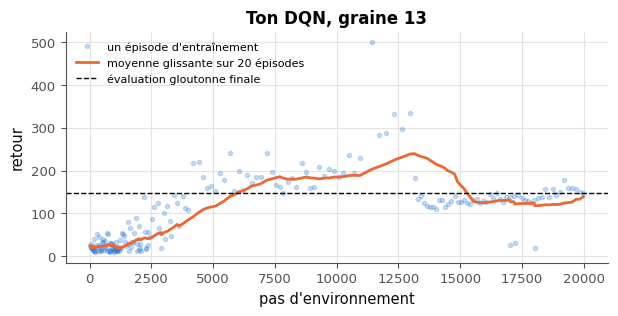

20000 pas en 35 s, 199 épisodes · 20 premiers épisodes : 22,1 · 20 derniers : 138,9 · politique gloutonne sur 100 épisodes : 147,1 (écart-type 2,9)
✅ Ex B8.13 : le retour d'entraînement monte : les 20 derniers épisodes valent au moins le double des 20 premiers.
✅ Ex B8.13 : la politique gloutonne dépasse 55 (la référence, sur 8 graines, fait au moins 93).


In [30]:
if not ok_13:
    print("⏳ Ex B8.13 : l'entraînement complet attend que la vérification ci-dessus passe.")
else:
    with checked("B8.13"):
        start_13 = time.perf_counter()
        Q_NET_13, BUFFER_13, HISTORY_13 = train_dqn_13(wbr.make_env(), SEED_13, STEPS_13)
        seconds_13 = time.perf_counter() - start_13
        returns_13 = np.asarray(HISTORY_13["returns"], dtype=float)
        eval_13 = wbr.evaluate(wbr.greedy_q(Q_NET_13), 100, EVAL_SEED)
        fig_13, ax_13 = plt.subplots(figsize=(7, 3))
        ax_13.plot(HISTORY_13["ends"], returns_13, ".", alpha=0.25, label="un épisode d'entraînement")
        plot_returns(ax_13, returns_13, "moyenne glissante sur 20 épisodes", ends=HISTORY_13["ends"])
        ax_13.axhline(eval_13["mean_return"], color="k", ls="--", lw=1, label="évaluation gloutonne finale")
        ax_13.set(xlabel="pas d'environnement", ylabel="retour", title=f"Ton DQN, graine {SEED_13}")
        ax_13.legend(fontsize=8)
        plt.show()
        print(f"{STEPS_13} pas en {seconds_13:.0f} s, {len(returns_13)} épisodes · 20 premiers épisodes : "
              f"{fr(returns_13[:20].mean(), 1)} · 20 derniers : {fr(returns_13[-20:].mean(), 1)} · politique gloutonne "
              f"sur 100 épisodes : {fr(eval_13['mean_return'], 1)} (écart-type {fr(eval_13['std_return'], 1)})")
        verdict("B8.13", returns_13[-20:].mean() >= 2 * returns_13[:20].mean(),
                "le retour d'entraînement monte : les 20 derniers épisodes valent au moins le double des 20 premiers.",
                "le retour d'entraînement ne monte pas : les 20 derniers épisodes ne valent pas le double des 20 premiers.")
        verdict("B8.13", eval_13["mean_return"] >= THRESHOLD_13,
                f"la politique gloutonne dépasse {THRESHOLD_13:g} (la référence, sur 8 graines, fait au moins "
                f"93).",
                f"la politique gloutonne tient {fr(eval_13['mean_return'], 1)} pas en moyenne : moins que les "
                f"{THRESHOLD_13:g} attendus (la référence, sur 8 graines, fait au moins 93).")

### Ex B8.14 — Le DQN qui diverge : quatre erreurs de cible, de fin d'épisode et d'exploration 🐛 ★★ ⏱️ 30 min
**Objectif :** retrouver par des diagnostics enchaînés les quatre erreurs d'un DQN qui n'apprend rien, sans relancer d'entraînement à chaque essai.  
**Prérequis :** Ex B8.13 · 🐛 26.24 · 🧠 Q3 · fiche §208.1, §208.2 (pièges) · **Fil rouge :** CartPole · **Parcours :** C

Un collègue a écrit un DQN en quatre morceaux : `new_memory(seed)`, la mémoire de rejeu (ta `ReplayBuffer`) ; `remember(...)`, qui range une transition et dit si l'épisode est fini ; `exploration_rate(step)`, le planning d'ε ; `bellman_targets(online, frozen, batch)`, les cibles d'un mini-batch ; et quelques constantes. Sa boucle d'entraînement, `run_colleague_14` (cellule donnée), est juste. Son DQN n'apprend rien : quatre erreurs se sont glissées dans les morceaux, celles du titre. **Répare la cellule suivante en place** (mêmes noms, mêmes signatures).

La cellule de vérification enchaîne quatre diagnostics, chacun sur un morceau, sans entraîner : 1. les cibles d'un mini-batch fixé, avec deux réseaux différents ; 2. ce que `remember` range pour une limite de temps, une vraie fin et un pas ordinaire ; 3. ε à quatre moments du planning ; 4. de quand datent les transitions d'un mini-batch, après 2 000 pas rangés. Le premier qui échoue arrête la chaîne (⏳ pour les suivants) ; un message dit ce qu'il mesure, pas ce qu'il faut changer. La cellule d'expérience entraîne le DQN tel qu'il est (`STEPS_14` pas, une quinzaine de secondes) et trace ses retours, son ε et la moyenne de $\max_a Q$ sur 256 états de départ : lance-la une première fois **avant** de réparer, pour voir les symptômes. Une fois les quatre diagnostics passés, elle vérifie que le DQN réparé apprend (politique gloutonne au-dessus de `THRESHOLD_14`).

Dans tes notes : pour chaque erreur, le symptôme que tu as vu (sur les courbes, puis dans le message) et la ligne fautive. Lesquelles se voyaient sur les courbes, et lesquelles seulement dans un diagnostic ? Pourquoi un diagnostic par morceau plutôt qu'un entraînement complet après chaque correction ? Laquelle de ces erreurs garderait un DQN qui « apprend un peu » ?

In [31]:
STEPS_14 = 8_000 if FAST_MODE else 20_000
THRESHOLD_14 = 90       # the greedy evaluation of the repaired DQN (calibrated on 5 seeds of the repair)


def run_colleague_14(seed, total_steps):
    """The training loop of the colleague (right as it is): it calls new_memory, remember, exploration_rate and
    bellman_targets and the constants of the cell below. Returns (online, log): log["returns"] and log["ends"] (the
    finished episodes), log["eps"] (ε every 100 steps) and log["q_mean"] (the mean of max Q over 256 fixed states,
    every 500 steps)."""
    torch.manual_seed(seed)
    online = wbr.q_network(64)
    frozen = copy.deepcopy(online)
    optimizer = torch.optim.Adam(online.parameters(), lr=LEARNING_RATE)
    rng = np.random.default_rng(seed)
    memory = new_memory(seed)
    env = wbr.make_env()
    obs, _ = env.reset(seed=seed)
    probe = torch.as_tensor(np.random.default_rng(14).uniform(-0.05, 0.05, (256, 4)), dtype=torch.float32)
    log = {"returns": [], "ends": [], "eps": [], "q_mean": []}
    episode_return = 0.0
    for step in range(total_steps):
        eps = exploration_rate(step)
        if step % 100 == 0:
            log["eps"].append(float(eps))
        if rng.random() < eps:
            action = int(rng.integers(2))
        else:
            with torch.no_grad():
                action = int(online(torch.as_tensor(obs).unsqueeze(0)).argmax(dim=1))
        next_obs, reward, term, trunc, _ = env.step(action)
        over = remember(memory, obs, action, reward, next_obs, term, trunc)
        episode_return += reward
        obs = next_obs
        if over:
            log["returns"].append(episode_return)
            log["ends"].append(step + 1)
            episode_return = 0.0
            obs, _ = env.reset()
        if step >= 500 and len(memory) >= MINI_BATCH:
            batch = memory.sample(MINI_BATCH)
            y = bellman_targets(online, frozen, batch)
            q_sa = online(torch.as_tensor(batch["states"])).gather(1, torch.as_tensor(batch["actions"])[:, None])
            loss = F.huber_loss(q_sa.squeeze(1), y)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(online.parameters(), 10.0)
            optimizer.step()
        if (step + 1) % 500 == 0:
            frozen.load_state_dict(online.state_dict())
            with torch.no_grad():
                log["q_mean"].append(float(online(probe).max(dim=1).values.mean()))
    return online, log


class _SpyMemory_14:
    """Records what remember stores (point 2), without a real memory."""

    def __init__(self):
        self.pushed = []

    def push(self, state, action, reward, next_state, terminated):
        self.pushed.append(terminated)


def diagnose_14():
    """Four diagnoses of the colleague's pieces, in a row: the first that fails stops the chain. True when they pass."""
    rng = np.random.default_rng(140)
    states = rng.uniform(-0.1, 0.1, (5, 4)).astype(np.float32)
    next_states = rng.uniform(-0.1, 0.1, (5, 4)).astype(np.float32)
    batch = {"states": states, "actions": np.array([0, 1, 1, 0, 1]), "rewards": np.ones(5),
             "next_states": next_states, "terminated": np.array([False, False, True, False, False])}

    def point1():
        online, frozen = wbr.q_network(16, seed=1), wbr.q_network(16, seed=2)
        y = bellman_targets(online, frozen, {k: v.copy() for k, v in batch.items()})
        if getattr(y, "requires_grad", False):
            return False, ("les cibles de 5 transitions portent un gradient (requires_grad=True) : loss.backward() "
                           "dériverait aussi à travers elles"), \
                "relis « Apprendre une valeur par régression » (208.1) : qu'est la cible pendant le calcul du gradient ?"
        want = wbr.dqn_targets(online, frozen, torch.as_tensor(next_states), torch.ones(5),
                               torch.as_tensor(batch["terminated"]), DISCOUNT)
        y = torch.as_tensor(y, dtype=torch.float32).reshape(-1)
        if y.shape == want.shape and torch.allclose(y, want, atol=1e-6):
            return True, "les cibles sont constantes pour le gradient et viennent du réseau figé", ""
        moved = wbr.q_network(16, seed=3)
        y_moved = torch.as_tensor(bellman_targets(moved, frozen, {k: v.copy() for k, v in batch.items()})).reshape(-1)
        if y_moved.shape == y.shape and not torch.allclose(y_moved, y):
            return False, (f"les cibles bougent (jusqu'à {fr(float((y_moved - y).abs().max()), 3)}) quand seuls les poids "
                           "du réseau en ligne changent"), \
                "relis « Les deux stabilisateurs » (208.2) : quel réseau calcule la cible, et pourquoi ?"
        return False, f"les cibles s'écartent de r + γ(1 − terminated) max Q(s′, ·)", "relis bellman_targets ligne à ligne"

    def point2():
        cases = [(False, True, "une limite de temps (terminated=False, truncated=True)"),
                 (True, False, "une vraie fin (terminated=True, truncated=False)"),
                 (False, False, "un pas ordinaire")]
        for term, trunc, what in cases:
            spy = _SpyMemory_14()
            over = remember(spy, states[0], 1, 1.0, next_states[0], term, trunc)
            if len(spy.pushed) != 1:
                return False, f"pour {what}, remember range {len(spy.pushed)} transitions au lieu d'une", \
                    "relis remember"
            if bool(over) != (term or trunc):
                return False, (f"pour {what}, remember rend {bool(over)} : la boucle " +
                               ("ne remettrait pas l'environnement à zéro" if term or trunc else
                                "remettrait l'environnement à zéro en plein épisode")), "relis sa docstring"
            if bool(spy.pushed[0]) != term:
                return False, (f"{what} entre dans la mémoire avec le drapeau de fin {bool(spy.pushed[0])}" +
                               (" : sa cible n'amorcera pas sur l'état suivant" if trunc else "")), \
                    "relis l'encadré ⚠️ « la limite de temps n'est pas une fin » (208.2)"
        return True, "seule une vraie fin entre dans la mémoire comme une fin ; les deux fins remettent à zéro", ""

    def point3():
        steps = [0, EPS_STEPS // 2, EPS_STEPS, 2 * EPS_STEPS]
        got = [float(exploration_rate(k)) for k in steps]
        want = [wbr.linear_epsilon(k, EPS_STEPS, EPS_FIRST, EPS_LAST, 1.0) for k in steps]
        if np.allclose(got, want, atol=1e-9):
            return True, f"ε passe de {fr(got[0], 2)} à {fr(got[2], 2)} en {EPS_STEPS} pas", ""
        shown = ", ".join(f"{fr(v, 3)} au pas {k}" for v, k in zip(got, steps))
        if max(got) - min(got) < 1e-9:
            return False, f"ε vaut {shown} : la politique ne quitte jamais le même niveau d'exploration", \
                "que doit valoir ε à la fin annoncée par la docstring ?"
        return False, f"ε vaut {shown}, ce qui ne suit pas la docstring", "relis exploration_rate ligne à ligne"

    def point4():
        memory = new_memory(0)
        for k in range(2000):
            memory.push(np.array([k, 0, 0, 0], np.float32), 0, 1.0, np.array([k + 1, 0, 0, 0], np.float32), False)
        drawn = np.concatenate([memory.sample(MINI_BATCH)["states"][:, 0] for _ in range(20)])
        recent = float(np.mean(drawn >= 1900))
        if recent <= 0.5:
            return True, (f"après 2 000 pas, {fr(100 * recent, 0)} % des transitions tirées datent des 100 derniers pas "
                          "(les mini-batches mêlent des moments éloignés)"), ""
        return False, (f"après 2 000 pas, {fr(100 * recent, 0)} % des transitions de 20 mini-batches de {MINI_BATCH} "
                       "datent des 100 derniers pas, soit deux épisodes d'un agent qui tient 50 pas : chaque mini-batch "
                       "reste fait de pas qui se suivent"), \
            "relis « Ces nombres montrent surtout… » (208.2) et 🧠 Q3 : que doit garder la mémoire ?"

    points = [("la cible", point1), ("les fins d'épisode", point2), ("l'exploration", point3), ("la mémoire", point4)]
    for k, (name, run) in enumerate(points, start=1):
        try:
            ok, measured, why = run()
        except NotImplementedError as error:
            print(f"⏳ Ex B8.14 : point {k}, {name} : pas encore fait ({error}) : la mémoire est ta ReplayBuffer "
                  "(rl.py, Ex 26.31).")
            return False
        except Exception as error:  # noqa: BLE001 - the colleague's code, as repaired: one ❌ line, the chain stops
            ok, measured, why = False, f"une erreur {type(error).__name__} : {str(error)[:200]}", "relis la fonction en cause"
        if ok:
            print(f"✅ Ex B8.14 : point {k}, {name} ({measured}).")
        else:
            print(f"❌ Ex B8.14 : point {k}, {name} : {measured} ; {why}")
            for later in range(k + 1, len(points) + 1):
                print(f"⏳ Ex B8.14 : point {later} : corrige d'abord le point {k}.")
            return False
    print("✅ Ex B8.14 : les quatre diagnostics passent.")
    return True

In [32]:
# The DQN of the colleague, repaired: four changes, numbered in the comments
LEARNING_RATE = 5e-4
MINI_BATCH = 64
MEMORY_SLOTS = 10_000                  # 4. a memory of many episodes
DISCOUNT = 0.99
EPS_FIRST, EPS_LAST, EPS_STEPS = 1.0, 0.05, 3_000


def new_memory(seed):
    """The replay memory of the agent: your mylearn.rl.ReplayBuffer, for CartPole observations."""
    return mylearn.rl.ReplayBuffer(MEMORY_SLOTS, obs_shape=(4,), obs_dtype="float32", random_state=seed)


def remember(memory, obs, action, reward, next_obs, term, trunc):
    """Store one transition in the memory; return True when the episode is over (the loop then resets the env)."""
    finished = term | trunc
    memory.push(obs, action, reward, next_obs, term)           # 2. a time limit is not an end
    return finished


def exploration_rate(step):
    """ε of a step: from EPS_FIRST down to EPS_LAST, linearly over the first EPS_STEPS steps, then EPS_LAST."""
    weight = max(0.0, 1.0 - step / EPS_STEPS)          # 1 at the start, 0 after EPS_STEPS steps
    return weight * EPS_FIRST + (1.0 - weight) * EPS_LAST    # 3. the end of the schedule


def bellman_targets(online, frozen, batch):
    """The targets of a mini-batch (the dict of memory.sample), a tensor (B,):
    y = r + DISCOUNT (1 - terminated) max_a' Q_frozen(s', a'), a constant for the gradient."""
    rewards = torch.as_tensor(batch["rewards"], dtype=torch.float32)
    alive = 1.0 - torch.as_tensor(batch["terminated"], dtype=torch.float32)
    with torch.no_grad():                                   # 1. the frozen network, no gradient
        follow = frozen(torch.as_tensor(batch["next_states"])).max(dim=1).values
    return rewards + DISCOUNT * alive * follow


repaired_14_ok = False
with checked("B8.14"):
    repaired_14_ok = diagnose_14()

✅ Ex B8.14 : point 1, la cible (les cibles sont constantes pour le gradient et viennent du réseau figé).
✅ Ex B8.14 : point 2, les fins d'épisode (seule une vraie fin entre dans la mémoire comme une fin ; les deux fins remettent à zéro).
✅ Ex B8.14 : point 3, l'exploration (ε passe de 1,00 à 0,05 en 3000 pas).
✅ Ex B8.14 : point 4, la mémoire (après 2 000 pas, 4 % des transitions tirées datent des 100 derniers pas (les mini-batches mêlent des moments éloignés)).
✅ Ex B8.14 : les quatre diagnostics passent.


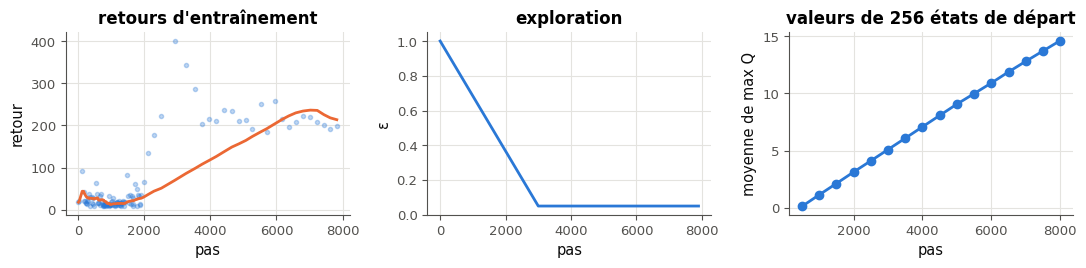

8000 pas en 15 s, 120 épisodes · politique gloutonne sur 100 épisodes : 201,3 · max Q moyen à la fin : 14,6
✅ Ex B8.14 : réparé, le DQN apprend : sa politique gloutonne dépasse 90.


In [33]:
# The colleague's DQN as it is now (before the repair: its symptoms; after: the repaired agent), STEPS_14 steps
with checked("B8.14"):
    start_14 = time.perf_counter()
    online_14, log_14 = run_colleague_14(0, STEPS_14)
    eval_14 = wbr.evaluate(wbr.greedy_q(online_14), 100, EVAL_SEED)
    fig_14, axes_14 = plt.subplots(1, 3, figsize=(11, 2.8))
    if log_14["returns"]:
        axes_14[0].plot(log_14["ends"], log_14["returns"], ".", alpha=0.3)
        plot_returns(axes_14[0], log_14["returns"], "moyenne sur 20", ends=log_14["ends"])
    axes_14[0].set(xlabel="pas", ylabel="retour", title="retours d'entraînement")
    axes_14[1].plot(np.arange(len(log_14["eps"])) * 100, log_14["eps"])
    axes_14[1].set(xlabel="pas", ylabel="ε", title="exploration", ylim=(0, 1.05))
    axes_14[2].plot(np.arange(1, len(log_14["q_mean"]) + 1) * 500, log_14["q_mean"], marker="o")
    axes_14[2].set(xlabel="pas", ylabel="moyenne de max Q", title="valeurs de 256 états de départ")
    plt.tight_layout()
    plt.show()
    print(f"{STEPS_14} pas en {time.perf_counter() - start_14:.0f} s, {len(log_14['returns'])} épisodes · politique "
          f"gloutonne sur 100 épisodes : {fr(eval_14['mean_return'], 1)} · max Q moyen à la fin : "
          f"{fr(log_14['q_mean'][-1], 1) if log_14['q_mean'] else '?'}")
    if repaired_14_ok:
        verdict("B8.14", eval_14["mean_return"] >= THRESHOLD_14,
                f"réparé, le DQN apprend : sa politique gloutonne dépasse {THRESHOLD_14:g}.",
                f"les quatre diagnostics passent, mais la politique gloutonne ne tient que {fr(eval_14['mean_return'], 1)} "
                f"pas (au moins {THRESHOLD_14:g} attendus) : as-tu changé autre chose que les quatre erreurs ?")
    else:
        print("⏳ Ex B8.14 : ces courbes montrent le DQN tel qu'il est ; la vérification ci-dessus dit ce qui reste.")

### Ex B8.15 — Ablations du DQN : sans réseau cible, sans rejeu, avec Double DQN — trois graines 🔬 ★★★ ⏱️ 50 min 🚀
**Objectif :** mesurer sur trois graines ce que le réseau cible, le rejeu et Double DQN changent à l'apprentissage, et rapporter la dispersion avec le résultat.  
**Prérequis :** Ex B8.13 · ✏️ B8.1 · fiche §208.2 (« La surestimation, et Double DQN »), §208.6 (« Les graines », « Rapporter plusieurs graines ») · **Fil rouge :** CartPole · **Parcours :** C

Quatre variantes du DQN de B8.13 : `"dqn"` ; `"no_target"`, **sans réseau cible** (les cibles viennent du réseau en ligne, toujours sans gradient) ; `"no_replay"`, **sans rejeu** (une mémoire de `batch_size` transitions : chaque mini-batch est fait des derniers pas, dans le désordre) ; `"double"`, **Double DQN**. **Contrat** des deux morceaux de la cellule suivante :
- `targets_15(online, frozen, next_states, rewards, terminated, gamma, variant)` rend les cibles d'un mini-batch pour une variante, un tenseur `(B,)` sans gradient : celles de `dqn_targets_13` avec le réseau cible `frozen` pour `"dqn"` et `"no_replay"` ; la même formule avec le réseau en ligne pour `"no_target"` ; pour `"double"`, l'action choisie par le réseau en ligne (`argmax`) et sa valeur lue dans `frozen` ;
- `memory_size_15(variant, settings=SETTINGS_13)` rend la capacité de la mémoire : `settings["capacity"]`, sauf `settings["batch_size"]` pour `"no_replay"`.

La vérification compare tes cibles à celles de la référence sur 6 transitions (deux réseaux qui ne choisissent pas toujours la même action), pour les quatre variantes. Puis l'expérience : en **mode rapide**, les courbes viennent d'un fichier précalculé (`wbr.precomputed("a15")`) : le DQN de référence du chapitre, 20 000 pas, trois graines par variante, la politique gloutonne évaluée tous les 1 000 pas sur 20 épisodes ; la cellule rejoue d'abord les 3 000 premiers pas d'une des courbes (Double DQN, première graine) pour vérifier qu'elle retombe sur le fichier. En **mode complet** 🚀 (`FAST_MODE = False`), elle relance tout avec tes deux morceaux dans la boucle de référence : 50 000 pas, trois graines par variante, environ 20 minutes de CPU. La figure trace la **médiane** des trois graines et leur **intervalle** (du minimum au maximum) ; un tableau donne la dernière évaluation de chaque graine.

Dans tes notes : quelle variante t'a surpris ? Les intervalles se recouvrent-ils, et que peux-tu conclure avec trois graines seulement (208.6, rliable) ? Pourquoi « sans rejeu » est-il ici une mémoire de 64 transitions plutôt qu'aucune mémoire, et que mesure-t-on alors ? Que faudrait-il pour affirmer qu'une variante est meilleure ?

In [34]:
VARIANTS_15 = wbr.DQN_VARIANTS                 # ("dqn", "no_target", "no_replay", "double")
NAMES_15 = {"dqn": "DQN", "no_target": "sans réseau cible", "no_replay": "sans rejeu", "double": "Double DQN"}
A15 = wbr.precomputed("a15")                   # the curves of the reference: 4 variants x 3 seeds (protocol inside)
REPLAY_STEPS_15 = 3_000                        # the prefix of one recorded run that this notebook trains again

In [35]:
def targets_15(online, frozen, next_states, rewards, terminated, gamma, variant):
    """The targets of a mini-batch for the four variants, a tensor (B,) without gradient: "dqn" and "no_replay", those of
    dqn_targets_13 with the target network `frozen`; "no_target", the same formula with the online network in place of
    the target network; "double", the action chosen by the online network (argmax), its value read in `frozen`."""
    with torch.no_grad():
        if variant == "double":
            best = online(next_states).argmax(dim=1, keepdim=True)        # the online network chooses...
            following = frozen(next_states).gather(1, best).squeeze(1)    # ...the target network values it
        else:
            following = (online if variant == "no_target" else frozen)(next_states).max(dim=1).values
        return rewards + gamma * (1.0 - terminated.float()) * following


def memory_size_15(variant, settings=SETTINGS_13):
    """The capacity of the replay memory of a variant: settings["capacity"], except for "no_replay":
    settings["batch_size"] (each mini-batch is then the last batch_size transitions, in a random order)."""
    return settings["batch_size"] if variant == "no_replay" else settings["capacity"]


ok_15 = False
with checked("B8.15"):
    online_15, frozen_15 = wbr.q_network(32, seed=150), wbr.q_network(32, seed=151)
    next_15 = torch.as_tensor(np.random.default_rng(15).normal(0, 1, (6, 4)), dtype=torch.float32)
    rewards_15 = torch.tensor([1.0, 1.0, 0.5, 1.0, -1.0, 1.0])
    term_15 = torch.tensor([False, True, False, False, False, False])
    with torch.no_grad():
        disagree_15 = int((online_15(next_15).argmax(1) != frozen_15(next_15).argmax(1)).sum())
    good_15 = []
    for variant_15 in VARIANTS_15:
        y_15 = targets_15(online_15, frozen_15, next_15.clone(), rewards_15.clone(), term_15.clone(), 0.99, variant_15)
        if not returned("B8.15", f"targets_15(..., {variant_15!r})", y_15):
            good_15.append(False)
            continue
        if getattr(y_15, "requires_grad", False):
            print(f"❌ Ex B8.15 : targets_15(..., {variant_15!r}) porte un gradient (requires_grad=True).")
            good_15.append(False)
            continue
        good_15.append(same("B8.15", f"targets_15, variante {variant_15!r} (6 transitions, la 2ᵉ terminée)", y_15,
                            wbr.dqn_targets(online_15, frozen_15, next_15, rewards_15, term_15, 0.99, variant_15),
                            rtol=1e-6, atol=1e-6))
    sizes_15 = {v: memory_size_15(v) for v in VARIANTS_15}
    want_sizes_15 = {v: (SETTINGS_13["batch_size"] if v == "no_replay" else SETTINGS_13["capacity"]) for v in VARIANTS_15}
    good_15.append(sizes_15 == want_sizes_15)
    verdict("B8.15", good_15[-1], f"memory_size_15 : {sizes_15}.",
            f"memory_size_15 : attendu {want_sizes_15}, reçu {sizes_15}.")
    print(f"(le réseau en ligne et le réseau cible de la vérification choisissent une autre action dans "
          f"{disagree_15} des 6 états s′ : Double DQN y diffère de DQN)")
    ok_15 = all(good_15)

✅ Ex B8.15 : targets_15, variante 'dqn' (6 transitions, la 2ᵉ terminée) : [1.33812773, 1.0, 0.74472386, 1.15484917, -0.72865069, 1.30890572], comme attendu.
✅ Ex B8.15 : targets_15, variante 'no_target' (6 transitions, la 2ᵉ terminée) : [1.14829445, 1.0, 0.60892338, 1.18853807, -0.86468351, 1.24454391], comme attendu.
✅ Ex B8.15 : targets_15, variante 'no_replay' (6 transitions, la 2ᵉ terminée) : [1.33812773, 1.0, 0.74472386, 1.15484917, -0.72865069, 1.30890572], comme attendu.
✅ Ex B8.15 : targets_15, variante 'double' (6 transitions, la 2ᵉ terminée) : [0.79146475, 1.0, 0.40241674, 0.89320302, -1.10958409, 0.81853616], comme attendu.
✅ Ex B8.15 : memory_size_15 : {'dqn': 10000, 'no_target': 10000, 'no_replay': 128, 'double': 10000}.
(le réseau en ligne et le réseau cible de la vérification choisissent une autre action dans 6 des 6 états s′ : Double DQN y diffère de DQN)


✅ Ex B8.15 : Double DQN, graine 0, rejoué sur 3000 pas : [9.55, 9.5, 239.4], comme dans le fichier : les courbes ci-dessous sont celles de ce code.


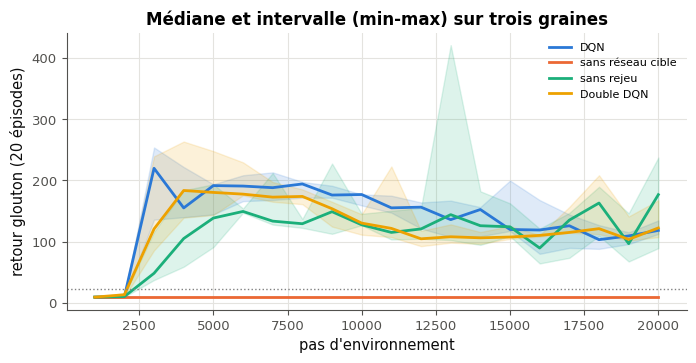

DQN                dernière évaluation par graine : [134.7, 118.3, 112.5] · médiane 118,3
sans réseau cible  dernière évaluation par graine : [9.6, 9.2, 9.2] · médiane 9,2
sans rejeu         dernière évaluation par graine : [89.3, 176.8, 237.5] · médiane 176,8
Double DQN         dernière évaluation par graine : [167.6, 107.4, 122.3] · médiane 122,3


In [36]:
# The four variants on three seeds (fast mode: the curves of the reference, precomputed; full mode: your pieces in the
# reference loop, 3 seeds x 4 variants, 🚀), then the median and the range of the three seeds
protocol_15 = A15["protocol"]
if FAST_MODE:
    runs_15 = A15["runs"]
    replay_15, replay_hist_15 = wbr.train_dqn(protocol_15["seeds"][0], protocol_15["steps"], variant="double",
                                              eval_every=protocol_15["eval_every"],
                                              eval_episodes=protocol_15["eval_episodes"],
                                              eval_seed=protocol_15["eval_seed"], stop_after=REPLAY_STEPS_15)
    recorded_15 = runs_15[f"double/{protocol_15['seeds'][0]}"]["eval_returns"][:len(replay_hist_15["eval_returns"])]
    if np.allclose(replay_hist_15["eval_returns"], recorded_15, atol=1e-6):
        print(f"✅ Ex B8.15 : Double DQN, graine {protocol_15['seeds'][0]}, rejoué sur {REPLAY_STEPS_15} pas : "
              f"{replay_hist_15['eval_returns']}, comme dans le fichier : les courbes ci-dessous sont celles de ce code.")
    else:
        print(f"ℹ️ Double DQN, graine {protocol_15['seeds'][0]}, rejoué sur {REPLAY_STEPS_15} pas : "
              f"{replay_hist_15['eval_returns']}, le fichier dit {recorded_15} : une autre machine ou une autre version "
              "de PyTorch arrondit autrement, et un écart minuscule change la suite d'un run de RL (208.6). Les courbes "
              "ci-dessous restent celles du fichier.")
elif not ok_15:
    runs_15 = None
    print("⏳ Ex B8.15 : le mode complet entraîne tes variantes ; il attend que la vérification ci-dessus passe.")
else:
    runs_15 = {}
    for variant_15 in VARIANTS_15:
        for seed_15 in protocol_15["seeds"]:
            _, h_15 = wbr.train_dqn(seed_15, wbr.dqn_steps(False), variant=variant_15, eval_every=2_500,
                                    eval_episodes=protocol_15["eval_episodes"], eval_seed=protocol_15["eval_seed"],
                                    targets_fn=targets_15, capacity=memory_size_15(variant_15))
            runs_15[f"{variant_15}/{seed_15}"] = h_15
            print(f"{NAMES_15[variant_15]}, graine {seed_15} : {h_15['seconds']:.0f} s")
if runs_15:
    fig_15, ax_15 = plt.subplots(figsize=(8, 3.6))
    finals_15 = {}
    for variant_15 in VARIANTS_15:
        hs_15 = [runs_15[f"{variant_15}/{s}"] for s in protocol_15["seeds"]]
        steps_15 = hs_15[0]["eval_steps"]
        b_15 = wbr.band([h["eval_returns"] for h in hs_15])
        line_15, = ax_15.plot(steps_15, b_15["median"], label=NAMES_15[variant_15])
        ax_15.fill_between(steps_15, b_15["low"], b_15["high"], color=line_15.get_color(), alpha=0.15)
        finals_15[variant_15] = [h["eval_returns"][-1] for h in hs_15]
    ax_15.axhline(RANDOM_LEVEL, color="gray", ls=":", lw=1)
    ax_15.set(xlabel="pas d'environnement", ylabel="retour glouton (20 épisodes)",
              title="Médiane et intervalle (min-max) sur trois graines")
    ax_15.legend(fontsize=8)
    plt.show()
    for variant_15, values_15 in finals_15.items():
        print(f"{NAMES_15[variant_15]:18s} dernière évaluation par graine : {[round(v, 1) for v in values_15]} · "
              f"médiane {fr(float(np.median(values_15)), 1)}")

## Partie B · La politique : REINFORCE, GAE et PPO

Tu changes de famille : au lieu d'apprendre $Q$ et d'en déduire la politique, tu ajustes **directement** les probabilités des actions. Tu prédis d'abord ce que change une baseline à REINFORCE (B8.16), tu le mesures sur le gradient et sur l'apprentissage (B8.17), tu écris dans ta librairie les deux calculs que les implémentations ratent le plus souvent, GAE et l'objectif clippé (B8.18, B8.19), puis tu assembles ton PPO sur des environnements vectorisés (B8.20). La suite de la partie lit ses journaux, règle ses hyperparamètres et teste sa robustesse.

### Ex B8.16 — Prédire : REINFORCE sans baseline, avec baseline, avec retours normalisés — lequel apprend le plus vite ? 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, avant de les voir, ce que la baseline et la normalisation des retours changent à REINFORCE sur CartPole.  
**Prérequis :** ∂ B8.7 · 🧠 Q6 · fiche §208.3 (« REINFORCE », « La baseline et la variance ») · **Fil rouge :** CartPole · **Parcours :** C

Trois variantes de REINFORCE, une mise à jour (un pas d'Adam, learning rate $10^{-2}$) par épisode, $\gamma = 0{,}99$, la politique 4 → 64 → 2 (tanh), 300 épisodes : **sans baseline** (le poids de $\log\pi(a_t \mid s_t)$ est $G_t$) ; avec une **baseline moyenne** ($G_t - b$, $b$ la moyenne des $G_t$ des 20 épisodes précédents, 0 au premier) ; avec des **retours normalisés** ($(G_t - \bar G)/\sigma_G$ sur l'épisode). Chacune a été entraînée avec six graines (le fichier `wbr.precomputed("p16")`, lu par l'expérience). La fiche dit seulement qu'une baseline ne biaise pas le gradient et réduit sa variance sur un **bandit jouet** ; ici, c'est CartPole. **Avant d'exécuter**, écris tes trois prédictions :
- a) `best_16` : laquelle des trois variantes a la plus grande **médiane**, sur les six graines, du retour moyen de ses 50 derniers épisodes ? `0` sans baseline, `1` la baseline moyenne, `2` les retours normalisés ;
- b) `first_200_16` : sur combien des six graines la variante **sans baseline** atteint-elle, au moins une fois, une moyenne glissante de 200 (sur 20 épisodes) en 300 épisodes ? Un entier de 0 à 6 ;
- c) `beats_16` : la baseline moyenne finit-elle **au-dessus** de la variante sans baseline (50 derniers épisodes) sur **chacune** des six graines ? `True` ou `False`.

La cellule d'expérience n'affiche rien tant que tes trois prédictions ne sont pas écrites ; elle trace ensuite la médiane et l'intervalle des six graines pour chaque variante, donne les valeurs par graine et vérifie tes prédictions. Rien n'y dépend de ton code.

Dans tes notes, avant d'exécuter : sur CartPole, tous les retours $G_t$ sont positifs ; que fait alors REINFORCE sans baseline à **chaque** action jouée ? Qu'est-ce qui distingue la normalisation d'une simple baseline ?

In [37]:
best_16, first_200_16, beats_16 = 1, 5, True

In [38]:
wb.record("B8.16a", 1, choices=[0, 1, 2], mistakes={"lis la médiane de chaque variante sous la figure": {0, 2}}, prediction=True,
          fractional="la réponse est le numéro d'une variante : 0, 1 ou 2")
wb.record("B8.16b", 5, choices=list(range(7)), mistakes={"compte, ligne « sans baseline », les graines où la moyenne glissante atteint 200": {0, 1, 2, 3, 4, 6}}, prediction=True,
          fractional="la réponse est un nombre de graines, de 0 à 6")
wb.record("B8.16c", True, mistakes={"compare, graine par graine, les 50 derniers épisodes avec et sans baseline": False}, prediction=True)

WB_ANSWER {"choices": ["0", "1", "2"], "fractional": "la réponse est le numéro d'une variante : 0, 1 ou 2", "hash": "cfebcf0acbb6a2b802da13eed1b7fe4008e45ff0eb2950996bad56022f73d8c1", "id": "B8.16a", "kind": "int", "magnitude": 0, "mistakes": {"1f3b3bc1d646703619ad51687745a70d39d744a3cb4184cadb9541e7405cb141": "lis la médiane de chaque variante sous la figure", "375bdebcb5833e42daee1a99d39a527d57efe7831d9edd2709dd74435b617217": "lis la médiane de chaque variante sous la figure"}, "prediction": true, "sign": 1}
📝 Ex B8.16a : réponse enregistrée (int).
WB_ANSWER {"choices": ["0", "1", "2", "3", "4", "5", "6"], "fractional": "la réponse est un nombre de graines, de 0 à 6", "hash": "d8420435e98741a9de174e7c39e0d1ccbae11bb7e9bb6859f9cdb40c222d5c1e", "id": "B8.16b", "kind": "int", "magnitude": 0, "mistakes": {"2139111104fb25e9076e78afa73e2d980828089f059de4c4bfefeed4546c2c67": "compte, ligne « sans baseline », les graines où la moyenne glissante atteint 200", "255b4f00cf0c549b55a751756db8bf11

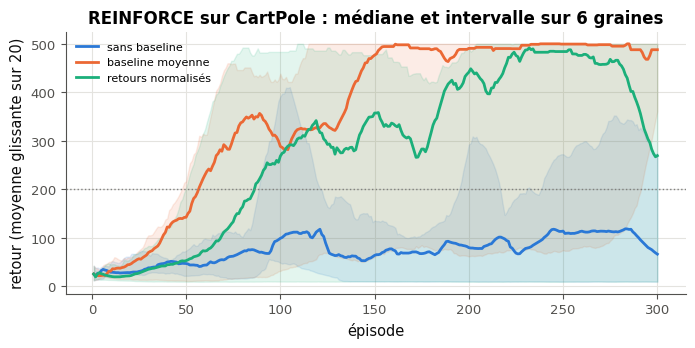

sans baseline        moyenne des 50 derniers épisodes, par graine : [138, 301, 124, 15, 120, 9] · médiane 121,6 · moyenne glissante ≥ 200 atteinte sur 5 graines sur 6
baseline moyenne     moyenne des 50 derniers épisodes, par graine : [499, 500, 448, 490, 203, 484] · médiane 487,2 · moyenne glissante ≥ 200 atteinte sur 6 graines sur 6
retours normalisés   moyenne des 50 derniers épisodes, par graine : [472, 355, 144, 500, 9, 425] · médiane 390,0 · moyenne glissante ≥ 200 atteinte sur 5 graines sur 6
✅ Ex B8.16a : C'est ça !
✅ Ex B8.16b : Parfait !
✅ Ex B8.16c : Bravo !


In [39]:
if any(answer is ... or answer is None for answer in [best_16, first_200_16, beats_16]):
    print("⏳ Ex B8.16 : écris d'abord tes trois prédictions (best_16, first_200_16, beats_16) dans la cellule précédente.")
else:
    P16 = wbr.precomputed("p16")                  # REINFORCE, 3 variants x 6 seeds x 300 episodes (protocol inside)
    names_16 = {"none": "sans baseline", "mean": "baseline moyenne", "normalize": "retours normalisés"}
    seeds_16 = P16["protocol"]["seeds"]
    fig_16, ax_16 = plt.subplots(figsize=(8, 3.4))
    last50_16 = {}
    for baseline_16, name_16 in names_16.items():
        curves_16 = [wbr.moving_average(P16["runs"][f"{baseline_16}/{s}"]["episode_returns"], 20) for s in seeds_16]
        b_16 = wbr.band(curves_16)
        line_16, = ax_16.plot(np.arange(1, 301), b_16["median"], label=name_16)
        ax_16.fill_between(np.arange(1, 301), b_16["low"], b_16["high"], color=line_16.get_color(), alpha=0.12)
        last50_16[baseline_16] = [float(np.mean(P16["runs"][f"{baseline_16}/{s}"]["episode_returns"][-50:])) for s in seeds_16]
    ax_16.axhline(200, color="gray", ls=":", lw=1)
    ax_16.set(xlabel="épisode", ylabel="retour (moyenne glissante sur 20)",
              title=f"REINFORCE sur CartPole : médiane et intervalle sur {len(seeds_16)} graines")
    ax_16.legend(fontsize=8)
    plt.show()
    for baseline_16, name_16 in names_16.items():
        reached_16 = sum(bool((wbr.moving_average(P16["runs"][f"{baseline_16}/{s}"]["episode_returns"], 20) >= 200).any())
                         for s in seeds_16)
        print(f"{name_16:20s} moyenne des 50 derniers épisodes, par graine : {[round(v) for v in last50_16[baseline_16]]} · "
              f"médiane {fr(float(np.median(last50_16[baseline_16])), 1)} · moyenne glissante ≥ 200 atteinte sur "
              f"{reached_16} graines sur {len(seeds_16)}")
    wb.check("B8.16a", best_16)
    wb.check("B8.16b", first_200_16)
    wb.check("B8.16c", beats_16)

Dans tes notes, après l'expérience : la dispersion d'une graine à l'autre est-elle plus grande pour une variante que pour les autres ? Une seule graine aurait-elle suffi à répondre à a) ? Qu'est-ce qui, dans la figure, relève de la **variance** du gradient et qu'est-ce qui relève de l'**échelle** des pas ?

### Ex B8.17 — REINFORCE avec et sans baseline : variance du gradient et vitesse d'apprentissage 📦 ★★★ ⏱️ 45 min
**Objectif :** écrire REINFORCE en PyTorch, mesurer la dispersion de son gradient avec et sans baseline, et relier cette dispersion à la vitesse d'apprentissage.  
**Prérequis :** 🔮 B8.16 · 🔨 26.14 (`returns_to_go`) · ∂ B8.7 · fiche §208.3 · **Fil rouge :** CartPole · **Parcours :** C

**Contrat** des trois fonctions de la cellule suivante :
- `make_policy_17(hidden=64)` rend un `nn.Module` neuf : 4 entrées, une couche cachée de `hidden` neurones avec tanh, 2 sorties (les logits des deux actions) ;
- `episode_gradients_17(policy_net, episodes, baseline, gamma=0.99)` rend un tableau NumPy float64 de forme `(M, P)` : la ligne $i$ est le gradient, par rapport à **tous** les paramètres de `policy_net` mis bout à bout dans l'ordre de `policy_net.parameters()` (`P` nombres), de la loss de l'épisode $i$, $-\frac{1}{T}\sum_t \log\pi(a_t \mid s_t)\,(G_t - b)$. `episodes` est une liste de $M$ dictionnaires `"states"` (float32 `(T, 4)`), `"actions"` (int64 `(T,)`) et `"rewards"` (`(T,)`) ; $G_t$ vient de `mylearn.rl.returns_to_go` (ta fonction de 26.14) ; $b = 0$ pour `"none"`, et pour `"mean"` la moyenne des $G_t$ de **tous** les épisodes donnés (une seule constante) ;
- `train_reinforce_17(seed, n_episodes, baseline, lr=1e-2, gamma=0.99)` entraîne REINFORCE sur CartPole-v1 (`wbr.make_env()`) et rend le couple `(policy_net, returns)`, `returns` la liste des retours des `n_episodes` épisodes d'entraînement : `torch.manual_seed(seed)` puis `make_policy_17()` ; `env.reset(seed=seed)` une fois au départ ; chaque épisode joué en entier avec des actions **tirées** dans la politique (`torch.distributions.Categorical`) ; puis un pas d'Adam (`lr`) sur la loss de l'épisode, avec $b = 0$ (`"none"`) ou $b$ la moyenne des $G_t$ des 20 épisodes **précédents** (`"mean"`, 0 au premier épisode).

La cellule donnée fixe deux politiques (une non entraînée ; une entraînée 60 épisodes par la référence, ses poids relus) et 32 épisodes joués par chacune (`EPISODES_17`). La vérification compare tes gradients par épisode à ceux de la référence, pour les deux politiques et les deux baselines, puis affiche leur **dispersion**, $\frac{1}{M}\sum_i \lVert g_i - \bar g\rVert^2$ (`wbr.gradient_spread`), avec et sans baseline. La cellule suivante entraîne ta REINFORCE sans puis avec baseline (300 épisodes chacune, environ une minute : les épisodes longs coûtent) et trace tes courbes sur l'intervalle des six graines de la référence (le protocole de B8.16) ; elle attend qu'avec la baseline, tes 50 derniers épisodes dépassent `THRESHOLD_17`.

Dans tes notes : de combien la baseline réduit-elle la dispersion pour chacune des deux politiques, et pourquoi si peu pour l'une d'elles (pense à la longueur des épisodes et à la taille des $G_t$) ? Une baseline **constante** peut-elle augmenter la variance ? Le gradient moyen change-t-il avec la baseline (∂ B8.7), et le vois-tu sur 32 épisodes ? Ta courbe tombe-t-elle dans l'intervalle de la référence ?

In [40]:
C17 = wbr.precomputed("c17")                  # a policy trained 60 episodes by the reference (its weights)
HALF_TRAINED_17 = wbr.policy_network(64)
HALF_TRAINED_17.load_state_dict({k: torch.tensor(v) for k, v in C17["state_dict"].items()})
POLICIES_17 = {"non entraînée": wbr.policy_network(64, seed=17), "entraînée 60 épisodes": HALF_TRAINED_17}
EPISODES_17 = {name: wbr.collect_episodes(net, 32, 1700) for name, net in POLICIES_17.items()}   # 32 episodes each
N_17 = 300                                       # training episodes of each variant (B8.16 shows the same protocol)
SEED_17 = 17
THRESHOLD_17 = 100                    # the last 50 episodes with the mean baseline (6 seeds of the reference)
for name_17, eps_17 in EPISODES_17.items():
    print(f"politique {name_17} : 32 épisodes, {fr(np.mean([len(e['rewards']) for e in eps_17]), 1)} pas en moyenne")

politique non entraînée : 32 épisodes, 21,4 pas en moyenne
politique entraînée 60 épisodes : 32 épisodes, 373,3 pas en moyenne


In [41]:
def make_policy_17(hidden=64):
    """A new policy network for CartPole: 4 inputs, one hidden layer of `hidden` neurons with tanh, 2 outputs (the
    logits of the two actions)."""
    return nn.Sequential(nn.Linear(4, hidden), nn.Tanh(), nn.Linear(hidden, 2))


def episode_gradients_17(policy_net, episodes, baseline, gamma=0.99):
    """One REINFORCE gradient per episode (the contract of the statement): a float64 array (M, P), row i the gradient
    of -mean_t(log pi(a_t | s_t) (G_t - b)) of episode i with respect to all the parameters of policy_net, flattened
    in the order of policy_net.parameters(); b = 0 ("none") or the mean of the G_t of ALL the episodes ("mean")."""
    returns = [mylearn.rl.returns_to_go(e["rewards"], gamma) for e in episodes]
    b = float(np.mean(np.concatenate(returns))) if baseline == "mean" else 0.0
    params = list(policy_net.parameters())
    rows = []
    for e, G in zip(episodes, returns):
        log_pi = torch.log_softmax(policy_net(torch.as_tensor(e["states"])), dim=1)
        log_pi_a = log_pi.gather(1, torch.as_tensor(e["actions"])[:, None]).squeeze(1)
        loss = -(log_pi_a * torch.as_tensor(G - b, dtype=torch.float32)).mean()
        grads = torch.autograd.grad(loss, params)                 # leaves the .grad of the network alone
        rows.append(torch.cat([g.reshape(-1) for g in grads]).double().numpy())
    return np.stack(rows)


def train_reinforce_17(seed, n_episodes, baseline, lr=1e-2, gamma=0.99):
    """REINFORCE on CartPole-v1 (the contract of the statement): one Adam step per episode; baseline "none" or "mean"
    (the mean of the G_t of the 20 previous episodes, 0 for the first). Returns (policy_net, returns), the return of
    each training episode."""
    torch.manual_seed(seed)
    policy_net = make_policy_17()
    optimizer = torch.optim.Adam(policy_net.parameters(), lr=lr)
    env = wbr.make_env()
    env.reset(seed=seed)
    past, returns = [], []
    for _ in range(n_episodes):
        state, _ = env.reset()
        log_probs, rewards, done = [], [], False
        while not done:
            dist = torch.distributions.Categorical(logits=policy_net(torch.as_tensor(state)))
            action = dist.sample()
            log_probs.append(dist.log_prob(action))
            state, reward, terminated, truncated, _ = env.step(int(action))
            rewards.append(reward)
            done = terminated or truncated
        G = mylearn.rl.returns_to_go(rewards, gamma)
        b = float(np.mean(np.concatenate(past))) if baseline == "mean" and past else 0.0
        loss = -(torch.stack(log_probs) * torch.as_tensor(G - b, dtype=torch.float32)).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        past = (past + [G])[-20:]
        returns.append(float(sum(rewards)))
    return policy_net, returns


grads_ok_17 = False
with checked("B8.17"):
    net_17 = make_policy_17()
    if returned("B8.17", "make_policy_17", net_17):
        out_17 = net_17(torch.zeros(3, 4)) if isinstance(net_17, nn.Module) else None
        verdict("B8.17", out_17 is not None and tuple(out_17.shape) == (3, 2),
                f"make_policy_17 : {sum(p.numel() for p in net_17.parameters())} paramètres, deux logits par observation.",
                "make_policy_17 : attendu un nn.Module qui rend (3, 2) pour 3 observations.")

with checked("B8.17"):
    if rl_ready("B8.17", "returns_to_go"):
        for name_17, net_17 in POLICIES_17.items():
            for baseline_17 in ("none", "mean"):
                copy_17 = copy.deepcopy(net_17)
                got_17 = episode_gradients_17(copy_17, EPISODES_17[name_17], baseline_17)
                want_17 = wbr.episode_gradients(net_17, EPISODES_17[name_17], baseline_17)
                if not returned("B8.17", "episode_gradients_17", got_17):
                    raise StopCheck
                arr_17 = np.asarray(got_17.detach() if isinstance(got_17, torch.Tensor) else got_17, dtype=float)
                label_17 = f"episode_gradients_17, politique {name_17}, baseline {baseline_17!r}"
                lengths_17 = np.array([len(e["rewards"]) for e in EPISODES_17[name_17]], dtype=float)
                near_17 = lambda a, b: a.shape == b.shape and np.linalg.norm(a - b) <= 1e-3 * np.linalg.norm(b)
                if near_17(arr_17, -want_17):
                    print(f"❌ Ex B8.17 : {label_17} : tous les signes sont inversés : on minimise la loss −mean(log π · (G − b)).")
                    raise StopCheck
                if near_17(arr_17, want_17 * lengths_17[:, None]):
                    print(f"❌ Ex B8.17 : {label_17} : chaque ligne vaut T fois l'attendu (T, la longueur de son épisode) : "
                          "une somme sur les pas au lieu d'une moyenne ?")
                    raise StopCheck
                if baseline_17 == "mean" and near_17(arr_17, np.concatenate(
                        [wbr.episode_gradients(net_17, [e], "mean") for e in EPISODES_17[name_17]])):
                    print(f"❌ Ex B8.17 : {label_17} : ta baseline est la moyenne des G_t de chaque épisode ; le contrat "
                          "demande une seule constante, la moyenne des G_t de tous les épisodes donnés.")
                    raise StopCheck
                if near_17(arr_17, wbr.episode_gradients(net_17, EPISODES_17[name_17], baseline_17, gamma=1.0)):
                    print(f"❌ Ex B8.17 : {label_17} : ce sont les gradients avec γ = 1 : tes retours sont-ils actualisés "
                          "avec gamma ?")
                    raise StopCheck
                if not same("B8.17", label_17, arr_17, want_17, rtol=1e-4, atol=1e-6):
                    raise StopCheck
        grads_ok_17 = True
        if grads_ok_17:
            for name_17, net_17 in POLICIES_17.items():
                spread_17 = {b: wbr.gradient_spread(episode_gradients_17(copy.deepcopy(net_17), EPISODES_17[name_17], b))
                             for b in ("none", "mean")}
                print(f"politique {name_17} : dispersion des gradients (moyenne de ‖g_i − ḡ‖²) sans baseline "
                      f"{spread_17['none']:.3g}, avec {spread_17['mean']:.3g}, rapport {fr(spread_17['none'] / spread_17['mean'], 2)}")

✅ Ex B8.17 : make_policy_17 : 450 paramètres, deux logits par observation.
✅ Ex B8.17 : episode_gradients_17, politique non entraînée, baseline 'none' : un tableau (32, 450), comme attendu.
✅ Ex B8.17 : episode_gradients_17, politique non entraînée, baseline 'mean' : un tableau (32, 450), comme attendu.
✅ Ex B8.17 : episode_gradients_17, politique entraînée 60 épisodes, baseline 'none' : un tableau (32, 450), comme attendu.


✅ Ex B8.17 : episode_gradients_17, politique entraînée 60 épisodes, baseline 'mean' : un tableau (32, 450), comme attendu.
politique non entraînée : dispersion des gradients (moyenne de ‖g_i − ḡ‖²) sans baseline 17.2, avec 15.6, rapport 1,10
politique entraînée 60 épisodes : dispersion des gradients (moyenne de ‖g_i − ḡ‖²) sans baseline 54.6, avec 13, rapport 4,20


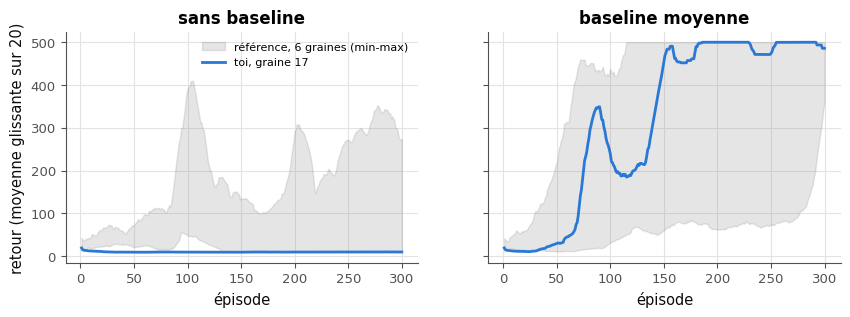

none  : 300 épisodes en 2 s · 50 derniers : 9,5 · politique déterministe sur 100 épisodes : 9,3


mean  : 300 épisodes en 53 s · 50 derniers : 494,3 · politique déterministe sur 100 épisodes : 500,0
✅ Ex B8.17 : avec la baseline, tes 50 derniers épisodes dépassent 100 (la pire des 6 graines de la référence fait 203).


In [42]:
# Training: REINFORCE without and with the mean baseline, N_17 episodes each, against the reference curves of B8.16
if not grads_ok_17:
    print("⏳ Ex B8.17 : l'entraînement attend que tes gradients par épisode passent la vérification ci-dessus.")
else:
    with checked("B8.17"):
        P16_17 = wbr.precomputed("p16")
        runs_17 = {}
        for baseline_17 in ("none", "mean"):
            start_17 = time.perf_counter()
            net_17, returns_17 = pair("B8.17", "train_reinforce_17", train_reinforce_17(SEED_17, N_17, baseline_17),
                                      names=("policy_net", "returns"))
            runs_17[baseline_17] = (net_17, np.asarray(returns_17, dtype=float), time.perf_counter() - start_17)
        fig_17, axes_17 = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
        for ax_17, baseline_17 in zip(axes_17, ("none", "mean")):
            ref_17 = wbr.band([wbr.moving_average(P16_17["runs"][f"{baseline_17}/{s}"]["episode_returns"], 20)
                               for s in P16_17["protocol"]["seeds"]])
            ax_17.fill_between(np.arange(1, 301), ref_17["low"], ref_17["high"], color="gray", alpha=0.2,
                               label="référence, 6 graines (min-max)")
            plot_returns(ax_17, runs_17[baseline_17][1], f"toi, graine {SEED_17}")
            ax_17.set(xlabel="épisode", title={"none": "sans baseline", "mean": "baseline moyenne"}[baseline_17])
        axes_17[0].set_ylabel("retour (moyenne glissante sur 20)")
        axes_17[0].legend(fontsize=8)
        plt.show()
        for baseline_17, (net_17, returns_17, seconds_17) in runs_17.items():
            ev_17 = wbr.evaluate(wbr.greedy_logits(net_17), 100, EVAL_SEED)
            print(f"{baseline_17:5s} : {len(returns_17)} épisodes en {seconds_17:.0f} s · 50 derniers : "
                  f"{fr(returns_17[-50:].mean(), 1)} · politique déterministe sur 100 épisodes : {fr(ev_17['mean_return'], 1)}")
        mean_17 = runs_17["mean"][1]
        verdict("B8.17", len(mean_17) == N_17 and mean_17[-50:].mean() >= THRESHOLD_17,
                f"avec la baseline, tes 50 derniers épisodes dépassent {THRESHOLD_17:g} (la pire des 6 graines de la "
                f"référence fait 203).",
                f"avec la baseline, attendu {N_17} épisodes dont les 50 derniers dépassent {THRESHOLD_17:g} en moyenne, "
                f"reçu {len(mean_17)} épisodes et {fr(float(mean_17[-50:].mean()), 1) if len(mean_17) else '?'} ; si ta "
                "courbe monte puis retombe vers 9 (une politique devenue déterministe, qui pousse toujours du même côté), "
                "relance avec une autre SEED_17 avant de chercher une erreur : REINFORCE s'effondre parfois.")

### Ex B8.18 — compute_gae et explained_variance 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire GAE à rebours, avec la distinction entre fin d'épisode et limite de temps, et la variance expliquée d'un critique, en NumPy.  
**Prérequis :** ✏️ B8.4 · fiche §208.4 (« GAE », « Fin d'épisode ou limite de temps », « Le critique et sa variance expliquée ») · **mylearn :** `deep_rl.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/deep_rl.py` (créé par `python tools/start_chapter.py B8`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement, sans PyTorch. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb8_deep_rl.py -q` les lance tous dans un terminal.

**Contrat** de `compute_gae(rewards, values, next_values, terminated, truncated, gamma=0.99, lam=0.95)`, qui rend le couple `(advantages, returns)` :
- les cinq tableaux ont la même forme, `(T,)` ou `(T, n_envs)`, le **temps sur le premier axe** ; chaque colonne est un rollout à part, avec sa propre récursion ;
- $\delta_t = r_t + \gamma(1 - \text{terminated}_t)\,\text{next\_values}_t - \text{values}_t$, puis à rebours $\hat A_t = \delta_t + \gamma\lambda(1 - \text{done}_t)\,\hat A_{t+1}$, avec $\text{done}_t$ = `terminated` **ou** `truncated` et $\hat A_T = 0$ après le dernier pas ;
- `next_values[t]` est **toujours** la valeur de l'observation qui suit le pas $t$, au dernier pas du rollout compris : il n'y a pas de valeur d'amorçage à part, et on ne la reprend pas dans `values[t+1]` ; un pas tronqué amorce sur sa `next_values` (la vraie dernière observation) mais arrête la récursion ; `terminated` et `truncated` peuvent être vrais ensemble ;
- `returns` vaut `advantages + values` (pas `next_values`), de la forme de `rewards` ;
- $\gamma$ et $\lambda$ dans $[0, 1]$, bornes comprises ; sinon `ValueError`.

**Contrat** de `explained_variance(y_pred, y_true)`, qui rend un `float` : $1 - \operatorname{Var}(y_{\text{true}} - y_{\text{pred}})/\operatorname{Var}(y_{\text{true}})$, **la prédiction d'abord** (l'ordre inverse de `sklearn.metrics.explained_variance_score`), des variances de population (`np.var`) ; `nan` **seulement** quand la variance de `y_true` vaut exactement 0 ; une prédiction constante donne 0, pas `nan`. Attention : `np.var([0.1, 0.1, 0.1])` vaut $1{,}9 \times 10^{-34}$ et non 0 ; les tests n'emploient que des constantes exactes en binaire (3, 0, −2,5), et acceptent aussi une constante détectée autrement (`np.ptp(y_true) == 0`).

**Pour les deux** : les entrées ne sont jamais modifiées ; des formes différentes lèvent `ValueError`, même quand NumPy pourrait les diffuser (`(T, 1)` contre `(T,)`, un tableau de longueur 1), y compris pour `terminated` et `truncated` ; des listes et des tableaux float32 sont acceptés ; les tests comparent à $10^{-6}$ près.

La première cellule de vérification essaie tes fonctions sur les deux exemples de la docstring, le tableau de 208.4, un rollout `(9, 3)` comparé colonne par colonne et les trois exemples de variance expliquée de 208.4, puis affiche ce que rend ta `compute_gae` sur le rollout de ✏️ B8.4 (compare à tes réponses). La seconde lance les 79 tests de l'exercice (`-k "test_compute_gae_ or test_explained_variance_"`).

Dans tes notes : que donnent λ = 0 et λ = 1 (lis-le sur ta fonction) ? Pourquoi `next_values` plutôt que `values` décalé d'un pas ? Que se passerait-il au dernier pas d'un rollout si l'on prenait 0 pour la valeur suivante ?

In [43]:
with checked("B8.18"):
    r_18, v_18 = [1.0, 1.0, 1.0], [0.0, 0.0, 0.0]
    out_18 = mylearn.deep_rl.compute_gae(r_18, v_18, v_18, [False, False, True], [False, False, False], gamma=0.5,
                                         lam=1.0)
    adv_18, ret_18 = pair("B8.18", "compute_gae", out_18, names=("advantages", "returns"))
    same("B8.18", "exemple 1 de la docstring (avantages)", adv_18, [1.75, 1.5, 1.0])
    adv_18, _ = pair("B8.18", "compute_gae", mylearn.deep_rl.compute_gae(
        r_18, [0.5, 0.5, 0.5], [0.5, 0.5, 2.0], [False, False, False], [False, True, False], gamma=0.9, lam=0.5),
        names=("advantages", "returns"))
    same("B8.18", "exemple 2 de la docstring (troncature au pas 1)", adv_18, [1.3775, 0.95, 2.3])
    v_fiche_18 = [2.0, 1.5, 0.8]
    adv_18, ret_18 = pair("B8.18", "compute_gae", mylearn.deep_rl.compute_gae(
        r_18, v_fiche_18, [1.5, 0.8, 0.0], [False, False, True], [False, False, False], gamma=0.9, lam=0.5),
        names=("advantages", "returns"))
    same("B8.18", "le tableau de 208.4 (avantages)", adv_18, [0.4895, 0.31, 0.2])
    same("B8.18", "le tableau de 208.4 (cibles du critique)", ret_18, [2.4895, 1.81, 1.0])
    rng_18 = np.random.default_rng(18)
    cols_18 = [rng_18.normal(size=(9, 3)) for _ in range(3)] + [rng_18.random((9, 3)) < 0.2, rng_18.random((9, 3)) < 0.2]
    passed_18 = [c.copy() for c in cols_18]
    adv2_18, _ = pair("B8.18", "compute_gae", mylearn.deep_rl.compute_gae(*passed_18, 0.95, 0.9),
                      names=("advantages", "returns"))
    verdict("B8.18", all(np.array_equal(a, b) for a, b in zip(passed_18, cols_18)), "compute_gae laisse ses entrées intactes.",
            "compute_gae a modifié un de ses tableaux d'entrée : travaille sur des copies.")
    one_18 = np.stack([wbr.gae_numpy(*[c[:, j] for c in cols_18], 0.95, 0.9)[0] for j in range(3)], axis=1)
    same("B8.18", "un rollout (9, 3) : chaque colonne comme un rollout à elle seule", adv2_18, one_18, rtol=1e-6, atol=1e-6)
    ev_18 = mylearn.deep_rl.explained_variance([1.5, 1.5, 3.5, 3.5], [1.0, 2.0, 3.0, 4.0])
    same("B8.18", "variance expliquée de 208.4 (prédictions d'abord)", ev_18, 0.8)
    same("B8.18", "une prédiction décalée de 5 partout", mylearn.deep_rl.explained_variance([6.0, 7.0, 8.0, 9.0],
                                                                                         [1.0, 2.0, 3.0, 4.0]), 1.0)
    same("B8.18", "des retours tous égaux", mylearn.deep_rl.explained_variance([1.0, 2.0], [3.0, 3.0]), np.nan)
    b84_18 = mylearn.deep_rl.compute_gae([1.0] * 4, [4.0, 3.8, 2.0, 2.4], [3.8, 3.6, 2.4, 2.6], [False] * 4,
                                         [False, True, False, False], gamma=0.9, lam=0.95)[0]
    print("le rollout de ✏️ B8.4 (λ = 0,95) avec ta fonction :", np.round(np.asarray(b84_18, dtype=float), 4).tolist(),
          "← compare à tes réponses de B8.4 d) et e)")

✅ Ex B8.18 : exemple 1 de la docstring (avantages) : [1.75, 1.5, 1.0], comme attendu.
✅ Ex B8.18 : exemple 2 de la docstring (troncature au pas 1) : [1.3775, 0.95, 2.3], comme attendu.
✅ Ex B8.18 : le tableau de 208.4 (avantages) : [0.4895, 0.31, 0.2], comme attendu.
✅ Ex B8.18 : le tableau de 208.4 (cibles du critique) : [2.4895, 1.81, 1.0], comme attendu.
✅ Ex B8.18 : compute_gae laisse ses entrées intactes.
✅ Ex B8.18 : un rollout (9, 3) : chaque colonne comme un rollout à elle seule : un tableau (9, 3), comme attendu.
✅ Ex B8.18 : variance expliquée de 208.4 (prédictions d'abord) : 0.8, comme attendu.
✅ Ex B8.18 : une prédiction décalée de 5 partout : 1.0, comme attendu.
✅ Ex B8.18 : des retours tous égaux : nan, comme attendu.
le rollout de ✏️ B8.4 (λ = 0,95) avec ta fonction : [0.7962, 0.44, 1.9637, 0.94] ← compare à tes réponses de B8.4 d) et e)


In [44]:
if written(lambda: mylearn.deep_rl.compute_gae([1.0], [0.0], [0.0], [True], [False])):
    run_pytest_group(TEST_DEEP_RL, impl="ref", keyword="test_compute_gae_ or test_explained_variance_")   # 79 tests
else:
    print("⏳ Ex B8.18 : les tests attendent tes fonctions compute_gae et explained_variance.")

pytest: 79 passed, 84 deselected in 2.14s


### Ex B8.19 — clipped_surrogate : valeur et gradient par rapport au ratio 🔨 ★★ ⏱️ 20 min
**Objectif :** écrire l'objectif clippé de PPO et son gradient par rapport aux ratios, cas par cas, sans autograd.  
**Prérequis :** ✏️ B8.5 · fiche §208.5 (« L'objectif clippé ») · **mylearn :** `deep_rl.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/deep_rl.py` (créé par `python tools/start_chapter.py B8`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement, sans PyTorch. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb8_deep_rl.py -q` les lance tous dans un terminal.

**Contrat** de `clipped_surrogate(ratio, advantages, clip_eps=0.2)`, qui rend le couple `(loss, gradient)` :
- `loss` $= -\frac{1}{n}\sum_i \min\big(\rho_i \hat A_i,\ \operatorname{clip}(\rho_i, 1 - \varepsilon, 1 + \varepsilon)\,\hat A_i\big)$, un `float` (la convention de la fiche : on minimise l'opposé de $L^{\text{CLIP}}$) ;
- `gradient` est la dérivée de `loss` par rapport à chaque ratio, un tableau `(n,)` : $-\hat A_i/n$ quand le terme non clippé est le minimum, **égalités comprises** (un ratio dans l'intervalle, ou **sur un bord exact**, comme l'autograd de `torch.clamp`), et 0 quand le terme clippé est **strictement** plus petit ; un avantage nul donne un gradient nul. Une façon de vérifier : pour $\hat A > 0$, le gradient est non nul tant que $\rho \le 1 + \varepsilon$ ; pour $\hat A < 0$, tant que $\rho \ge 1 - \varepsilon$ ;
- `ratio` et `advantages` de forme `(n,)`, sans diffusion (des formes différentes lèvent `ValueError`) ; un ratio de 0 est accepté, un ratio négatif lève `ValueError` ; `clip_eps` doit être > 0 (sinon `ValueError`) et **peut dépasser 1** ;
- les entrées ne sont jamais modifiées ; listes et tableaux float32 acceptés ; tolérance $10^{-6}$.

La première cellule de vérification essaie ta fonction sur l'exemple de 208.5, puis la compare à l'autograd de PyTorch (`-torch.min(r * A, r.clamp(1 - eps, 1 + eps) * A).mean()`) sur 9 ratios, dont deux sur un bord exact, pour ε = 0,2, 0,5 et 1,5. La seconde lance les 38 tests de l'exercice (`-k "test_clipped_surrogate_"`).

Dans tes notes : dans quelles zones de la figure 1 de l'article le gradient s'annule-t-il ? Pourquoi un ratio monté au-dessus de $1 + \varepsilon$ avec un avantage **négatif** garde-t-il son gradient ? Que devient l'objectif avec $\varepsilon \ge 1$ du côté bas ?

In [45]:
with checked("B8.19"):
    loss_19, grad_19 = pair("B8.19", "clipped_surrogate", mylearn.deep_rl.clipped_surrogate([0.7, 1.1, 1.35],
                                                                                           [-1.0, 2.0, -1.0], 0.2),
                            names=("loss", "gradient"), floats=("loss",))
    same("B8.19", "l'exemple de 208.5 (loss)", loss_19, -(-0.8 + 2.2 - 1.35) / 3)
    same("B8.19", "l'exemple de 208.5 (gradient)", grad_19, [0.0, -2 / 3, 1 / 3])
    rng_19 = np.random.default_rng(19)
    for eps_19 in (0.2, 0.5, 1.5):
        ratio_19 = np.concatenate([rng_19.uniform(0.0, 2.5, 6), [1 - eps_19 if eps_19 < 1 else 0.0, 1 + eps_19, 1.0]])
        adv_19 = np.concatenate([rng_19.normal(size=6), [1.5, -1.5, 0.0]])
        r_t = torch.tensor(ratio_19, requires_grad=True)
        a_t = torch.tensor(adv_19)
        want_19 = -torch.min(r_t * a_t, r_t.clamp(1 - eps_19, 1 + eps_19) * a_t).mean()
        want_19.backward()
        loss_19, grad_19 = pair("B8.19", "clipped_surrogate",
                                mylearn.deep_rl.clipped_surrogate(ratio_19.copy(), adv_19.copy(), eps_19),
                                names=("loss", "gradient"), floats=("loss",))
        same("B8.19", f"9 ratios (deux sur un bord exact), ε = {fr(eps_19, 1)} : la loss contre l'autograd", loss_19,
             want_19.item(), rtol=1e-9, atol=1e-12)
        same("B8.19", f"9 ratios, ε = {fr(eps_19, 1)} : le gradient contre l'autograd", grad_19, r_t.grad.numpy(),
             rtol=1e-9, atol=1e-12)

✅ Ex B8.19 : l'exemple de 208.5 (loss) : -0.01666667, comme attendu.
✅ Ex B8.19 : l'exemple de 208.5 (gradient) : [0.0, -0.66666667, 0.33333333], comme attendu.
✅ Ex B8.19 : 9 ratios (deux sur un bord exact), ε = 0,2 : la loss contre l'autograd : 0.08424787, comme attendu.
✅ Ex B8.19 : 9 ratios, ε = 0,2 : le gradient contre l'autograd : un tableau (9,), comme attendu.
✅ Ex B8.19 : 9 ratios (deux sur un bord exact), ε = 0,5 : la loss contre l'autograd : 0.11426403, comme attendu.
✅ Ex B8.19 : 9 ratios, ε = 0,5 : le gradient contre l'autograd : un tableau (9,), comme attendu.
✅ Ex B8.19 : 9 ratios (deux sur un bord exact), ε = 1,5 : la loss contre l'autograd : 0.8587274, comme attendu.
✅ Ex B8.19 : 9 ratios, ε = 1,5 : le gradient contre l'autograd : un tableau (9,), comme attendu.


In [46]:
if written(lambda: mylearn.deep_rl.clipped_surrogate([1.0], [1.0])):
    run_pytest_group(TEST_DEEP_RL, impl="ref", keyword="test_clipped_surrogate_")   # 38 tests
else:
    print("⏳ Ex B8.19 : les tests attendent ta fonction clipped_surrogate.")

pytest: 38 passed, 125 deselected in 2.12s


### Ex B8.20 — PPO from scratch sur CartPole : environnements vectorisés, acteur-critique, GAE, clip, entropie 📦 ★★★★ ⏱️ 150 min
**Objectif :** assembler un PPO complet sur des environnements vectorisés, avec ta GAE et ton objectif clippé, et le voir résoudre CartPole.  
**Prérequis :** Ex B8.17, 🔨 B8.18, B8.19 · ✏️ B8.4, B8.5 · fiche §208.4, §208.5 (« La loss complète et la boucle », « Les environnements vectorisés ») · 🔁 R2 · **Fil rouge :** CartPole · **Parcours :** C

**Contrat** des quatre morceaux de la cellule suivante (les réglages sont dans `SETTINGS_20`, ceux du PPO de référence du chapitre, affichés par la cellule donnée) :
- `ActorCritic20(hidden=64)`, un `nn.Module` : un **acteur** (4 → `hidden` → `hidden` → 2 logits, tanh) et un **critique** (4 → `hidden` → `hidden` → 1, tanh), deux réseaux séparés dans les attributs `actor` et `critic` ; `forward(obs)` rend les logits `(N, 2)`, `value(obs)` rend $V$ de forme `(N,)` ;
- `rollout_20(agent, envs, obs, just_reset, n_steps, generator)` joue `n_steps` pas dans chacune des $N$ copies de `envs` (un `gym.make_vec` en autoreset next-step) et rend le triplet `(batch, obs, just_reset)` :
  - les actions sont **tirées** dans la politique de l'agent, sans gradient (avec `generator`, un `torch.Generator`) ;
  - `obs` `(N, 4)` est l'observation courante ; `just_reset` `(N,)` vaut `True` pour une copie dont le pas précédent a fini l'épisode : son prochain pas ne fait que le reset ;
  - `batch` est un dictionnaire de tableaux NumPy de forme `(n_steps, N, ...)` : `"obs"` (avant le pas), `"actions"`, `"log_probs"` (de l'action jouée), `"values"` ($V$ de `obs`), `"rewards"`, `"terminated"`, `"truncated"`, `"next_obs"` (ce que rend le pas), `"next_values"` ($V$ de `next_obs` : au pas où un épisode finit, celle de la **vraie dernière observation**) et `"valid"` (`False` au pas qui ne fait que le reset d'une copie : ce n'est pas une transition) ;
  - les `obs` et `just_reset` rendus servent au rollout suivant ;
- `ppo_loss_20(agent, obs, actions, old_log_probs, advantages, returns, settings=SETTINGS_20)` rend le couple `(loss, parts)` pour un mini-batch de tenseurs : `loss` $= L^{\pi} + c_1 L^V - c_2 H$ (un tenseur, avec son graphe), $L^{\pi} = -\operatorname{mean}\min(\rho \hat A, \operatorname{clip}(\rho, 1 \pm \varepsilon)\hat A)$, $\rho = \exp(\log\pi(a \mid s) - \text{old\_log\_probs})$, $L^V = \frac12 \operatorname{mean}(V(s) - \text{returns})^2$, $H$ l'entropie moyenne de $\pi(\cdot \mid s)$, $c_1$ = `vf_coef`, $c_2$ = `ent_coef`, $\varepsilon$ = `clip_eps` ; les avantages servent tels quels (on les normalise avant) ; `parts` est un dictionnaire de `float` : `"policy_loss"`, `"value_loss"`, `"entropy"`, `"approx_kl"` (la moyenne de $(\rho - 1) - \ln\rho$), `"clipfrac"` (la part des $|\rho - 1| > \varepsilon$) ;
- `train_ppo_20(seed, total_steps, settings=SETTINGS_20, reward_fn=None)` entraîne PPO et rend le couple `(agent, logs)` :
  - **départ** : `torch.manual_seed(seed)`, l'agent, Adam (`lr`, `eps=adam_eps`), un `torch.Generator().manual_seed(seed)` pour les actions et les mélanges, `n_envs` copies de CartPole-v1 (`gym.make_vec(..., vectorization_mode="sync")`, autoreset next-step) remises à zéro une fois avec `seed` ;
  - **les itérations** : `total_steps // (n_envs × n_steps)` ; à chacune, le learning rate `lr × (1 − it/n_iter)` quand `anneal_lr`, un rollout, puis les avantages et les retours par `mylearn.deep_rl.compute_gae` (ta fonction de B8.18, **appelée par ce nom** : la vérification l'observe) avec `gamma` et `gae_lambda`, et la variance expliquée par `mylearn.deep_rl.explained_variance`, sur les transitions valides ;
  - **la mise à jour** : `n_epochs` passages sur les transitions **valides**, mélangées puis coupées en `n_minibatches` mini-batches ; dans chacun, les avantages normalisés (`norm_adv`), `ppo_loss_20`, `clip_grad_norm_(..., max_grad_norm)` et un pas d'Adam ; et `mylearn.deep_rl.clipped_surrogate` (B8.19) sur les mêmes ratios (détachés) et les mêmes avantages, dont l'écart à `parts["policy_loss"]` entre dans le journal ;
  - **`reward_fn(obs, actions, next_obs)`**, quand elle est donnée, remplace les récompenses du rollout par les siennes (tableau `(N,)` pour un pas) avant GAE : le RLHF de la partie C s'en servira ; `"mean_return"` reste calculé avec les **vraies** récompenses ;
  - **`logs`** : un dictionnaire de listes, une valeur par itération, aux clés de `wbr.LOG_KEYS` (`"step"`, pas d'environnement joués jusque-là, toutes copies comprises ; `"iteration"` ; `"lr"` ; `"policy_loss"`, `"value_loss"`, `"entropy"`, `"approx_kl"`, `"clipfrac"`, moyennes sur les mini-batches de l'itération ; `"explained_variance"` ; `"episodes"`, le nombre d'épisodes finis pendant le rollout ; `"mean_return"`, leur retour moyen, `nan` s'il n'y en a pas) et `"surrogate_gap"` (le plus grand écart de l'itération entre ta `clipped_surrogate` et la loss torch).

La vérification essaie `ActorCritic20` ; puis `rollout_20` avec un agent fixe de la référence, deux rollouts de 10 pas sur deux copies coupées à 12 pas : elle rejoue l'environnement avec **tes** actions et compare chaque champ du batch ; puis `ppo_loss_20` sur un mini-batch de 16 contre la référence ; enfin une boucle de deux itérations, qui observe tes appels à `compute_gae` et à `clipped_surrogate`. La cellule suivante entraîne ton PPO sur `STEPS_20` pas (50 000 en mode rapide, environ 25 s), trace le retour de chaque rollout et évalue la politique **déterministe** (l'action la plus probable) sur 100 épisodes ; elle attend que le retour monte et que l'évaluation dépasse `THRESHOLD_20`, puis enregistre ton agent (`AGENT_KEY_20`, à ton nom) pour la suite du chapitre.

Dans tes notes : combien de pas de reset ton rollout a-t-il écartés sur 50 000 pas, et que se serait-il passé en les gardant (🕰️ Gymnasium 1.x) ? Où ta boucle amorce-t-elle une limite de temps, et que fait `ppo.py` de CleanRL à la place (208.4) ? Pourquoi normaliser les avantages par mini-batch ? Combien de pas d'Adam ton PPO a-t-il faits, et combien de transitions chacun a-t-il servi ?

In [47]:
SETTINGS_20 = dict(wbr.PPO_SETTINGS)      # the settings of the reference PPO (printed below)
STEPS_20 = wbr.ppo_steps(FAST_MODE)         # 50 000 environment steps (all copies) in fast mode, 100 000 in full mode
SEED_20 = 20
THRESHOLD_20 = 170               # the deterministic evaluation that the check asks (6 seeds of the reference)
AGENT_KEY_20 = wbr.agent_key(SETTINGS_20, source=SOURCE, fast=FAST_MODE, seed=SEED_20, total_steps=STEPS_20)


def load_agent_20(verbose=True):
    """(agent, source) for the rest of the chapter: the agent trained by Ex B8.20 in this session (AGENT_20), else the
    one an earlier session saved under AGENT_KEY_20, else the reference PPO agent of wbr (an explicit fallback, said).
    The solutions notebook never reads the learner's agent: its key has the source "solution"."""
    if globals().get("AGENT_20") is not None:
        return AGENT_20, SOURCE
    try:
        loaded = wbr.load_agent(AGENT_KEY_20, build=ActorCritic20)
    except NotImplementedError:
        loaded = None
    if loaded is not None:
        if verbose:
            print(f"ℹ️ agent de B8.20 relu ({loaded[1]['path'].name}, enregistré le {loaded[1]['saved_at']})")
        return loaded[0], SOURCE
    agent, _ = wbr.reference_agent(FAST_MODE, verbose=verbose)
    if verbose:
        print("ℹ️ pas d'agent de B8.20 enregistré : repli sur l'agent PPO de référence (wbr.reference_agent)")
    return agent, "reference"


print(SETTINGS_20)

{'n_envs': 4, 'n_steps': 128, 'n_minibatches': 4, 'n_epochs': 10, 'lr': 0.001, 'anneal_lr': True, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_eps': 0.2, 'ent_coef': 0.01, 'vf_coef': 0.5, 'max_grad_norm': 0.5, 'norm_adv': True, 'hidden': 64, 'adam_eps': 1e-05}


In [48]:
def _layer_20(n_in, n_out, gain):
    layer = nn.Linear(n_in, n_out)
    nn.init.orthogonal_(layer.weight, gain)       # the orthogonal initialisation of CleanRL (208.5, "37 détails")
    nn.init.zeros_(layer.bias)
    return layer


class ActorCritic20(nn.Module):
    """The agent: an actor (4 -> hidden -> hidden -> 2 logits, tanh) and a critic (4 -> hidden -> hidden -> 1, tanh),
    two separate networks in the attributes `actor` and `critic`. forward(obs) returns the logits (N, 2);
    value(obs) returns V(obs), of shape (N,)."""

    def __init__(self, hidden=64):
        super().__init__()
        g = math.sqrt(2)
        self.actor = nn.Sequential(_layer_20(4, hidden, g), nn.Tanh(), _layer_20(hidden, hidden, g), nn.Tanh(),
                                   _layer_20(hidden, 2, 0.01))
        self.critic = nn.Sequential(_layer_20(4, hidden, g), nn.Tanh(), _layer_20(hidden, hidden, g), nn.Tanh(),
                                    _layer_20(hidden, 1, 1.0))

    def forward(self, obs):
        return self.actor(obs)

    def value(self, obs):
        return self.critic(obs).squeeze(-1)


def rollout_20(agent, envs, obs, just_reset, n_steps, generator):
    """One rollout of n_steps steps in each copy of envs (the contract of the statement). Returns (batch, obs,
    just_reset): batch a dict of NumPy arrays of shape (n_steps, N, ...) "obs", "actions", "log_probs", "values",
    "rewards", "terminated", "truncated", "next_obs", "next_values", "valid"; obs and just_reset for the next rollout."""
    keys = ("obs", "actions", "log_probs", "values", "rewards", "terminated", "truncated", "next_obs", "valid")
    rows = {k: [] for k in keys}
    for _ in range(n_steps):
        with torch.no_grad():
            x = torch.as_tensor(obs, dtype=torch.float32)
            log_pi = torch.log_softmax(agent(x), dim=1)
            actions = torch.multinomial(log_pi.exp(), 1, generator=generator).squeeze(1)
            values = agent.value(x)
        next_obs, rewards, terminated, truncated, _ = envs.step(actions.numpy())
        step = (obs, actions.numpy(), log_pi.gather(1, actions[:, None]).squeeze(1).numpy(), values.numpy(), rewards,
                terminated, truncated, next_obs, ~just_reset)          # valid: False when the step only resets a copy
        for k, v in zip(keys, step):
            rows[k].append(np.array(v, copy=True))
        just_reset = terminated | truncated
        obs = next_obs
    batch = {k: np.stack(v) for k, v in rows.items()}
    with torch.no_grad():                         # V of the observation that FOLLOWS each step: at a time limit, the
        flat = torch.as_tensor(batch["next_obs"].reshape(-1, 4), dtype=torch.float32)   # real last observation
        batch["next_values"] = agent.value(flat).numpy().reshape(n_steps, -1)
    return batch, obs, just_reset


def ppo_loss_20(agent, obs, actions, old_log_probs, advantages, returns, settings=SETTINGS_20):
    """The PPO loss of a mini-batch of tensors (the contract of the statement): (loss, parts), loss a tensor with its
    graph, parts a dict of floats "policy_loss", "value_loss", "entropy", "approx_kl", "clipfrac"."""
    eps = settings["clip_eps"]
    log_pi = torch.log_softmax(agent(obs), dim=1)
    log_ratio = log_pi.gather(1, actions.long()[:, None]).squeeze(1) - old_log_probs
    ratio = log_ratio.exp()
    policy_loss = -torch.min(ratio * advantages, ratio.clamp(1 - eps, 1 + eps) * advantages).mean()
    value_loss = 0.5 * ((agent.value(obs) - returns) ** 2).mean()
    entropy = -(log_pi.exp() * log_pi).sum(dim=1).mean()
    loss = policy_loss + settings["vf_coef"] * value_loss - settings["ent_coef"] * entropy
    with torch.no_grad():
        parts = {"policy_loss": float(policy_loss), "value_loss": float(value_loss), "entropy": float(entropy),
                 "approx_kl": float(((ratio - 1) - log_ratio).mean()),
                 "clipfrac": float(((ratio - 1).abs() > eps).float().mean())}
    return loss, parts


def train_ppo_20(seed, total_steps, settings=SETTINGS_20, reward_fn=None):
    """PPO on settings["n_envs"] copies of CartPole-v1 (the contract of the statement). Returns (agent, logs), logs a
    dict of lists (one value per iteration) with the keys of wbr.LOG_KEYS and "surrogate_gap"."""
    s = settings
    torch.manual_seed(seed)
    agent = ActorCritic20(s["hidden"])
    optimizer = torch.optim.Adam(agent.parameters(), lr=s["lr"], eps=s["adam_eps"])
    generator = torch.Generator().manual_seed(seed)
    envs = gym.make_vec("CartPole-v1", num_envs=s["n_envs"], vectorization_mode="sync",
                        vector_kwargs={"autoreset_mode": gym.vector.AutoresetMode.NEXT_STEP})
    obs, _ = envs.reset(seed=seed)
    just_reset = np.zeros(s["n_envs"], dtype=bool)
    running = np.zeros(s["n_envs"])                      # the true return of the running episode of each copy
    n_iter = total_steps // (s["n_envs"] * s["n_steps"])
    logs = {k: [] for k in (*wbr.LOG_KEYS, "surrogate_gap")}
    for it in range(n_iter):
        lr = s["lr"] * (1 - it / n_iter) if s["anneal_lr"] else s["lr"]
        for group in optimizer.param_groups:
            group["lr"] = lr
        batch, obs, just_reset = rollout_20(agent, envs, obs, just_reset, s["n_steps"], generator)
        valid = batch["valid"]
        finished = []
        for t in range(s["n_steps"]):                    # the episodes that end in this rollout, with their true returns
            running += np.where(valid[t], batch["rewards"][t], 0.0)
            for i in np.flatnonzero(valid[t] & (batch["terminated"][t] | batch["truncated"][t])):
                finished.append(running[i])
                running[i] = 0.0
        if reward_fn is not None:                        # RLHF: the agent learns from another reward
            batch["rewards"] = np.stack([reward_fn(batch["obs"][t], batch["actions"][t], batch["next_obs"][t])
                                         for t in range(s["n_steps"])]).astype(float)
        adv, ret = mylearn.deep_rl.compute_gae(batch["rewards"], batch["values"], batch["next_values"],
                                               batch["terminated"], batch["truncated"], s["gamma"], s["gae_lambda"])
        ev = mylearn.deep_rl.explained_variance(batch["values"][valid], ret[valid])
        flat = {k: torch.as_tensor(batch[k][valid]) for k in ("obs", "actions", "log_probs")}
        adv_all = torch.as_tensor(adv[valid], dtype=torch.float32)
        ret_all = torch.as_tensor(ret[valid], dtype=torch.float32)
        n = len(adv_all)
        size = n // s["n_minibatches"]
        parts_all, gap = [], 0.0
        for _ in range(s["n_epochs"]):
            order = torch.randperm(n, generator=generator)
            for k in range(s["n_minibatches"]):
                idx = order[k * size:(k + 1) * size]
                a = adv_all[idx]
                if s["norm_adv"]:
                    a = (a - a.mean()) / (a.std() + 1e-8)
                loss, parts = ppo_loss_20(agent, flat["obs"][idx], flat["actions"][idx], flat["log_probs"][idx], a,
                                          ret_all[idx], s)
                with torch.no_grad():                    # your clipped_surrogate (NumPy) against the torch loss
                    ratio = (torch.log_softmax(agent(flat["obs"][idx]), dim=1)
                             .gather(1, flat["actions"][idx][:, None]).squeeze(1) - flat["log_probs"][idx]).exp()
                mine, _ = mylearn.deep_rl.clipped_surrogate(ratio.double().numpy(), a.double().numpy(), s["clip_eps"])
                gap = max(gap, abs(float(mine) - parts["policy_loss"]))
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(), s["max_grad_norm"])
                optimizer.step()
                parts_all.append(parts)
        row = {"step": (it + 1) * s["n_envs"] * s["n_steps"], "iteration": it + 1, "lr": lr,
               **{k: float(np.mean([p[k] for p in parts_all])) for k in parts_all[0]},
               "explained_variance": float(ev), "episodes": len(finished),
               "mean_return": float(np.mean(finished)) if finished else float("nan"), "surrogate_gap": gap}
        for k in logs:
            logs[k].append(row[k])
    envs.close()
    return agent, logs


ok_20 = False
with checked("B8.20"):
    torch.manual_seed(0)
    agent_20 = ActorCritic20()
    obs_20 = torch.as_tensor(np.random.default_rng(20).normal(0, 0.1, (5, 4)), dtype=torch.float32)
    logits_20, value_20 = agent_20(obs_20), agent_20.value(obs_20)
    has_parts_20 = isinstance(getattr(agent_20, "actor", None), nn.Module) and isinstance(getattr(agent_20, "critic", None),
                                                                                         nn.Module)
    verdict("B8.20", tuple(logits_20.shape) == (5, 2) and tuple(value_20.shape) == (5,) and has_parts_20,
            f"ActorCritic20 : acteur et critique séparés, {sum(p.numel() for p in agent_20.parameters())} paramètres ; "
            "forward rend (5, 2), value rend (5,).",
            f"ActorCritic20 : attendu des attributs actor et critic, forward de forme (5, 2) et value de forme (5,), reçu "
            f"{tuple(logits_20.shape)} et {tuple(value_20.shape)}" + ("" if has_parts_20 else ", sans actor ou critic") + ".")

rollout_ok_20 = False
with checked("B8.20"):
    torch.manual_seed(20)
    ref_agent_20 = wbr.ActorCritic(64)                    # a fixed agent of the reference, so that only rollout_20 is tested
    envs_20 = wbr.make_vec(2, seed=5, max_episode_steps=12)
    gen_20 = torch.Generator().manual_seed(20)
    out_a_20 = rollout_20(ref_agent_20, envs_20, envs_20.first_obs.copy(), np.zeros(2, bool), 10, gen_20)
    batch_a_20, obs_a_20, reset_a_20 = pair("B8.20", "rollout_20", out_a_20, names=("batch", "obs", "just_reset"))
    out_b_20 = rollout_20(ref_agent_20, envs_20, obs_a_20, reset_a_20, 10, gen_20)
    batch_b_20, _, _ = pair("B8.20", "rollout_20", out_b_20, names=("batch", "obs", "just_reset"))
    keys_20 = ("obs", "actions", "log_probs", "values", "rewards", "terminated", "truncated", "next_obs", "next_values",
               "valid")
    missing_20 = [k for k in keys_20 if not isinstance(batch_a_20, dict) or k not in batch_a_20]
    if missing_20:
        print(f"❌ Ex B8.20 : le batch de rollout_20 doit avoir les clés {list(keys_20)} ; il manque {missing_20}.")
        raise StopCheck
    shapes_20 = {k: np.shape(batch_a_20[k]) for k in keys_20}
    want_shapes_20 = {k: ((10, 2, 4) if k in ("obs", "next_obs") else (10, 2)) for k in keys_20}
    if shapes_20 != want_shapes_20:
        print(f"❌ Ex B8.20 : formes du batch : attendu {want_shapes_20}, reçu {shapes_20}.")
        raise StopCheck
    replay_20 = wbr.make_vec(2, seed=5, max_episode_steps=12)          # the same copies, played with YOUR actions
    actions_20 = np.concatenate([batch_a_20["actions"], batch_b_20["actions"]]).astype(np.int64)
    expect_20 = {k: [] for k in ("obs", "rewards", "terminated", "truncated", "next_obs", "valid")}
    o_20, jr_20 = replay_20.first_obs, np.zeros(2, bool)
    for t_20 in range(20):
        n_20, r_20, te_20, tr_20, _ = replay_20.step(actions_20[t_20])
        for k_20, v_20 in zip(expect_20, (o_20, r_20, te_20, tr_20, n_20, ~jr_20)):
            expect_20[k_20].append(np.array(v_20, copy=True))
        jr_20, o_20 = te_20 | tr_20, n_20
    both_20 = {k: np.concatenate([np.asarray(batch_a_20[k]), np.asarray(batch_b_20[k])]) for k in keys_20}
    problems_20 = []
    for k_20, v_20 in expect_20.items():
        if not np.allclose(both_20[k_20].astype(float), np.stack(v_20).astype(float)):
            problems_20.append(k_20)
    with torch.no_grad():
        x_20 = torch.as_tensor(both_20["obs"].reshape(-1, 4), dtype=torch.float32)
        lp_want_20 = torch.log_softmax(ref_agent_20(x_20), 1).gather(
            1, torch.as_tensor(actions_20.reshape(-1, 1))).squeeze(1).numpy().reshape(20, 2)
        v_want_20 = ref_agent_20.value(x_20).numpy().reshape(20, 2)
        nv_want_20 = ref_agent_20.value(torch.as_tensor(both_20["next_obs"].reshape(-1, 4), dtype=torch.float32)
                                        ).numpy().reshape(20, 2)
    for k_20, want_20 in (("log_probs", lp_want_20), ("values", v_want_20), ("next_values", nv_want_20)):
        if not np.allclose(both_20[k_20].astype(float), want_20, atol=1e-5):
            problems_20.append(k_20)
    ends_20 = int((np.stack(expect_20["terminated"]) | np.stack(expect_20["truncated"])).sum())
    if not problems_20:
        rollout_ok_20 = True
        print(f"✅ Ex B8.20 : deux rollouts de 10 pas sur 2 copies coupées à 12 pas ({ends_20} fins d'épisode) : tout "
              "correspond à l'environnement rejoué avec tes actions ; les pas de reset sont écartés (valid), "
              "next_values est V de l'observation qui suit chaque pas, et le second rollout reprend où le premier s'arrête.")
    else:
        hints_20 = {"valid": "valid doit valoir False exactement au pas qui suit une fin d'épisode dans la même copie "
                             "(ce pas ne fait que le reset, 208.5), y compris d'un rollout au suivant (just_reset)",
                    "next_values": "next_values[t] est V de l'observation que rend le pas t (la vraie dernière quand "
                                   "l'épisode finit), pas la valeur du pas suivant du rollout",
                    "obs": "obs[t] est l'observation AVANT le pas t ; le second rollout repart de l'observation rendue "
                           "par le premier",
                    "log_probs": "log_probs est le log de la probabilité de l'action jouée, sous la politique de l'agent",
                    "values": "values est V(obs[t]) du critique de l'agent"}
        for k_20 in problems_20:
            print(f"❌ Ex B8.20 : rollout_20, « {k_20} » ne correspond pas à l'environnement rejoué avec tes actions"
                  + (f" : {hints_20[k_20]}." if k_20 in hints_20 else "."))

loss_ok_20 = False
with checked("B8.20"):
    rng_20 = np.random.default_rng(200)
    mb_20 = {"obs": torch.as_tensor(rng_20.normal(0, 0.5, (16, 4)), dtype=torch.float32),
             "actions": torch.as_tensor(rng_20.integers(0, 2, 16)),
             "advantages": torch.as_tensor(rng_20.normal(size=16), dtype=torch.float32),
             "returns": torch.as_tensor(rng_20.normal(5, 2, 16), dtype=torch.float32)}
    with torch.no_grad():                                # old log-probabilities a little away from the current ones
        mb_20["old_log_probs"] = torch.log_softmax(ref_agent_20(mb_20["obs"]), 1).gather(
            1, mb_20["actions"][:, None]).squeeze(1) + torch.as_tensor(rng_20.normal(0, 0.3, 16), dtype=torch.float32)
    args_20 = (mb_20["obs"], mb_20["actions"], mb_20["old_log_probs"], mb_20["advantages"], mb_20["returns"])
    loss_20, parts_20 = pair("B8.20", "ppo_loss_20", ppo_loss_20(ref_agent_20, *args_20, SETTINGS_20),
                             names=("loss", "parts"))
    want_loss_20, want_parts_20 = wbr.ppo_loss(ref_agent_20, *args_20, SETTINGS_20)
    good_20 = [same("B8.20", "ppo_loss_20 sur un mini-batch de 16 (la loss)", loss_20.detach(), want_loss_20.detach(),
                    rtol=1e-5, atol=1e-6)]
    for k_20, v_20 in want_parts_20.items():
        got_20 = parts_20.get(k_20) if isinstance(parts_20, dict) else None
        good_20.append(got_20 is not None and abs(float(got_20) - v_20) <= 1e-5 * max(1.0, abs(v_20)))
        if not good_20[-1]:
            print(f"❌ Ex B8.20 : ppo_loss_20, parts[{k_20!r}] : attendu {v_20:.6g}, reçu {got_20!r}.")
    if not good_20[0] and all(good_20[1:]):
        print("❌ Ex B8.20 : les cinq parties sont justes, mais la loss ne les combine pas comme le contrat : "
              "policy_loss + vf_coef × value_loss − ent_coef × entropy (signes et coefficients de SETTINGS_20).")
    ref_agent_20.zero_grad()
    loss_20.backward()
    reached_20 = {name: any(p.grad is not None and float(p.grad.abs().sum()) > 0 for p in m.parameters())
                  for name, m in (("acteur", ref_agent_20.actor), ("critique", ref_agent_20.critic))}
    good_20.append(all(reached_20.values()))
    verdict("B8.20", good_20[-1], "le gradient de la loss atteint l'acteur et le critique.",
            f"le gradient de la loss n'atteint pas {', '.join(n for n, ok in reached_20.items() if not ok)} : un .detach() "
            "ou un .item() de trop ?")
    loss_ok_20 = all(good_20)

with checked("B8.20"):
    if not (rollout_ok_20 and loss_ok_20):
        print("⏳ Ex B8.20 : la boucle se vérifie une fois rollout_20 et ppo_loss_20 justes.")
    elif not (written(lambda: mylearn.deep_rl.compute_gae([1.0], [0.0], [0.0], [True], [False]))
              and written(lambda: mylearn.deep_rl.clipped_surrogate([1.0], [1.0]))):
        print("⏳ Ex B8.20 : ta boucle se sert de compute_gae et de clipped_surrogate de ta librairie (B8.18, B8.19), pas "
              "encore écrites.")
    else:
        seen_20 = {"gae": [], "surrogate": 0}
        real_gae_20, real_clip_20 = mylearn.deep_rl.compute_gae, mylearn.deep_rl.clipped_surrogate

        def spy_gae_20(*args, **kwargs):
            out = real_gae_20(*args, **kwargs)
            bound = inspect.signature(real_gae_20).bind(*args, **kwargs).arguments
            seen_20["gae"].append((tuple(np.shape(bound.get(k)) for k in ("rewards", "values", "next_values",
                                                                           "terminated", "truncated")), args, kwargs))
            return out

        def spy_clip_20(*args, **kwargs):
            seen_20["surrogate"] += 1
            return real_clip_20(*args, **kwargs)

        mylearn.deep_rl.compute_gae, mylearn.deep_rl.clipped_surrogate = spy_gae_20, spy_clip_20
        try:
            short_20 = {**SETTINGS_20, "n_epochs": 2}
            per_iter_20 = short_20["n_envs"] * short_20["n_steps"]
            agent_s_20, logs_s_20 = pair("B8.20", "train_ppo_20", train_ppo_20(3, 2 * per_iter_20, short_20),
                                         names=("agent", "logs"))
        finally:
            mylearn.deep_rl.compute_gae, mylearn.deep_rl.clipped_surrogate = real_gae_20, real_clip_20
        want_keys_20 = set(wbr.LOG_KEYS) | {"surrogate_gap"}
        good_20 = []
        good_20.append(isinstance(logs_s_20, dict) and want_keys_20 <= set(logs_s_20)
                       and all(len(logs_s_20[k]) == 2 for k in want_keys_20))
        verdict("B8.20", good_20[-1], "les journaux : une valeur par itération pour chaque clé de wbr.LOG_KEYS et surrogate_gap.",
                f"logs doit avoir les clés {sorted(want_keys_20)}, une valeur par itération (2 ici), reçu "
                + (str({k: len(v) for k, v in logs_s_20.items()}) if isinstance(logs_s_20, dict) else type(logs_s_20).__name__) + ".")
        shape_20 = (short_20["n_steps"], short_20["n_envs"])
        good_20.append(len(seen_20["gae"]) == 2 and all(s == (shape_20,) * 5 for s, _, _ in seen_20["gae"]))
        verdict("B8.20", good_20[-1], f"compute_gae de ta librairie : appelée une fois par itération sur des tableaux {shape_20}.",
                f"attendu un appel de mylearn.deep_rl.compute_gae par itération (2) sur des tableaux {shape_20} (le temps "
                f"d'abord), reçu {len(seen_20['gae'])} appels" + (f" de formes {seen_20['gae'][0][0]}" if seen_20["gae"] else "")
                + " ; l'appelles-tu par ce nom (la vérification l'observe) ?")
        n_mb_20 = 2 * short_20["n_epochs"] * short_20["n_minibatches"]
        good_20.append(seen_20["surrogate"] >= n_mb_20)
        verdict("B8.20", good_20[-1], f"clipped_surrogate de ta librairie : appelée à chaque mini-batch ({seen_20['surrogate']} fois).",
                f"attendu au moins {n_mb_20} appels de mylearn.deep_rl.clipped_surrogate (un par mini-batch), reçu "
                f"{seen_20['surrogate']}.")
        if good_20[0]:
            gap_20 = max(logs_s_20["surrogate_gap"])
            good_20.append(gap_20 <= 1e-5)
            verdict("B8.20", good_20[-1], f"ta clipped_surrogate et la loss torch coïncident (écart {gap_20:.1e}).",
                    f"ta clipped_surrogate et la loss torch du même mini-batch diffèrent de {gap_20:.2g} : leur passes-tu "
                    "les mêmes ratios et les mêmes avantages (normalisés) ?")
        ok_20 = all(good_20)

✅ Ex B8.20 : ActorCritic20 : acteur et critique séparés, 9155 paramètres ; forward rend (5, 2), value rend (5,).
✅ Ex B8.20 : deux rollouts de 10 pas sur 2 copies coupées à 12 pas (2 fins d'épisode) : tout correspond à l'environnement rejoué avec tes actions ; les pas de reset sont écartés (valid), next_values est V de l'observation qui suit chaque pas, et le second rollout reprend où le premier s'arrête.
✅ Ex B8.20 : ppo_loss_20 sur un mini-batch de 16 (la loss) : 7.48768044, comme attendu.
✅ Ex B8.20 : le gradient de la loss atteint l'acteur et le critique.


✅ Ex B8.20 : les journaux : une valeur par itération pour chaque clé de wbr.LOG_KEYS et surrogate_gap.
✅ Ex B8.20 : compute_gae de ta librairie : appelée une fois par itération sur des tableaux (128, 4).
✅ Ex B8.20 : clipped_surrogate de ta librairie : appelée à chaque mini-batch (16 fois).
✅ Ex B8.20 : ta clipped_surrogate et la loss torch coïncident (écart 9.4e-09).


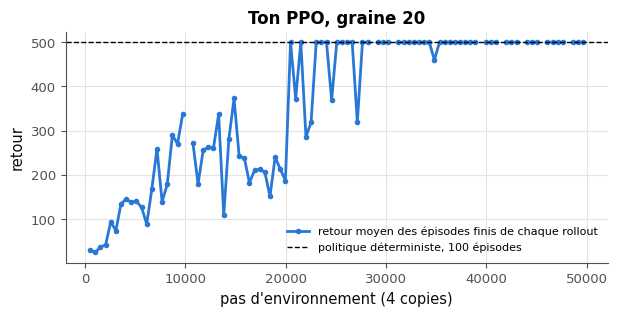

50000 pas en 19 s (97 itérations, 211 épisodes finis) · politique déterministe : 500,0 sur 100 épisodes (écart-type 0,0) · écart maximal entre ta clipped_surrogate et la loss torch : 2.6e-08
✅ Ex B8.20 : le retour monte : 45,0 sur les 5 premières itérations, 500,0 sur les 5 dernières.
✅ Ex B8.20 : la politique déterministe dépasse 170 (la référence, sur 6 graines : 500 ; 500 ; 500 ; 284 ; 500 ; 500).
agent enregistré pour la suite du chapitre (source 'solution') : ppo-solution-fast-e68189405624d775.pt


In [49]:
# Training: your PPO, STEPS_20 steps on 4 copies, then the deterministic policy on 100 episodes; the agent is saved
if not ok_20:
    print("⏳ Ex B8.20 : l'entraînement attend que la vérification ci-dessus passe.")
else:
    with checked("B8.20"):
        start_20 = time.perf_counter()
        AGENT_20, LOGS_20 = train_ppo_20(SEED_20, STEPS_20)
        seconds_20 = time.perf_counter() - start_20
        eval_20 = wbr.evaluate(wbr.greedy_logits(AGENT_20), 100, EVAL_SEED)
        steps_20, returns_20 = np.asarray(LOGS_20["step"]), np.asarray(LOGS_20["mean_return"], dtype=float)
        fig_20, ax_20 = plt.subplots(figsize=(7, 3))
        ax_20.plot(steps_20, returns_20, marker=".", label="retour moyen des épisodes finis de chaque rollout")
        ax_20.axhline(eval_20["mean_return"], color="k", ls="--", lw=1, label="politique déterministe, 100 épisodes")
        ax_20.set(xlabel="pas d'environnement (4 copies)", ylabel="retour", title=f"Ton PPO, graine {SEED_20}")
        ax_20.legend(fontsize=8)
        plt.show()
        print(f"{STEPS_20} pas en {seconds_20:.0f} s ({len(steps_20)} itérations, {int(np.sum(LOGS_20['episodes']))} "
              "épisodes finis) · politique déterministe : "
              f"{fr(eval_20['mean_return'], 1)} sur 100 épisodes (écart-type {fr(eval_20['std_return'], 1)}) · écart "
              f"maximal entre ta clipped_surrogate et la loss torch : {max(LOGS_20['surrogate_gap']):.1e}")
        finite_20 = returns_20[np.isfinite(returns_20)]          # an iteration where no episode ends has nan
        early_20, late_20 = float(finite_20[:5].mean()), float(finite_20[-5:].mean())
        verdict("B8.20", late_20 >= 2 * early_20,
                f"le retour monte : {fr(early_20, 1)} sur les 5 premières itérations, {fr(late_20, 1)} sur les 5 dernières.",
                f"le retour ne monte pas assez : {fr(early_20, 1)} sur les 5 premières itérations, {fr(late_20, 1)} sur "
                "les 5 dernières.")
        verdict("B8.20", eval_20["mean_return"] >= THRESHOLD_20,
                f"la politique déterministe dépasse {THRESHOLD_20:g} (la référence, sur 6 graines : 500 ; 500 ; 500 ; 284 ; 500 ; 500).",
                f"la politique déterministe tient {fr(eval_20['mean_return'], 1)} pas : moins que les {THRESHOLD_20:g} "
                f"attendus (la référence, sur 6 graines : 500 ; 500 ; 500 ; 284 ; 500 ; 500).")
        wbr.delete_agent(AGENT_KEY_20)
        print(f"agent enregistré pour la suite du chapitre (source {SOURCE!r}) : "
              f"{wbr.save_agent(AGENT_KEY_20, AGENT_20, LOGS_20, extra={'eval': eval_20['mean_return']}).name}")

### Ex B8.21 — Lire les journaux de PPO : KL approchée, fraction clippée, entropie, variance expliquée 📈 ★★ ⏱️ 20 min
**Objectif :** reconnaître dans les journaux d'un PPO un learning rate trop grand, un clip absent, un bonus d'entropie de mauvais signe et un critique qui n'apprend pas.  
**Prérequis :** Ex B8.20 · fiche §208.4 (« Le critique et sa variance expliquée »), §208.5 (« Les journaux de PPO ») · **Fil rouge :** CartPole · **Parcours :** C

Cinq runs du PPO de référence du chapitre (`wbr.train_ppo`, 50 000 pas, la même graine), notés A à E dans un ordre tiré au hasard. L'un a les réglages de référence (`SETTINGS_20`) ; chacun des quatre autres en change **un seul** :
- un learning rate dix fois plus grand ($10^{-2}$), qui ne décroît jamais ;
- **pas de clipping** : un `clip_eps` si grand qu'aucun ratio n'est jamais rogné ;
- un bonus d'entropie **de mauvais signe** (`ent_coef = -0.2` : la loss récompense une politique sûre d'elle) ;
- un critique qui n'apprend pas (`vf_coef = 0` : sa loss ne compte plus).

La cellule donnée trace, pour chaque run, les cinq journaux de 208.5 au fil des itérations : le retour des épisodes finis pendant le rollout, la KL approchée (en échelle logarithmique), la fraction clippée, l'entropie et la variance expliquée ; une colonne a la même échelle pour les cinq runs. Ce sont les journaux que rend aussi ton `train_ppo_20` (B8.20). **Lis la figure** et réponds par une lettre entre guillemets :
- a) `healthy_21` : le run aux réglages de référence ;
- b) `lr_high_21` : le learning rate trop grand ;
- c) `no_clip_21` : sans clipping ;
- d) `entropy_sign_21` : le bonus d'entropie de mauvais signe ;
- e) `no_critic_21` : le critique qui n'apprend pas.

Chaque lettre sert une fois. Attention aux effets de **fin** d'un run réussi : le learning rate décroît jusqu'à 0, et quand presque tous les épisodes durent 500 pas, les retours à prédire se ressemblent tous. La cellule suivante trace les mêmes journaux pour **ton** PPO de B8.20.

Dans tes notes : pour chaque run malade, la courbe qui t'a convaincu et ce qu'elle mesure ; quelle autre courbe aurait pu te tromper. Le critique du run sain est-il cassé à la fin, quand sa variance expliquée baisse ? Un run peut-il apprendre à tenir 500 pas avec un critique qui n'apprend rien, et pourquoi ? Ton PPO ressemble-t-il au run sain ?

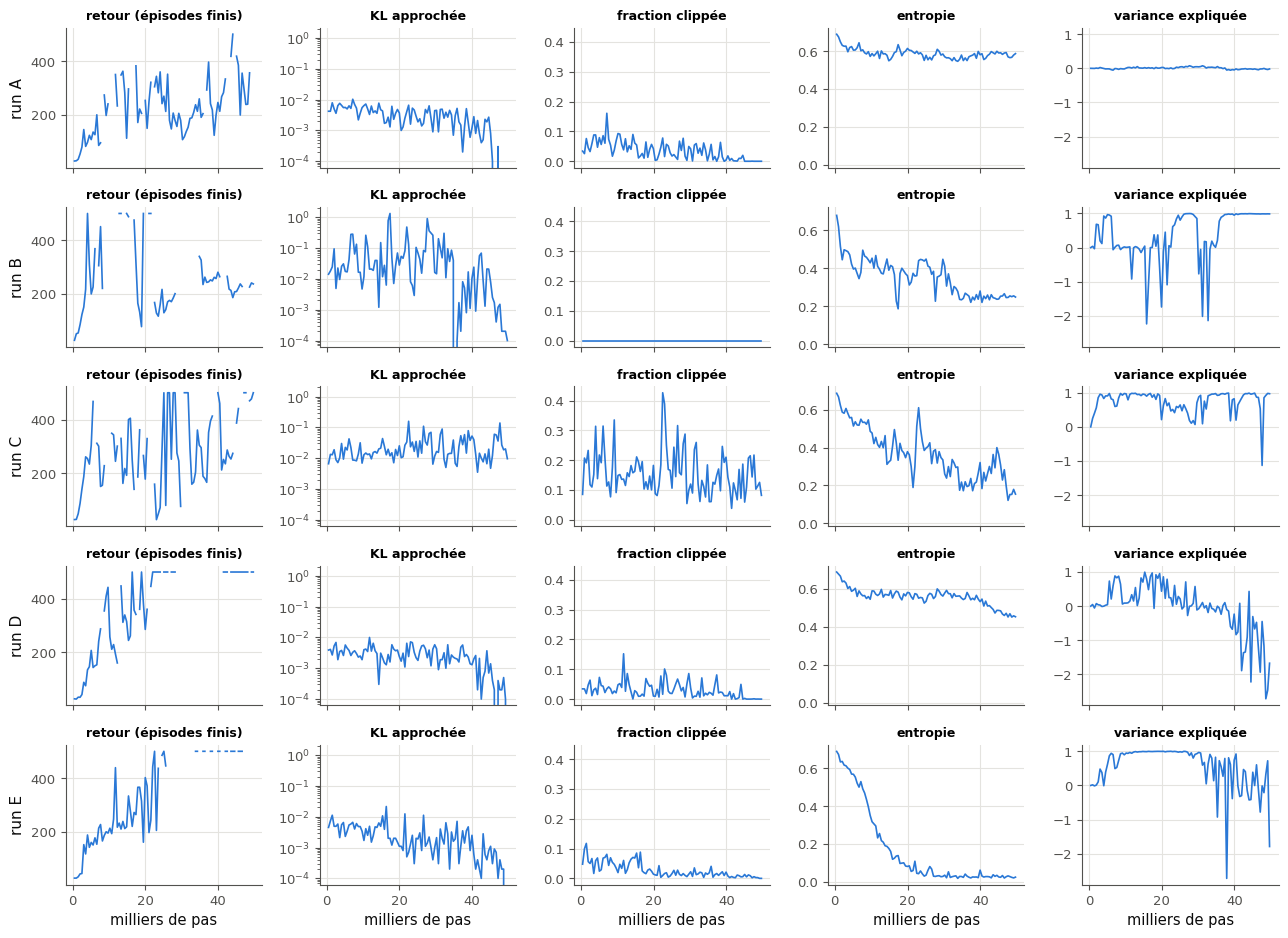

In [50]:
L21 = wbr.precomputed("l21")                 # five runs of the reference PPO, 50 000 steps each (protocol inside)
RUNS_21 = L21["runs"]                        # letter -> its log: one value per iteration, the keys of wbr.LOG_KEYS
PANELS_21 = (("mean_return", "retour (épisodes finis)"), ("approx_kl", "KL approchée"), ("clipfrac", "fraction clippée"),
             ("entropy", "entropie"), ("explained_variance", "variance expliquée"))


def plot_logs_21(axes, logs, **kwargs):
    """The five curves of a PPO log, one per panel, against the environment step (in thousands)."""
    steps = np.asarray(logs["step"]) / 1000
    for ax, (key, title) in zip(axes, PANELS_21):
        ax.plot(steps, np.asarray(logs[key], dtype=float), **kwargs)
        ax.set_title(title, fontsize=9)


fig_21, axes_21 = plt.subplots(len(RUNS_21), len(PANELS_21), figsize=(13, 1.9 * len(RUNS_21)), sharex=True,
                               sharey="col")
for row_21, letter_21 in zip(axes_21, sorted(RUNS_21)):
    plot_logs_21(row_21, RUNS_21[letter_21], color="C0", lw=1.2)
    row_21[0].set_ylabel(f"run {letter_21}", fontsize=11)
for ax_21 in axes_21[-1]:
    ax_21.set_xlabel("milliers de pas")
axes_21[0, 1].set_yscale("log")
plt.tight_layout()
plt.show()

In [51]:
healthy_21, lr_high_21, no_clip_21, entropy_sign_21, no_critic_21 = "D", "C", "B", "E", "A"

In [52]:
wb.record("B8.21a", "D", mistakes={"le run aux réglages de référence n'a aucune courbe anormale : reprends tes cinq panneaux un par un": {"A", "B", "C", "E"}})
wb.record("B8.21b", "C", mistakes={"des pas trop grands poussent sans cesse des ratios hors de l'intervalle du clip : quelle courbe le compte ?": {"A", "B", "D", "E"}})
wb.record("B8.21c", "B", mistakes={"sans clipping, aucun ratio n'est jamais rogné : quelle courbe compte les ratios rognés ?": {"A", "C", "D", "E"}})
wb.record("B8.21d", "E", mistakes={"un bonus d'entropie de mauvais signe récompense une politique qui ne doute plus : quelle courbe le montre ?": {"A", "B", "C", "D"}})
wb.record("B8.21e", "A", mistakes={"un critique qui n'apprend pas ne prédit pas les retours : quelle courbe le mesure ?": {"B", "C", "D", "E"}})

WB_ANSWER {"hash": "87e63a630780ef752ab937330eb6142187219b9d8cce21f0b1de0a29a0cb45a3", "id": "B8.21a", "kind": "str", "mistakes": {"1b453e29e5546a0974cf0d557abcd516f4f5b98713700eb9397115bd0a575dfd": "le run aux réglages de référence n'a aucune courbe anormale : reprends tes cinq panneaux un par un", "81681540b534c0f297abce896f867c6162f91602497d70c42c06d224d1d81778": "le run aux réglages de référence n'a aucune courbe anormale : reprends tes cinq panneaux un par un", "8e8b06dcc9178a4812d0d79472979fb5ec6aeebcebf788acd5dbd3d60334cbab": "le run aux réglages de référence n'a aucune courbe anormale : reprends tes cinq panneaux un par un", "9749e9c0709fa4f507d02b391c722f6a44e07ff0a59b9c01484440614a5a5cbd": "le run aux réglages de référence n'a aucune courbe anormale : reprends tes cinq panneaux un par un"}}
📝 Ex B8.21a : réponse enregistrée (str).
WB_ANSWER {"hash": "38c415fc649804993b51c71639888e94a338c797e618bfd129672b0224cdf1b0", "id": "B8.21b", "kind": "str", "mistakes": {"01b56f0e78bf491

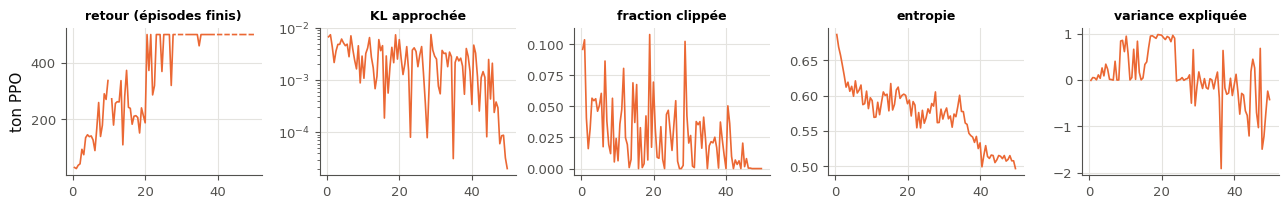

In [53]:
# Your PPO of B8.20 read the same way: its five curves (this session's log, or the one saved with your agent)
logs_own_21 = globals().get("LOGS_20")
if logs_own_21 is None:
    try:
        loaded_21 = wbr.load_agent(AGENT_KEY_20, build=ActorCritic20)
    except NotImplementedError:
        loaded_21 = None
    logs_own_21 = loaded_21[1]["logs"] if loaded_21 is not None else None
if logs_own_21 is None or not all(k in logs_own_21 for k, _ in PANELS_21):
    print("⏳ Ex B8.21 : pas de journal de ton PPO (B8.20 n'a pas encore tourné, ou ses journaux n'ont pas les clés de "
          "wbr.LOG_KEYS) : la figure ci-dessus suffit pour l'exercice.")
else:
    fig_own_21, axes_own_21 = plt.subplots(1, len(PANELS_21), figsize=(13, 2.2))
    plot_logs_21(axes_own_21, logs_own_21, color="C1", lw=1.2)
    axes_own_21[1].set_yscale("log")                     # as in the figure of the five runs
    axes_own_21[0].set_ylabel("ton PPO", fontsize=11)
    plt.tight_layout()
    plt.show()

### Ex B8.22 — Hyperparamètres de PPO : ε du clip, λ, nombre d'epochs — robustesse sur trois graines 🔬 ★★★ ⏱️ 45 min 🚀
**Objectif :** mesurer sur trois graines l'effet de l'ε du clip, du λ de GAE et du nombre d'epochs sur l'apprentissage de PPO, et dire ce que trois graines permettent de conclure.  
**Prérequis :** Ex B8.20, B8.21 · 🔬 B8.15 · fiche §208.4 (« GAE »), §208.5, §208.6 (« Des hyperparamètres qui comptent », « Rapporter plusieurs graines ») · **Fil rouge :** CartPole · **Parcours :** C

Sept réglages de PPO : la référence (`SETTINGS_20`), et six variantes qui changent **un** hyperparamètre : `clip_eps` 0,1 ou 0,4 (au lieu de 0,2), `gae_lambda` 0,8 ou 1 (au lieu de 0,95), `n_epochs` 4 ou 20 (au lieu de 10). **Contrat** de `summary_22(logs)` : elle reçoit un journal au format de `train_ppo_20` (un dictionnaire de listes, une valeur par itération, avec au moins `"step"` et `"mean_return"`) et rend un dictionnaire :
- `"auc"` : la moyenne des valeurs **finies** de `logs["mean_return"]` (l'aire sous la courbe, divisée par sa longueur ; une itération où aucun épisode ne finit vaut `nan` et ne compte pas) ;
- `"first_475"` : le premier `logs["step"]` dont le retour atteint 475 (475 compris), un `int`, ou `None` s'il n'y en a pas ;
- le journal n'est pas modifié.

La vérification essaie ta fonction sur trois petits journaux (des `nan`, un retour qui n'atteint jamais 475, un 475 tout juste) et sur un run précalculé. Puis l'expérience : en **mode rapide**, les runs viennent d'un fichier précalculé (`wbr.precomputed("p22")`) : le PPO de référence, 50 000 pas, trois graines par réglage, évalué à la fin sur 100 épisodes déterministes ; la cellule rejoue d'abord 4 itérations d'un run pour vérifier qu'il retombe sur le fichier. En **mode complet** 🚀 (`FAST_MODE = False`), elle entraîne **ton** PPO de B8.20 sur les sept réglages et les trois graines, `STEPS_20` pas chacun (100 000), soit une vingtaine de minutes de CPU. La figure trace la médiane et l'intervalle des trois graines, un panneau par hyperparamètre ; le tableau donne, par graine, ton `summary_22` et l'évaluation finale.

Dans tes notes : quel hyperparamètre change le plus l'aire sous la courbe, et lequel le moins ? Les intervalles se recouvrent-ils ? Une variante qui apprend plus vite apprend-elle aussi plus sûrement (la dispersion, l'évaluation finale) ? Que changent 20 epochs à la KL approchée et à la fraction clippée (`runs_22[...]["approx_kl"]`), et pourquoi ? Avec trois graines, que peux-tu affirmer, et que faudrait-il pour affirmer plus (208.6) ? Quel réglage choisirais-tu pour le défi B8.28, et pourquoi ?

In [54]:
P22 = wbr.precomputed("p22")                   # the reference PPO: 7 settings x 3 seeds x 50 000 steps (protocol inside)
CONFIGS_22 = P22["protocol"]["configs"]        # name -> what it changes in SETTINGS_20 ("reference": nothing)
SEEDS_22 = P22["protocol"]["seeds"]
GROUPS_22 = {"ε du clip": ("clip_0.1", "reference", "clip_0.4"), "λ de GAE": ("lambda_0.8", "reference", "lambda_1"),
             "epochs": ("epochs_4", "reference", "epochs_20")}
REPLAY_ITERATIONS_22 = 4                       # the prefix of one recorded run that this notebook trains again
print(CONFIGS_22)


def same_log_22(a, b):
    """True when two logs hold the same lists (nan equal to nan)."""
    return a.keys() == b.keys() and all(np.array_equal(np.asarray(a[k], dtype=float), np.asarray(b[k], dtype=float),
                                                       equal_nan=True) for k in a)

{'reference': {}, 'clip_0.1': {'clip_eps': 0.1}, 'clip_0.4': {'clip_eps': 0.4}, 'lambda_0.8': {'gae_lambda': 0.8}, 'lambda_1': {'gae_lambda': 1.0}, 'epochs_4': {'n_epochs': 4}, 'epochs_20': {'n_epochs': 20}}


In [55]:
def summary_22(logs):
    """Two numbers of a PPO log (a dict of lists, one value per iteration, with at least "step" and "mean_return"):
    "auc", the mean of the finite values of logs["mean_return"]; "first_475", the first logs["step"] whose
    logs["mean_return"] is at least 475 (an int), or None if there is none. The log is left unchanged."""
    returns = np.asarray(logs["mean_return"], dtype=float)          # an iteration without a finished episode: nan
    finite = returns[np.isfinite(returns)]
    first = next((int(step) for step, r in zip(logs["step"], returns) if r >= 475), None)   # nan >= 475 is False
    return {"auc": float(finite.mean()), "first_475": first}


ok_22 = False
with checked("B8.22"):
    nan_22 = float("nan")
    cases_22 = {"un journal avec des itérations sans épisode fini (nan)": {"step": [512, 1024, 1536, 2048, 2560],
                                                                          "mean_return": [20.0, nan_22, 480.0, nan_22, 500.0]},
                "un journal qui n'atteint jamais 475": {"step": [512, 1024, 1536], "mean_return": [30.0, 474.9, nan_22]},
                "un journal qui atteint 475 tout juste, puis retombe": {"step": [512, 1024, 1536],
                                                                      "mean_return": [100.0, 475.0, 300.0]},
                f"le run précalculé « reference », graine {SEEDS_22[0]}": P22["runs"][f"reference/{SEEDS_22[0]}"]}
    good_22 = []
    for label_22, logs_22 in cases_22.items():
        given_22 = copy.deepcopy(logs_22)
        got_22 = summary_22(given_22)
        want_22 = wbr.log_summary(logs_22)
        if not returned("B8.22", "summary_22", got_22):
            good_22.append(False)
            continue
        if not isinstance(got_22, dict) or set(got_22) != {"auc", "first_475"}:
            print(f"❌ Ex B8.22 : summary_22 doit rendre un dictionnaire aux clés 'auc' et 'first_475', reçu {got_22!r}.")
            good_22.append(False)
            continue
        try:
            auc_22 = float(got_22["auc"])
        except (TypeError, ValueError):
            auc_22 = nan_22
        good_22.append(abs(auc_22 - want_22["auc"]) <= 1e-9 * max(1.0, abs(want_22["auc"])))
        if not good_22[-1]:
            print(f"❌ Ex B8.22 : summary_22, auc : attendu {want_22['auc']:.6g}, reçu {got_22['auc']!r} ({label_22}) ; "
                  "une itération sans épisode fini (nan) ne compte pas dans la moyenne.")
        first_22 = got_22["first_475"]
        good_22.append(first_22 == want_22["first_475"] and (first_22 is None or isinstance(first_22, (int, np.integer))))
        if not good_22[-1]:
            print(f"❌ Ex B8.22 : summary_22, first_475 : attendu {want_22['first_475']!r}, reçu {first_22!r} ({label_22}) "
                  "; c'est le premier logs['step'] dont le retour atteint 475 (475 compris), un entier, None s'il n'y "
                  "en a pas.")
        if not same_log_22(given_22, logs_22):
            print(f"❌ Ex B8.22 : summary_22 a modifié le journal qu'on lui donne ({label_22}).")
            good_22.append(False)
    ok_22 = all(good_22)
    verdict("B8.22", ok_22, f"summary_22 rend l'aire et le premier pas à 475 sur les {len(cases_22)} journaux d'essai.",
            "summary_22 ne rend pas encore ce qu'attend la suite : corrige les lignes ci-dessus.")

✅ Ex B8.22 : summary_22 rend l'aire et le premier pas à 475 sur les 4 journaux d'essai.


✅ Ex B8.22 : « reference », graine 220, rejoué sur 4 itérations : KL approchée [0.0065, 0.0059, 0.0037, 0.0039], comme dans le fichier : les courbes ci-dessous sont celles de ce code.


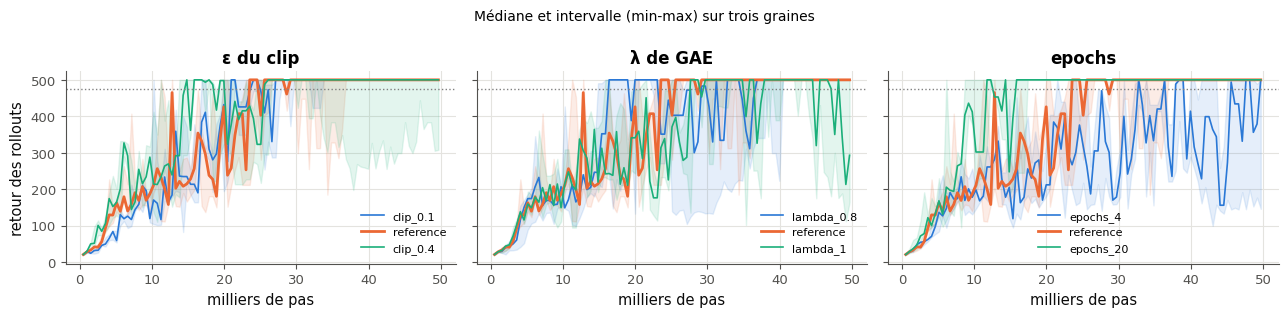

réglage     | aire par graine (médiane) | 1er pas à 475 par graine | évaluation déterministe par graine
reference   | [321, 340, 336] (336) | ['11 k', '24 k', '20 k'] | [500, 500, 500]
clip_0.1    | [318, 319, 329] (319) | ['10 k', '22 k', '21 k'] | [500, 500, 500]
clip_0.4    | [372, 384, 320] (372) | ['16 k', '15 k', '11 k'] | [500, 500, 491]
lambda_0.8  | [274, 322, 346] (322) | ['16 k', '20 k', '15 k'] | [500, 500, 500]
lambda_1    | [349, 293, 311] (311) | ['21 k', '16 k', '16 k'] | [500, 224, 500]
epochs_4    | [279, 290, 214] (279) | ['26 k', '24 k', '22 k'] | [494, 500, 191]
epochs_20   | [408, 406, 409] (408) | ['12 k', '6 k', '12 k'] | [500, 500, 500]


In [56]:
# The 7 settings on three seeds (fast mode: the reference PPO, precomputed, after replaying a prefix; full mode: your
# PPO of B8.20 on every setting and seed, 🚀), then the median and the range of the three seeds, and your summary_22
protocol_22 = P22["protocol"]
if FAST_MODE:
    runs_22 = P22["runs"]
    _, replay_22 = wbr.train_ppo(SEEDS_22[0], protocol_22["steps"], {**SETTINGS_20, **CONFIGS_22["reference"]},
                                 callback=lambda iteration, agent, logs: iteration >= REPLAY_ITERATIONS_22)
    recorded_22 = runs_22[f"reference/{SEEDS_22[0]}"]["approx_kl"][:REPLAY_ITERATIONS_22]
    replayed_22 = [round(v, 4) for v in replay_22["approx_kl"]]
    if np.allclose(replayed_22, recorded_22, atol=2e-4):
        print(f"✅ Ex B8.22 : « reference », graine {SEEDS_22[0]}, rejoué sur {REPLAY_ITERATIONS_22} itérations : KL "
              f"approchée {replayed_22}, comme dans le fichier : les courbes ci-dessous sont celles de ce code.")
    else:
        print(f"ℹ️ « reference », graine {SEEDS_22[0]}, rejoué sur {REPLAY_ITERATIONS_22} itérations : KL approchée "
              f"{replayed_22}, le fichier dit {recorded_22} : une autre machine arrondit autrement, et un écart minuscule "
              "change la suite d'un run de RL (208.6). Les courbes ci-dessous restent celles du fichier.")
elif not (ok_22 and ok_20):
    runs_22 = None
    print("⏳ Ex B8.22 : le mode complet entraîne ton PPO de B8.20 sur chaque réglage ; il attend que les vérifications de "
          "B8.20 et de B8.22 passent.")
else:
    runs_22 = {}
    for name_22, change_22 in CONFIGS_22.items():
        for seed_22 in SEEDS_22:
            start_22 = time.perf_counter()
            agent_22, logs_22 = train_ppo_20(seed_22, STEPS_20, {**SETTINGS_20, **change_22})
            runs_22[f"{name_22}/{seed_22}"] = {**{k: list(logs_22[k]) for k in ("step", "mean_return", "approx_kl",
                                                                                "clipfrac")},
                                              "eval": wbr.evaluate(wbr.greedy_logits(agent_22), 100, EVAL_SEED)["mean_return"]}
            print(f"{name_22}, graine {seed_22} : {time.perf_counter() - start_22:.0f} s")
if runs_22 and ok_22:
    def filled_curve_22(values):
        """The rollout returns with each nan (no finished episode) replaced by the last value seen, for the figure."""
        out, last = [], np.nan
        for v in np.asarray(values, dtype=float):
            last = v if np.isfinite(v) else last
            out.append(last)
        return np.array(out)

    fig_22, axes_22 = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
    for ax_22, (group_22, names_22) in zip(axes_22, GROUPS_22.items()):
        for name_22 in names_22:
            hs_22 = [runs_22[f"{name_22}/{s}"] for s in SEEDS_22]
            b_22 = wbr.band([filled_curve_22(h["mean_return"]) for h in hs_22])
            x_22 = np.asarray(hs_22[0]["step"]) / 1000
            line_22, = ax_22.plot(x_22, b_22["median"], label=name_22, lw=2 if name_22 == "reference" else 1.2)
            ax_22.fill_between(x_22, b_22["low"], b_22["high"], color=line_22.get_color(), alpha=0.12)
        ax_22.axhline(wbr.SOLVED, color="gray", ls=":", lw=1)
        ax_22.set(title=group_22, xlabel="milliers de pas")
        ax_22.legend(fontsize=8)
    axes_22[0].set_ylabel("retour des rollouts")
    fig_22.suptitle("Médiane et intervalle (min-max) sur trois graines", fontsize=10)
    plt.tight_layout()
    plt.show()
    print(f"{'réglage':11s} | aire par graine (médiane) | 1er pas à 475 par graine | évaluation déterministe par graine")
    for name_22 in CONFIGS_22:
        hs_22 = [runs_22[f"{name_22}/{s}"] for s in SEEDS_22]
        sums_22 = [summary_22(h) for h in hs_22]
        aucs_22 = [s["auc"] for s in sums_22]
        firsts_22 = ["jamais" if s["first_475"] is None else f"{round(s['first_475'] / 1000)} k" for s in sums_22]
        evals_22 = [round(h["eval"]) for h in hs_22]
        print(f"{name_22:11s} | {[round(a) for a in aucs_22]} ({fr(float(np.median(aucs_22)), 0)}) | {firsts_22} | "
              f"{evals_22}")

### Ex B8.23 — Prédire : l'agent PPO face à une gravité doublée ou à un mât deux fois plus long 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, avant de le mesurer, ce que devient un agent PPO quand la gravité double ou que le mât s'allonge.  
**Prérequis :** Ex B8.20 · fiche §208.1 (« CartPole, vu de près »), §208.8 (« Généraliser au-delà de son environnement ») · **Fil rouge :** CartPole · **Parcours :** C

Ton agent de B8.20 a appris sur CartPole-v1 : $g = 9{,}8$ m/s², un mât de 1 m (`length = 0.5`, la **moitié** du mât, comme dans gymnasium). Que devient-il sur une autre physique, **sans réentraînement** ? Six agents PPO de référence (le protocole de B8.20 : `wbr.train_ppo`, 50 000 pas, graines 0 à 5) ont été évalués sur 100 épisodes déterministes (`wbr.evaluate(..., gravity=...)` ou `length=...`, qui recalcule ce qu'il faut). **Avant d'exécuter**, écris tes trois prédictions sur ces six agents :
- a) `gravity_23` : avec une **gravité doublée** (19,6 m/s²), la **médiane** des six retours moyens : `0` si elle reste au moins à 475, `1` si elle est entre 200 et 475, `2` si elle tombe sous 200 ;
- b) `length_23` : avec un mât **deux fois plus long** (`length = 1.0`), la même question, les mêmes tranches ;
- c) `longer_23` : avec un mât **quatre fois plus long** (`length = 2.0`), combien des six agents tiennent-ils encore au moins 475 ? Un entier de 0 à 6.

La cellule d'expérience n'affiche rien tant que tes trois prédictions ne sont pas écrites ; elle donne ensuite le tableau des six agents (sur deux jeux de graines d'évaluation), évalue **ton** agent de B8.20 sur les quatre physiques (si tu n'en as pas, l'agent de référence le remplace, une ligne ℹ️ le dit), et vérifie tes prédictions.

Dans tes notes, avant d'exécuter : un mât plus long tombe-t-il plus vite ou plus lentement ? Une gravité plus forte rend-elle le problème plus dur pour un humain ? Qu'est-ce qu'un agent entraîné sur une seule physique a pu apprendre qui ne vaut que pour elle ?

In [57]:
gravity_23, length_23, longer_23 = 0, 0, 0

In [58]:
wb.record("B8.23a", 0, choices=[0, 1, 2], mistakes={"lis la ligne « gravité doublée » du tableau : la médiane des six agents": {1, 2}}, prediction=True,
          fractional="la réponse est le numéro d'une tranche : 0, 1 ou 2")
wb.record("B8.23b", 0, choices=[0, 1, 2], mistakes={"lis la ligne « mât deux fois plus long » du tableau : la médiane des six agents": {1, 2}}, prediction=True,
          fractional="la réponse est le numéro d'une tranche : 0, 1 ou 2")
wb.record("B8.23c", 0, choices=[0, 1, 2, 3, 4, 5, 6], mistakes={"compte, ligne « mât quatre fois plus long », les agents au-dessus de 475": {1, 2, 3, 4, 5, 6}}, prediction=True,
          fractional="la réponse est un nombre d'agents, de 0 à 6")

WB_ANSWER {"choices": ["0", "1", "2"], "fractional": "la réponse est le numéro d'une tranche : 0, 1 ou 2", "hash": "78f3c00ed530caf32532255f4ca6b8a3b782fca35457f7ee06cec3cdc29fb07c", "id": "B8.23a", "kind": "int", "magnitude": null, "mistakes": {"22ca29ee494f79d3437be5472704b9d0cfb7dacae223ba74d2ce972cfe0c9b42": "lis la ligne « gravité doublée » du tableau : la médiane des six agents", "7abdafcb67def6a929f76d794b1aba576b09dc2d1f8efa4cb0ab061f6039bebc": "lis la ligne « gravité doublée » du tableau : la médiane des six agents"}, "prediction": true, "sign": 0}
📝 Ex B8.23a : réponse enregistrée (int).
WB_ANSWER {"choices": ["0", "1", "2"], "fractional": "la réponse est le numéro d'une tranche : 0, 1 ou 2", "hash": "406ee76636a44fd545b10500c9de82659f3d45955ab3ccbc7734686a8bb6b078", "id": "B8.23b", "kind": "int", "magnitude": null, "mistakes": {"2ea9f5d5457b0dd49b3cf0678bc379383c8c318a828b868e16379b0d9ef93eed": "lis la ligne « mât deux fois plus long » du tableau : la médiane des six agents"

In [59]:
if any(answer is ... or answer is None for answer in [gravity_23, length_23, longer_23]):
    print("⏳ Ex B8.23 : écris d'abord tes trois prédictions (gravity_23, length_23, longer_23) dans la cellule précédente.")
else:
    C23 = wbr.precomputed("c23")                  # six reference PPO agents (the protocol of B8.20, seeds 0 to 5)
    PHYSICS_23 = C23["protocol"]["physics"]        # name -> the constants it changes (length is HALF the pole)
    NAMES_23 = {"normal": "CartPole-v1", "gravity_x2": "gravité doublée", "length_x2": "mât deux fois plus long",
                "length_x4": "mât quatre fois plus long"}
    seeds_eval_23 = C23["protocol"]["eval_seeds"]
    print(f"Les six agents de référence, 100 épisodes déterministes (graines d'évaluation {seeds_eval_23[0]}, puis "
          f"{seeds_eval_23[1]}) :")
    for name_23 in PHYSICS_23:
        means_23 = [row[f"{name_23}/{seeds_eval_23[0]}"]["mean"] for row in C23["rows"]]
        other_23 = [row[f"{name_23}/{seeds_eval_23[1]}"]["mean"] for row in C23["rows"]]
        held_23 = sum(m >= wbr.SOLVED for m in means_23)
        print(f"  {NAMES_23[name_23]:26s} {[round(m) for m in means_23]} · médiane {fr(float(np.median(means_23)), 1)} · "
              f"{held_23} sur 6 au-dessus de {wbr.SOLVED:g} · autres graines : médiane {fr(float(np.median(other_23)), 1)}")
    agent_23, source_23 = load_agent_20()
    print(f"\nTon agent de B8.20 (source {source_23!r}), sur les mêmes 100 épisodes :")
    for name_23, change_23 in PHYSICS_23.items():
        ev_23 = wbr.evaluate(agent_23, 100, seeds_eval_23[0], **change_23)
        print(f"  {NAMES_23[name_23]:26s} {fr(ev_23['mean_return'], 1)} (le plus court : {min(ev_23['returns']):.0f} pas)")
    wb.check("B8.23a", gravity_23)
    wb.check("B8.23b", length_23)
    wb.check("B8.23c", longer_23)

Les six agents de référence, 100 épisodes déterministes (graines d'évaluation 8000, puis 2323) :
  CartPole-v1                [500, 500, 500, 284, 500, 500] · médiane 500,0 · 5 sur 6 au-dessus de 475 · autres graines : médiane 500,0
  gravité doublée            [500, 500, 500, 206, 500, 500] · médiane 500,0 · 5 sur 6 au-dessus de 475 · autres graines : médiane 500,0
  mât deux fois plus long    [500, 500, 500, 267, 500, 500] · médiane 500,0 · 5 sur 6 au-dessus de 475 · autres graines : médiane 500,0
  mât quatre fois plus long  [19, 18, 18, 262, 18, 18] · médiane 18,3 · 0 sur 6 au-dessus de 475 · autres graines : médiane 18,2

Ton agent de B8.20 (source 'solution'), sur les mêmes 100 épisodes :


  CartPole-v1                500,0 (le plus court : 500 pas)


  gravité doublée            500,0 (le plus court : 500 pas)


  mât deux fois plus long    500,0 (le plus court : 500 pas)
  mât quatre fois plus long  18,6 (le plus court : 16 pas)
✅ Ex B8.23a : Exact !
✅ Ex B8.23b : Bien joué !
✅ Ex B8.23c : C'est ça !


Dans tes notes, après l'expérience : ton agent se comporte-t-il comme les six agents de référence ? L'agent de la graine qui ne résout pas CartPole réagit-il comme les autres, et qu'en conclus-tu sur ce qu'il a appris ? Une évaluation sur une seule physique suffit-elle à dire qu'un agent « sait » tenir un mât ?

### Ex B8.24 — Robustesse : modifier la physique de CartPole et mesurer la chute du retour 🔬 ★★ ⏱️ 25 min
**Objectif :** modifier correctement la physique de CartPole, puis mesurer comment le retour de ton agent chute quand la gravité ou la longueur du mât s'éloignent de celles de l'entraînement.  
**Prérequis :** 🔮 B8.23 · Ex B8.20 · fiche §208.8 (« Généraliser au-delà de son environnement », « De la simulation au réel ») · **Fil rouge :** CartPole · **Parcours :** C

**Contrat** des deux fonctions de la cellule suivante :
- `set_physics_24(env, gravity=None, length=None)` reçoit un CartPole fait par `gym.make` (ou `wbr.make_env()`), lui donne une autre gravité et/ou une autre **demi**-longueur de mât (`None` : inchangée), sur `env.unwrapped`, en gardant cohérentes **toutes** les constantes que `CartPoleEnv.__init__` en déduit, et rend `env` ;
- `robustness_24(policy, name, factors, n_episodes=EPISODES_24, seed=EVAL_SEED)` rend la liste des retours moyens de `policy` quand la constante `name` (`"gravity"` ou `"length"`) vaut sa valeur par défaut (`DEFAULTS_24`) multipliée par chaque facteur : un `float` par facteur, chacun `wbr.evaluate(policy, n_episodes, seed, env=env)["mean_return"]` avec `env` un nouveau `wbr.make_env()` modifié par ta `set_physics_24` (les autres constantes inchangées).

La vérification compare tes constantes à celles de `wbr.make_env(gravity=..., length=...)` et rejoue un épisode avec les mêmes actions sur les deux environnements ; puis elle essaie `robustness_24` sur la règle d'une ligne de 208.1. L'expérience balaie la gravité et la longueur du mât de `FACTORS_24` avec ton agent de B8.20 (`EPISODES_24` épisodes par point, une dizaine de secondes), trace tes deux courbes sur la médiane et l'intervalle des six agents de référence de B8.23, donne la chute du retour en pourcentage, puis évalue ton agent sur le mât quatre fois plus long avec et sans le recalcul des constantes.

Dans tes notes : à partir de quel facteur ton agent passe-t-il sous 475, dans chaque direction ? La chute est-elle progressive ou brutale ? Pourquoi un agent peut-il tenir une gravité triplée et tomber avec un mât quatre fois plus long, alors que la règle d'une ligne de 208.1 tient ce mât-là ? Que change l'oubli de `polemass_length`, et pourquoi le voit-on ou non sur le retour ? Comment entraînerais-tu un agent pour qu'il tienne toute la plage (208.8) ?

In [60]:
GRID_24 = wbr.precomputed("c23")               # the six reference agents of B8.23, evaluated on the grids below
FACTORS_24 = {"gravity": GRID_24["protocol"]["gravity_factors"], "length": GRID_24["protocol"]["length_factors"]}
DEFAULTS_24 = {"gravity": 9.8, "length": 0.5}  # CartPole-v1: g in m/s², length = HALF the pole, in m
EPISODES_24 = 20                               # episodes per point for your agent (the reference: 50)
print(FACTORS_24)

{'gravity': [0.5, 1.0, 1.5, 2.0, 3.0, 4.0], 'length': [0.25, 0.5, 1.0, 2.0, 3.0, 4.0]}


In [61]:
def set_physics_24(env, gravity=None, length=None):
    """Give a CartPole made by gym.make another gravity and/or another half-length of the pole (None: unchanged), on
    env.unwrapped, with every constant that CartPoleEnv.__init__ derives from them kept consistent; returns env."""
    core = env.unwrapped
    if gravity is not None:
        core.gravity = float(gravity)
    if length is not None:
        core.length = float(length)
    core.total_mass = core.masspole + core.masscart          # computed once by __init__...
    core.polemass_length = core.masspole * core.length      # ...and used by step(): recompute both
    return env


def robustness_24(policy, name, factors, n_episodes=EPISODES_24, seed=EVAL_SEED):
    """The mean return of `policy` on CartPole-v1 whose `name` ("gravity" or "length") is its default value
    (DEFAULTS_24) times each factor: a list of floats, one per factor, each wbr.evaluate(policy, n_episodes, seed,
    env=env)["mean_return"] with env a new wbr.make_env() changed by set_physics_24."""
    out = []
    for factor in factors:
        env = set_physics_24(wbr.make_env(), **{name: DEFAULTS_24[name] * factor})
        out.append(float(wbr.evaluate(policy, n_episodes, seed, env=env)["mean_return"]))
    return out


ok_24 = False
with checked("B8.24"):
    good_24 = []
    for label_24, change_24 in (("gravité doublée", {"gravity": 19.6}), ("mât deux fois plus long", {"length": 1.0}),
                                ("gravité et mât changés ensemble", {"gravity": 4.9, "length": 0.25}),
                                ("rien de changé", {})):
        env_24 = wbr.make_env()
        out_24 = set_physics_24(env_24, **change_24)
        if not returned("B8.24", "set_physics_24", out_24):
            good_24.append(False)
            continue
        got_24, want_24 = wbr.physics_of(env_24), wbr.physics_of(wbr.make_env(**change_24))
        wrong_24 = {k: (want_24[k], got_24[k]) for k in want_24 if not math.isclose(got_24[k], want_24[k], rel_tol=1e-12)}
        good_24.append(not wrong_24 and out_24 is env_24)
        if wrong_24:
            print(f"❌ Ex B8.24 : set_physics_24, {label_24} : attendu "
                  + ", ".join(f"{k} = {w:g}" for k, (w, _) in wrong_24.items()) + " ; reçu "
                  + ", ".join(f"{k} = {g:g}" for k, (_, g) in wrong_24.items()) + ".")
            continue
        if out_24 is not env_24:
            print(f"❌ Ex B8.24 : set_physics_24 doit rendre l'environnement qu'il a reçu (env), reçu un autre objet.")
            continue
        ref_24 = wbr.make_env(**change_24)                 # the same episode, the same actions: the same states?
        a_24, _ = env_24.reset(seed=24)
        b_24, _ = ref_24.reset(seed=24)
        states_24 = [(a_24, b_24)]
        for t_24 in range(40):
            action_24 = int(t_24 % 3 == 0)
            a_24, _, ta_24, _, _ = env_24.step(action_24)
            b_24, _, tb_24, _, _ = ref_24.step(action_24)
            states_24.append((a_24, b_24))
            if ta_24 or tb_24:
                break
        moves_24 = all(np.allclose(x, y, atol=1e-6) for x, y in states_24)
        good_24.append(moves_24)
        verdict("B8.24", moves_24, f"set_physics_24, {label_24} : les constantes et un épisode de {len(states_24) - 1} "
                                   "pas sont ceux de la référence.",
                f"set_physics_24, {label_24} : un épisode joué avec les mêmes actions s'écarte de la référence.")
    rule_24 = wbr.rule_policy
    for name_24, factors_24 in (("gravity", [2.0, 1.5]), ("length", [2.0, 4.0])):   # not sorted, on purpose
        got_24 = robustness_24(rule_24, name_24, list(factors_24), n_episodes=5, seed=2424)
        want_24 = [wbr.evaluate(rule_24, 5, 2424, **{name_24: DEFAULTS_24[name_24] * f})["mean_return"]
                   for f in factors_24]
        good_24.append(same("B8.24", f"robustness_24(règle de 208.1, {name_24!r}, {factors_24}, 5 épisodes) : chaque "
                                     "facteur multiplie la valeur par défaut", got_24, want_24))
    ok_24 = all(good_24)

✅ Ex B8.24 : set_physics_24, gravité doublée : les constantes et un épisode de 16 pas sont ceux de la référence.
✅ Ex B8.24 : set_physics_24, mât deux fois plus long : les constantes et un épisode de 22 pas sont ceux de la référence.
✅ Ex B8.24 : set_physics_24, gravité et mât changés ensemble : les constantes et un épisode de 13 pas sont ceux de la référence.
✅ Ex B8.24 : set_physics_24, rien de changé : les constantes et un épisode de 17 pas sont ceux de la référence.


✅ Ex B8.24 : robustness_24(règle de 208.1, 'gravity', [2.0, 1.5], 5 épisodes) : chaque facteur multiplie la valeur par défaut : [478.6, 500.0], comme attendu.


✅ Ex B8.24 : robustness_24(règle de 208.1, 'length', [2.0, 4.0], 5 épisodes) : chaque facteur multiplie la valeur par défaut : [500.0, 500.0], comme attendu.


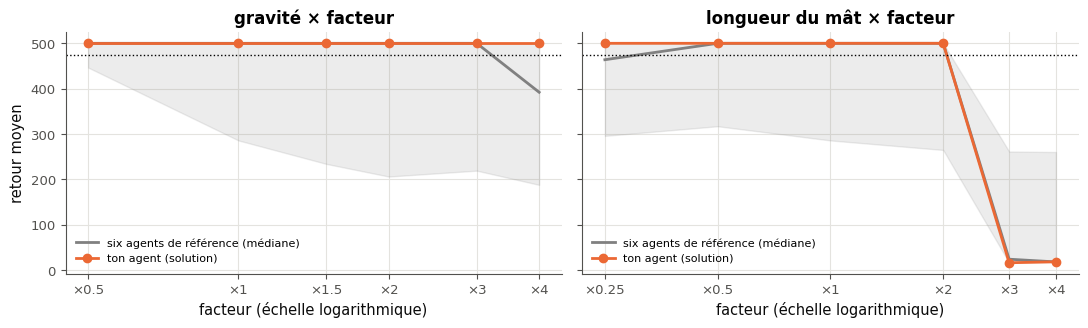

gravity  ×0.5 : 500 (0 %) · ×1 : 500 (0 %) · ×1.5 : 500 (0 %) · ×2 : 500 (0 %) · ×3 : 500 (0 %) · ×4 : 500 (0 %)
length   ×0.25 : 500 (0 %) · ×0.5 : 500 (0 %) · ×1 : 500 (0 %) · ×2 : 500 (0 %) · ×3 : 16 (-97 %) · ×4 : 18 (-96 %)
mât quatre fois plus long, polemass_length oublié : 18,4 ; recalculé : 18,4 (10 s en tout)


In [62]:
# Your agent of B8.20 on the two grids (EPISODES_24 episodes per point), against the six reference agents of B8.23
if not ok_24:
    print("⏳ Ex B8.24 : l'expérience attend que la vérification ci-dessus passe.")
else:
    with checked("B8.24"):
        agent_24, source_24 = load_agent_20()
        start_24 = time.perf_counter()
        mine_24 = {name: robustness_24(agent_24, name, factors) for name, factors in FACTORS_24.items()}
        fig_24, axes_24 = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
        for ax_24, (name_24, factors_24) in zip(axes_24, FACTORS_24.items()):
            b_24 = wbr.band([GRID_24["grid"][f"{name_24}/{s}"] for s in GRID_24["protocol"]["seeds"]])
            ax_24.plot(factors_24, b_24["median"], color="gray", label="six agents de référence (médiane)")
            ax_24.fill_between(factors_24, b_24["low"], b_24["high"], color="gray", alpha=0.15)
            ax_24.plot(factors_24, mine_24[name_24], marker="o", color="C1", label=f"ton agent ({source_24})")
            ax_24.axhline(wbr.SOLVED, color="k", ls=":", lw=1)
            ax_24.set(xscale="log", xlabel="facteur (échelle logarithmique)",
                      title="gravité × facteur" if name_24 == "gravity" else "longueur du mât × facteur")
            ax_24.minorticks_off()
            ax_24.set_xticks(factors_24, [f"×{f:g}" for f in factors_24])
            ax_24.legend(fontsize=8)
        axes_24[0].set_ylabel("retour moyen")
        plt.tight_layout()
        plt.show()
        for name_24, factors_24 in FACTORS_24.items():
            base_24 = mine_24[name_24][factors_24.index(1.0)]
            drops_24 = [f"×{f:g} : {fr(r, 0)} ({fr(100 * (r - base_24) / base_24, 0)} %)" for f, r in
                        zip(factors_24, mine_24[name_24])]
            print(f"{name_24:8s} " + " · ".join(drops_24))
        naive_24 = wbr.make_env()
        naive_24.unwrapped.length = 2.0                    # only the attribute: polemass_length keeps 0.05
        ev_naive_24 = wbr.evaluate(agent_24, EPISODES_24, EVAL_SEED, env=naive_24)["mean_return"]
        ev_right_24 = wbr.evaluate(agent_24, EPISODES_24, EVAL_SEED, env=set_physics_24(wbr.make_env(), length=2.0))
        print(f"mât quatre fois plus long, polemass_length oublié : {fr(ev_naive_24, 1)} ; recalculé : "
              f"{fr(ev_right_24['mean_return'], 1)} ({time.perf_counter() - start_24:.0f} s en tout)")

## Partie C · Les préférences : Bradley-Terry, DPO, un RLHF miniature, la revue de code et le défi

Les modèles de langue sont alignés avec des **préférences** : un humain compare deux réponses, un modèle de récompense apprend ses choix, et PPO l'optimise (le RLHF de 208.7) ; ou bien DPO saute le modèle de récompense. Tu écris d'abord les deux losses de préférences dans ta librairie (B8.25), tu rejoues le RLHF en miniature sur CartPole, avec une vraie récompense cachée et des préférences simulées, pour voir ce que l'agent fait du modèle qu'on lui donne (B8.26), tu confrontes ton PPO à celui de CleanRL (B8.27), puis tu relèves le défi (B8.28).

### Ex B8.25 — bradley_terry_loss et dpo_loss 🔨 ★★ ⏱️ 20 min
**Objectif :** écrire en NumPy la loss d'un modèle de récompense de Bradley-Terry et la loss DPO, stables pour de très grands écarts.  
**Prérequis :** ✏️ B8.6 · fiche §208.7 (« Le modèle de récompense de Bradley-Terry », « DPO : la récompense est cachée dans la politique ») · **mylearn :** `deep_rl.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/deep_rl.py` (créé par `python tools/start_chapter.py B8`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement, sans PyTorch. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb8_deep_rl.py -q` les lance tous dans un terminal.

**Contrat** de `bradley_terry_loss(r_chosen, r_rejected)`, qui rend le triplet `(loss, grad_chosen, grad_rejected)` :
- `loss` $= \frac{1}{n}\sum_i -\log\sigma(r^{c}_i - r^{r}_i)$, un `float` ;
- `grad_chosen` et `grad_rejected` sont les gradients de cette loss **moyenne** (divisés par $n$) par rapport à chaque tableau, de forme `(n,)` : `grad_chosen` $\le 0$ et `grad_rejected` $=$ `-grad_chosen` ;
- la loss **et** les gradients restent finis et exacts pour des écarts de ±1 000 à ±10 000 : $-\log\sigma(d)$ = `np.logaddexp(0, -d)` et $\sigma(-d)$ = `np.exp(-np.logaddexp(0, d))` ; une formule comme $1 - e^d/(1 + e^d)$ donne `nan`.

**Contrat** de `dpo_loss(policy_chosen_logps, policy_rejected_logps, ref_chosen_logps, ref_rejected_logps, beta=0.1)`, qui rend le couple `(loss, margins)` :
- `margins` $= \beta\big[(\log\pi^{c} - \log\pi^{c}_{\text{ref}}) - (\log\pi^{r} - \log\pi^{r}_{\text{ref}})\big]$, **avec** $\beta$, de forme `(n,)` ;
- `loss` $= \frac{1}{n}\sum_i -\log\sigma(\text{margins}_i)$, stable comme ci-dessus : c'est Bradley-Terry appliqué aux récompenses implicites $\beta(\log\pi - \log\pi_{\text{ref}})$ ;
- $\beta > 0$, sinon `ValueError`.

**Pour les deux** : des tableaux de forme `(n,)`, sans diffusion (des formes différentes lèvent `ValueError`, même `(n, 1)` contre `(n,)`) ; les entrées ne sont jamais modifiées ; listes et tableaux float32 acceptés ; les tests comparent à $10^{-6}$ près.

La première cellule de vérification essaie tes fonctions sur la docstring, sur 7 paires contre l'autograd de `-F.logsigmoid(r_c - r_r).mean()`, sur des écarts de −6 000 et +8 000, sur l'exemple de la docstring de `dpo_loss`, sur 6 paires contre l'équation 7 (β = 0,1 et 0,5) et sur β = 0, puis affiche ce que rendent tes fonctions sur les nombres de ✏️ B8.6 (compare à tes réponses). La seconde lance les 46 tests de l'exercice (`-k "test_bradley_terry_loss_ or test_dpo_loss_"`).

Dans tes notes : pourquoi ajouter la même constante à toutes les récompenses ne change-t-il rien ? Que vaut la loss DPO tant que la politique égale la référence ? Que règle $\beta$ ? B8.26 se sert de ta `bradley_terry_loss` pour entraîner un modèle de récompense en PyTorch : comment ses gradients NumPy peuvent-ils remonter dans un réseau ?

In [63]:
with checked("B8.25"):
    loss_25, gc_25, gr_25 = pair("B8.25", "bradley_terry_loss", mylearn.deep_rl.bradley_terry_loss([0.0], [0.0]),
                                 names=("loss", "grad_chosen", "grad_rejected"), floats=("loss",))
    same("B8.25", "bradley_terry_loss([0.0], [0.0]), la loss (log 2)", loss_25, math.log(2))
    same("B8.25", "bradley_terry_loss([0.0], [0.0]), les gradients", np.concatenate([np.ravel(gc_25), np.ravel(gr_25)]),
         [-0.5, 0.5])
    rng_25 = np.random.default_rng(25)
    rc_25, rr_25 = rng_25.normal(0, 3, 7), rng_25.normal(0, 3, 7)
    rc_t, rr_t = torch.tensor(rc_25, requires_grad=True), torch.tensor(rr_25, requires_grad=True)
    want_25 = -F.logsigmoid(rc_t - rr_t).mean()
    want_25.backward()
    loss_25, gc_25, gr_25 = pair("B8.25", "bradley_terry_loss", mylearn.deep_rl.bradley_terry_loss(rc_25.copy(),
                                                                                                    rr_25.copy()),
                                 names=("loss", "grad_chosen", "grad_rejected"), floats=("loss",))
    same("B8.25", "7 paires : la loss contre -F.logsigmoid(...).mean()", loss_25, want_25.item())
    same("B8.25", "7 paires : grad_chosen contre l'autograd (la loss MOYENNE)", gc_25, rc_t.grad.numpy())
    same("B8.25", "7 paires : grad_rejected contre l'autograd", gr_25, rr_t.grad.numpy())
    with np.errstate(all="ignore"):
        loss_25, gc_25, gr_25 = pair("B8.25", "bradley_terry_loss", mylearn.deep_rl.bradley_terry_loss(
            [-3000.0, 4000.0], [3000.0, -4000.0]), names=("loss", "grad_chosen", "grad_rejected"), floats=("loss",))
    same("B8.25", "écarts de -6 000 et +8 000 : la loss (finie, exacte)", loss_25, 3000.0)
    same("B8.25", "écarts de -6 000 et +8 000 : grad_chosen (fini, exact)", gc_25, [-0.5, 0.0])

with checked("B8.25"):
    loss_25, margins_25 = pair("B8.25", "dpo_loss", mylearn.deep_rl.dpo_loss([-10.0, -12.0], [-11.0, -9.0],
                                                                            [-10.5, -11.0], [-10.5, -10.0], beta=0.1),
                               names=("loss", "margins"), floats=("loss",))
    same("B8.25", "l'exemple de la docstring de dpo_loss (marges, avec β)", margins_25, [0.1, -0.2])
    rng_25 = np.random.default_rng(250)
    logps_25 = [rng_25.normal(-40, 5, 6) for _ in range(4)]
    for beta_25 in (0.1, 0.5):
        pc, pr, rc, rr = (torch.tensor(a) for a in logps_25)
        margin_t = beta_25 * ((pc - rc) - (pr - rr))
        loss_25, margins_25 = pair("B8.25", "dpo_loss", mylearn.deep_rl.dpo_loss(*[a.copy() for a in logps_25],
                                                                                beta=beta_25),
                                   names=("loss", "margins"), floats=("loss",))
        same("B8.25", f"6 paires, β = {fr(beta_25, 1)} : la loss contre l'équation 7 (torch)", loss_25,
             (-F.logsigmoid(margin_t).mean()).item())
        same("B8.25", f"6 paires, β = {fr(beta_25, 1)} : les marges", margins_25, margin_t.numpy())
    refuses("B8.25", "dpo_loss(..., beta=0)", lambda: mylearn.deep_rl.dpo_loss([0.0], [0.0], [0.0], [0.0], beta=0.0))
    bt_25 = mylearn.deep_rl.bradley_terry_loss([2.3], [1.1])
    dpo_25 = mylearn.deep_rl.dpo_loss([-35.2], [-38.9], [-36.0], [-37.5])
    print(f"✏️ B8.6 avec tes fonctions : loss {float(bt_25[0]):.4f} · gradient {float(np.ravel(bt_25[1])[0]):.4f} · "
          f"marge DPO (β = 0,1) {float(np.ravel(dpo_25[1])[0]):.4f} ← compare à tes réponses de B8.6")

✅ Ex B8.25 : bradley_terry_loss([0.0], [0.0]), la loss (log 2) : 0.69314718, comme attendu.
✅ Ex B8.25 : bradley_terry_loss([0.0], [0.0]), les gradients : [-0.5, 0.5], comme attendu.
✅ Ex B8.25 : 7 paires : la loss contre -F.logsigmoid(...).mean() : 3.08178807, comme attendu.
✅ Ex B8.25 : 7 paires : grad_chosen contre l'autograd (la loss MOYENNE) : un tableau (7,), comme attendu.
✅ Ex B8.25 : 7 paires : grad_rejected contre l'autograd : un tableau (7,), comme attendu.
✅ Ex B8.25 : écarts de -6 000 et +8 000 : la loss (finie, exacte) : 3000.0, comme attendu.
✅ Ex B8.25 : écarts de -6 000 et +8 000 : grad_chosen (fini, exact) : [-0.5, -0.0], comme attendu.
✅ Ex B8.25 : l'exemple de la docstring de dpo_loss (marges, avec β) : [0.1, -0.2], comme attendu.
✅ Ex B8.25 : 6 paires, β = 0,1 : la loss contre l'équation 7 (torch) : 0.50853278, comme attendu.
✅ Ex B8.25 : 6 paires, β = 0,1 : les marges : [0.10238417, 0.76553292, 0.04653492, -0.07544151, 0.78767564, 1.26163107], comme attendu.
✅ Ex 

In [64]:
if written(lambda: mylearn.deep_rl.bradley_terry_loss([0.0], [0.0])):
    run_pytest_group(TEST_DEEP_RL, impl="ref", keyword="test_bradley_terry_loss_ or test_dpo_loss_")   # 46 tests
else:
    print("⏳ Ex B8.25 : les tests attendent tes fonctions bradley_terry_loss et dpo_loss.")

pytest: 46 passed, 117 deselected in 1.94s


### Ex B8.26 — RLHF miniature : un modèle de récompense appris sur des préférences simulées, puis PPO — et le piratage de la récompense 📦 ★★★★ ⏱️ 90 min
**Objectif :** entraîner un modèle de récompense sur des préférences simulées, l'optimiser avec ton PPO, et mesurer ce que l'agent gagne selon le modèle et selon la vraie récompense.  
**Prérequis :** 🔨 B8.25 · Ex B8.20 · fiche §208.7 (« Le modèle de récompense de Bradley-Terry », « Le RLHF », « Le piratage de la récompense ») · **Fil rouge :** CartPole · **Parcours :** C

Le RLHF de 208.7, en miniature et sans humain. Une **vraie récompense**, cachée à l'agent, préfère un chariot près du centre : $\exp(-(x/0{,}5)^2)$ à chaque pas (1 au centre, 0,37 à 0,5 m, presque 0 au-delà de 1 m). Des paires de trajectoires (100 pas au plus) sont classées par elle : la trajectoire qui en rapporte le plus est « préférée ». Deux jeux de préférences, de 200 paires chacun, plus 100 paires tenues à l'écart (`wbr.preference_pairs`) :
- **larges** (`PAIRS_26`, `HELD_26`) : des trajectoires de la règle d'une ligne de 208.1 avec 0 à 50 % d'actions au hasard, et de la politique aléatoire ; la règle ignore la position du chariot, si bien que certaines trajectoires restent au centre et d'autres s'en éloignent ;
- **étroites** (`NARROW_26`, `NARROW_HELD_26`) : des trajectoires de la politique aléatoire seulement, une vingtaine de pas près du centre.

Une paire est un dictionnaire de listes : `pairs["first"]` et `pairs["second"]`, des tableaux float32 `(T_i, 4)` (l'observation qui **suit** chaque pas), et `pairs["preferred"]`, 0 quand la première trajectoire est préférée, 1 sinon. **Contrat** des quatre fonctions de la cellule suivante :
- `make_reward_model_26(hidden=HIDDEN_26)` rend un `nn.Module` neuf dont `forward(obs)` envoie des observations `(N, 4)` sur des récompenses `(N,)` : un MLP 4 → `hidden` → `hidden` → 1 (tanh) appliqué aux observations divisées par `wbr.OBS_SCALE` ;
- `trajectory_returns_26(model, trajectories)` rend le retour appris de chaque trajectoire, la somme de `model` sur ses pas : un tenseur `(M,)` **avec son graphe** ;
- `train_reward_model_26(pairs, seed, epochs=EPOCHS_26, lr=LR_26)` : `torch.manual_seed(seed)`, puis `make_reward_model_26()` et Adam (`lr`) ; puis `epochs` pas sur **toutes** les paires à la fois (le batch complet) : les retours appris des deux listes, préféré et rejeté selon `pairs["preferred"]`, la loss et ses gradients par rapport aux retours par `mylearn.deep_rl.bradley_terry_loss` (ta fonction de B8.25, **appelée par ce nom** : la vérification l'observe), ces gradients poussés dans le réseau par `torch.autograd.backward`, et un pas d'Adam. Elle rend `(model, losses)`, `losses` la liste des loss de chaque epoch ;
- `reward_fn_26(model)` rend une fonction `(obs, actions, next_obs) -> ` tableau NumPy float `(N,)`, `model(next_obs)` sans gradient : la `reward_fn` de ton `train_ppo_20`.

La vérification essaie `make_reward_model_26`, compare `trajectory_returns_26` à la référence sur un modèle fixé, entraîne 20 epochs sur 30 paires (ta `bradley_terry_loss` appelée à chaque epoch, la loss de la première epoch, une loss qui baisse) et essaie `reward_fn_26`. Puis l'expérience (une minute environ) : tes deux modèles de récompense, leur accuracy sur les paires tenues à l'écart (au moins `THRESHOLD_26` attendu pour le modèle large), puis **quatre** agents de ton PPO, `STEPS_26` pas chacun : sur chaque modèle appris, sur la vraie récompense, et sur le +1 par pas de CartPole. Chacun est mesuré sur 20 épisodes déterministes : longueur, vraie récompense par pas, $|x|$ moyen, récompense apprise par pas. Deux figures : ce que chaque modèle a appris le long de $x$, et où vont les données et les agents.

Dans tes notes : le modèle étroit a-t-il une bonne accuracy sur **ses** paires tenues à l'écart ? Sur les paires larges ? Que récompense-t-il vraiment, et que fait l'agent qui l'optimise ? Compare, pour chaque agent, sa récompense apprise par pas et sa vraie récompense par pas : où vois-tu le piratage de la récompense, et pourquoi une récompense apprise ne se compare-t-elle qu'à elle-même (Bradley-Terry ne fixe que les différences) ? Ces chiffres viennent d'une seule graine : que faudrait-il pour les affirmer ? Qu'ajouterait une pénalité KL vers une politique de référence (208.7) ?

In [65]:
SEED_26 = 26
PAIRS_26 = wbr.preference_pairs(200, seed=SEED_26)          # broad: the rule of 208.1 with 0 to 50 % of random actions,
HELD_26 = wbr.preference_pairs(100, seed=126)               # and the random policy; HELD_26: other pairs, held out
NARROW_26 = wbr.preference_pairs(200, seed=SEED_26, behaviours=(1.0,))     # narrow: the random policy only
NARROW_HELD_26 = wbr.preference_pairs(100, seed=126, behaviours=(1.0,))
HIDDEN_26, EPOCHS_26, LR_26 = 32, 200, 3e-3
STEPS_26 = 30_000 if FAST_MODE else 100_000                           # the PPO of each agent (all copies)
THRESHOLD_26 = 0.7                   # the held-out accuracy asked of your broad reward model (5 seeds of the reference)


def true_reward_26(obs, actions, next_obs):
    """The hidden "true" reward, as a reward_fn of train_ppo_20: exp(-(x / 0.5)^2) on the observation after each step."""
    return wbr.centered_reward(next_obs)


for name_26, pairs_26 in (("larges", PAIRS_26), ("étroites", NARROW_26)):
    trajs_26 = pairs_26["first"] + pairs_26["second"]
    print(f"préférences {name_26} : {len(pairs_26['preferred'])} paires, {np.mean([len(t) for t in trajs_26]):.0f} pas par "
          f"trajectoire en moyenne, |x| jusqu'à {max(float(np.abs(t[:, 0]).max()) for t in trajs_26):.2f} m, la "
          f"première préférée dans {100 * np.mean(pairs_26['preferred'] == 0):.0f} % des paires")

préférences larges : 200 paires, 80 pas par trajectoire en moyenne, |x| jusqu'à 2.27 m, la première préférée dans 52 % des paires
préférences étroites : 200 paires, 23 pas par trajectoire en moyenne, |x| jusqu'à 0.66 m, la première préférée dans 53 % des paires


In [66]:
class RewardModel26(nn.Module):
    def __init__(self, hidden=HIDDEN_26):
        super().__init__()
        self.register_buffer("scale", torch.tensor(wbr.OBS_SCALE, dtype=torch.float32))
        self.net = nn.Sequential(nn.Linear(4, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(),
                                 nn.Linear(hidden, 1))

    def forward(self, obs):
        return self.net(obs / self.scale).squeeze(-1)


def make_reward_model_26(hidden=HIDDEN_26):
    """A new reward model: an nn.Module whose forward(obs) maps observations (N, 4) to rewards (N,): an MLP
    4 -> hidden -> hidden -> 1 (tanh) on the observations divided by wbr.OBS_SCALE."""
    return RewardModel26(hidden)


def trajectory_returns_26(model, trajectories):
    """The learned return of each trajectory (a list of float32 arrays (T_i, 4)): the sum of model(states) over its
    steps, a tensor (M,) with its graph."""
    rewards = model(torch.as_tensor(np.concatenate(trajectories), dtype=torch.float32))   # one pass on all the states
    ends = np.cumsum([len(t) for t in trajectories])
    return torch.stack([part.sum() for part in torch.tensor_split(rewards, ends[:-1].tolist())])


def train_reward_model_26(pairs, seed, epochs=EPOCHS_26, lr=LR_26):
    """Learn a reward model from preferences (the dict of wbr.preference_pairs). Returns (model, losses), losses the
    list of the loss of each epoch (floats)."""
    torch.manual_seed(seed)
    model = make_reward_model_26()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    first_wins = np.asarray(pairs["preferred"]) == 0
    losses = []
    for _ in range(epochs):
        r1 = trajectory_returns_26(model, pairs["first"])
        r2 = trajectory_returns_26(model, pairs["second"])
        chosen = torch.where(torch.as_tensor(first_wins), r1, r2)
        rejected = torch.where(torch.as_tensor(first_wins), r2, r1)
        loss, g_chosen, g_rejected = mylearn.deep_rl.bradley_terry_loss(chosen.detach().double().numpy(),
                                                                        rejected.detach().double().numpy())
        optimizer.zero_grad()
        torch.autograd.backward([chosen, rejected], [torch.as_tensor(g_chosen, dtype=chosen.dtype),
                                                     torch.as_tensor(g_rejected, dtype=rejected.dtype)])
        optimizer.step()
        losses.append(float(loss))
    return model.eval(), losses


def reward_fn_26(model):
    """A reward function for train_ppo_20: (obs, actions, next_obs) -> a float NumPy array (N,), model(next_obs)
    without gradient."""
    def reward(obs, actions, next_obs):
        with torch.no_grad():
            return model(torch.as_tensor(np.asarray(next_obs), dtype=torch.float32)).double().numpy()
    return reward


ok_26 = False
with checked("B8.26"):
    torch.manual_seed(0)
    model_26 = make_reward_model_26()
    obs_26 = torch.as_tensor(np.random.default_rng(26).normal(0, 0.5, (5, 4)), dtype=torch.float32)
    out_26 = model_26(obs_26)
    n_params_26 = sum(p.numel() for p in model_26.parameters())
    verdict("B8.26", isinstance(model_26, nn.Module) and tuple(out_26.shape) == (5,) and out_26.requires_grad,
            f"make_reward_model_26 : forward rend (5,) pour 5 observations, {n_params_26} paramètres.",
            f"make_reward_model_26 : attendu un nn.Module dont forward rend un tenseur (5,) avec son graphe pour 5 "
            f"observations, reçu {tuple(getattr(out_26, 'shape', ()))}.")
    fixed_26 = wbr.reward_model(HIDDEN_26, seed=1)              # a fixed reward model, so that only your sum is tested
    some_26 = PAIRS_26["first"][:6]
    got_26 = trajectory_returns_26(fixed_26, [t.copy() for t in some_26])
    same("B8.26", "trajectory_returns_26 sur 6 trajectoires (un modèle fixé)", got_26.detach(),
         wbr.trajectory_returns(fixed_26, some_26).detach(), rtol=1e-5, atol=1e-5)
    verdict("B8.26", getattr(got_26, "requires_grad", False), "trajectory_returns_26 garde le graphe (le modèle apprendra).",
            "trajectory_returns_26 rend un tenseur sans graphe : un .detach(), .item() ou NumPy de trop ?")
    calls_26 = {"n": 0}
    real_bt_26 = mylearn.deep_rl.bradley_terry_loss

    def spy_bt_26(*args, **kwargs):
        calls_26["n"] += 1
        return real_bt_26(*args, **kwargs)

    small_26 = {k: v[:30] for k, v in PAIRS_26.items()}
    torch.manual_seed(7)
    start_model_26 = make_reward_model_26()                      # the model your function starts from (same seed)
    with torch.no_grad():
        r1_26 = wbr.trajectory_returns(start_model_26, small_26["first"])
        r2_26 = wbr.trajectory_returns(start_model_26, small_26["second"])
        wins_26 = torch.as_tensor(np.asarray(small_26["preferred"]) == 0)
        want_first_26 = float(-F.logsigmoid(torch.where(wins_26, r1_26 - r2_26, r2_26 - r1_26)).mean())
    mylearn.deep_rl.bradley_terry_loss = spy_bt_26
    try:
        model_s_26, losses_s_26 = pair("B8.26", "train_reward_model_26", train_reward_model_26(small_26, 7, epochs=20),
                                       names=("model", "losses"))
    finally:
        mylearn.deep_rl.bradley_terry_loss = real_bt_26
    good_26 = [calls_26["n"] == 20]
    verdict("B8.26", good_26[-1], "train_reward_model_26 appelle ta bradley_terry_loss à chaque epoch (20 sur 20).",
            f"attendu un appel de mylearn.deep_rl.bradley_terry_loss par epoch (20), reçu {calls_26['n']} : l'appelles-tu "
            "par ce nom (la vérification l'observe) ?")
    good_26.append(len(losses_s_26) == 20 and abs(float(losses_s_26[0]) - want_first_26) <= 1e-4 * max(1.0, want_first_26))
    verdict("B8.26", good_26[-1], f"la loss de la première epoch, {fr(want_first_26, 4)}, est celle de Bradley-Terry sur "
                                  "les paires (le préféré d'abord).",
            f"la loss de la première epoch : attendu {want_first_26:.6g} (Bradley-Terry du modèle de départ, "
            f"torch.manual_seed(seed) puis make_reward_model_26()), reçu "
            f"{(float(losses_s_26[0]) if len(losses_s_26) else None)!r} sur {len(losses_s_26)} valeurs ; le préféré est "
            "pairs['first'] quand pairs['preferred'] vaut 0.")
    good_26.append(len(losses_s_26) == 20 and float(losses_s_26[-1]) < float(losses_s_26[0]))
    verdict("B8.26", good_26[-1], "la loss baisse en 20 epochs.",
            "la loss ne baisse pas en 20 epochs : le gradient atteint-il le réseau (torch.autograd.backward avec les "
            "gradients de ta bradley_terry_loss, puis optimizer.step()) ?")
    fn_26 = reward_fn_26(fixed_26)
    batch_26 = np.random.default_rng(260).normal(0, 0.5, (4, 4)).astype(np.float32)
    r_26 = fn_26(batch_26, np.zeros(4, dtype=np.int64), batch_26.copy())
    with torch.no_grad():
        want_r_26 = fixed_26(torch.as_tensor(batch_26)).double().numpy()
    good_26.append(isinstance(r_26, np.ndarray) and r_26.shape == (4,) and np.allclose(r_26, want_r_26, atol=1e-5))
    verdict("B8.26", good_26[-1], "reward_fn_26 rend un tableau NumPy (4,) : model(next_obs).",
            f"reward_fn_26 : attendu un tableau NumPy (4,) égal à model(next_obs), reçu {type(r_26).__name__} "
            f"{np.shape(r_26)}.")
    ok_26 = all(good_26)

✅ Ex B8.26 : make_reward_model_26 : forward rend (5,) pour 5 observations, 1249 paramètres.
✅ Ex B8.26 : trajectory_returns_26 sur 6 trajectoires (un modèle fixé) : [-21.39332008, -20.95812988, -3.0109911, -11.06265068, -21.16799164, -20.15068436], comme attendu.
✅ Ex B8.26 : trajectory_returns_26 garde le graphe (le modèle apprendra).
✅ Ex B8.26 : train_reward_model_26 appelle ta bradley_terry_loss à chaque epoch (20 sur 20).
✅ Ex B8.26 : la loss de la première epoch, 0,3458, est celle de Bradley-Terry sur les paires (le préféré d'abord).
✅ Ex B8.26 : la loss baisse en 20 epochs.
✅ Ex B8.26 : reward_fn_26 rend un tableau NumPy (4,) : model(next_obs).


modèle de récompense, préférences larges : loss 2,515 → 0,279 ; accuracy 0,89 sur ses paires tenues à l'écart, 0,89 sur les paires larges


modèle de récompense, préférences étroites : loss 1,432 → 0,028 ; accuracy 0,99 sur ses paires tenues à l'écart, 0,81 sur les paires larges
✅ Ex B8.26 : ton modèle de récompense (préférences larges) classe 89 % des paires tenues à l'écart dans le bon ordre (au moins 70 % attendus).



agent (PPO, 30000 pas)       | longueur | vraie récompense par pas | |x| moyen | récompense apprise par pas (modèle large ; étroit)
RLHF, préférences larges     |      481 |                    0,214 |      0,95 | 1,050 ; 2,399
RLHF, préférences étroites   |      319 |                    0,533 |      0,55 | 1,044 ; 2,277
vraie récompense             |      500 |                    0,945 |      0,09 | 1,073 ; 2,307
+1 par pas (survie)          |      500 |                    0,819 |      0,20 | 1,072 ; 2,323


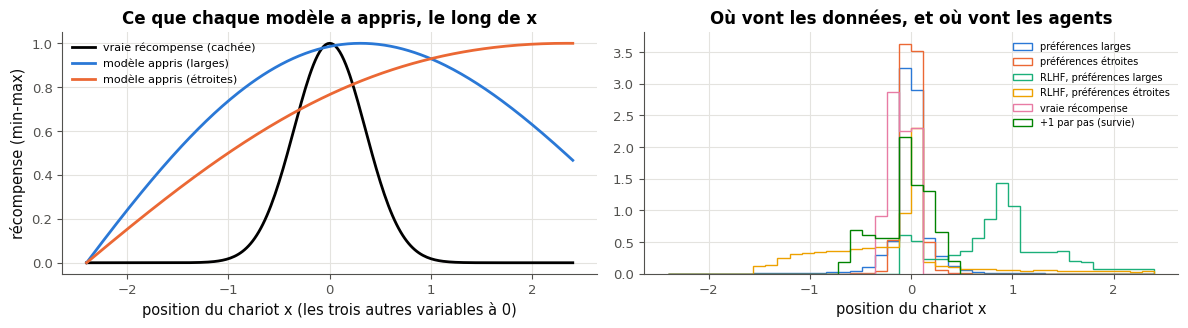

(66 s en tout)


In [67]:
# The two reward models (broad, narrow), then four PPO agents: on each learned reward, on the true reward, on the +1 of
# CartPole; each measured by the true reward and by the broad model, on 20 deterministic episodes
if not (ok_26 and ok_20):
    print("⏳ Ex B8.26 : l'expérience attend que les vérifications de B8.26 et de B8.20 (ton PPO) passent.")
else:
    with checked("B8.26"):
        start_26 = time.perf_counter()
        models_26 = {}
        for name_26, pairs_26, held_26 in (("larges", PAIRS_26, HELD_26), ("étroites", NARROW_26, NARROW_HELD_26)):
            models_26[name_26], losses_26 = train_reward_model_26(pairs_26, SEED_26)
            print(f"modèle de récompense, préférences {name_26} : loss {fr(losses_26[0], 3)} → {fr(losses_26[-1], 3)} ; "
                  f"accuracy {fr(wbr.preference_accuracy(models_26[name_26], held_26), 2)} sur ses paires tenues à "
                  f"l'écart, {fr(wbr.preference_accuracy(models_26[name_26], HELD_26), 2)} sur les paires larges")
        accuracy_26 = wbr.preference_accuracy(models_26["larges"], HELD_26)
        verdict("B8.26", accuracy_26 >= THRESHOLD_26,
                f"ton modèle de récompense (préférences larges) classe {fr(100 * accuracy_26, 0)} % des paires tenues à "
                f"l'écart dans le bon ordre (au moins {fr(100 * THRESHOLD_26, 0)} % attendus).",
                f"ton modèle de récompense (préférences larges) ne classe que {fr(100 * accuracy_26, 0)} % des paires tenues "
                f"à l'écart dans le bon ordre (au moins {fr(100 * THRESHOLD_26, 0)} % attendus).")
        rewards_26 = {"RLHF, préférences larges": reward_fn_26(models_26["larges"]),
                      "RLHF, préférences étroites": reward_fn_26(models_26["étroites"]),
                      "vraie récompense": true_reward_26, "+1 par pas (survie)": None}
        AGENTS_26, rows_26 = {}, {}
        for name_26, fn_26 in rewards_26.items():
            AGENTS_26[name_26], _ = train_ppo_20(SEED_26, STEPS_26, reward_fn=fn_26)
            rows_26[name_26] = wbr.rlhf_measure(AGENTS_26[name_26], models_26["larges"], 20, EVAL_SEED)
            rows_26[name_26]["narrow"] = wbr.rlhf_measure(AGENTS_26[name_26], models_26["étroites"], 20,
                                                          EVAL_SEED)["learned_per_step"]
        print(f"\n{'agent (PPO, ' + str(STEPS_26) + ' pas)':28s} | longueur | vraie récompense par pas | |x| moyen | "
              "récompense apprise par pas (modèle large ; étroit)")
        for name_26, m_26 in rows_26.items():
            print(f"{name_26:28s} | {m_26['length']:8.0f} | {fr(m_26['true_per_step'], 3):>24s} | "
                  f"{fr(m_26['abs_x'], 2):>9s} | {fr(m_26['learned_per_step'], 3)} ; {fr(m_26['narrow'], 3)}")
        xs_26 = np.linspace(-2.4, 2.4, 241)
        grid_26 = np.zeros((len(xs_26), 4), dtype=np.float32)
        grid_26[:, 0] = xs_26
        fig_26, (ax1_26, ax2_26) = plt.subplots(1, 2, figsize=(12, 3.4))
        ax1_26.plot(xs_26, wbr.centered_reward(grid_26), color="k", lw=2, label="vraie récompense (cachée)")
        for name_26, model_26 in models_26.items():
            with torch.no_grad():
                r_26 = model_26(torch.as_tensor(grid_26)).numpy()
            ax1_26.plot(xs_26, (r_26 - r_26.min()) / (r_26.max() - r_26.min() + 1e-12), label=f"modèle appris ({name_26})")
        ax1_26.set(xlabel="position du chariot x (les trois autres variables à 0)", ylabel="récompense (min-max)",
                   title="Ce que chaque modèle a appris, le long de x")
        ax1_26.legend(fontsize=8)
        data_x_26 = {"préférences larges": np.concatenate([t[:, 0] for t in PAIRS_26["first"] + PAIRS_26["second"]]),
                     "préférences étroites": np.concatenate([t[:, 0] for t in NARROW_26["first"] + NARROW_26["second"]])}
        for name_26, agent_26 in AGENTS_26.items():
            data_x_26[name_26] = np.concatenate([t[:, 0] for t in wbr.policy_trajectories(agent_26, 5, EVAL_SEED)])
        for name_26, x_26 in data_x_26.items():
            ax2_26.hist(x_26, bins=40, range=(-2.4, 2.4), density=True, histtype="step", lw=1.5, label=name_26)
        ax2_26.set(xlabel="position du chariot x", title="Où vont les données, et où vont les agents")
        ax2_26.legend(fontsize=7)
        plt.tight_layout()
        plt.show()
        print(f"({time.perf_counter() - start_26:.0f} s en tout)")

### Ex B8.27 — Revue de code : comparer ton PPO à une implémentation de référence et documenter chaque écart 🛠️ ★★ ⏱️ 30 min
**Objectif :** relire ppo.py de CleanRL ligne à ligne face à ton PPO, et documenter chaque écart : ce qu'il fait, ce que tu fais, l'effet attendu, et ta décision.  
**Prérequis :** Ex B8.20, B8.21 · 📄 B8.11 · fiche §208.4 (« Fin d'épisode ou limite de temps »), §208.5 (🕰️ Gymnasium 1.x), §208.6 (🕰️ les bibliothèques de référence, « Déboguer un agent qui n'apprend pas ») · **Fil rouge :** CartPole · **Parcours :** C

Une revue de code, comme en entreprise avant de fusionner une implémentation : la tienne (B8.20, ou la solution de `05_solutions.ipynb` si tu préfères partir d'elle) face à `cleanrl/ppo.py` de CleanRL (licence MIT), **au commit épinglé** de la fiche : la cellule donnée affiche le lien et télécharge le fichier (312 lignes) pour la vérification. Lis-le sur GitHub, avec la liste des « 37 détails d'implémentation » de Huang et coll. (2022, liens dans la fiche, 208.6) ; ne l'installe pas (il fige gymnasium 0.29 et Python < 3.11).

**Contrat** de `REVIEW_27` : une liste d'au moins **8 écarts**, chacun un dictionnaire de six clés :
- `"sujet"` : de quoi parle l'écart, en quelques mots ;
- `"lignes"` : le numéro de la ligne de `ppo.py`, ou un couple `(première, dernière)` ;
- `"extrait"` : au moins 8 caractères recopiés de ces lignes (à une ligne près ; la vérification les cherche dans le fichier) ;
- `"chez_moi"` : ce que fait ton PPO à la place (une phrase) ;
- `"effet"` : ce que l'écart change, et dans quel cas (une phrase) ;
- `"decision"` : `"garder"` (ta version), `"adopter"` (celle de CleanRL) ou `"tester"` (sur plusieurs graines, avant de choisir).

La revue doit au moins couvrir les deux écarts que la fiche signale : la ligne où `ppo.py` décide qu'un épisode est fini (208.4), et une ligne qui suppose l'autoreset same-step de gymnasium 0.29 (🕰️ Gymnasium 1.x, 208.5). Les autres sont à trouver : la loss du critique, les journaux, les mini-batches, les réglages, les graines… La cellule de vérification contrôle la **structure** (les clés, les lignes, les extraits, les décisions, les deux écarts de la fiche), écrit la revue en tableau Markdown dans `revue_ppo_cleanrl.md` (à côté de ton notebook) et l'affiche. Le **fond** (chaque écart est-il réel, son effet est-il juste ?) se corrige avec `05_solutions.md`.

Dans tes notes : quel écart changerait le plus un résultat sur CartPole, et lequel ne se verrait jamais ? Lesquels décides-tu de tester, et sur combien de graines ? Lequel des « 37 détails » ton PPO n'a-t-il pas, sans que ce soit un écart avec `ppo.py` ?

In [68]:
import tempfile
from pathlib import Path

from IPython.display import Markdown, display

CLEANRL_LINES_27 = wbr.cleanrl_ppo_lines()        # ppo.py of CleanRL at the commit of the fiche (None without network)
FIELDS_27 = ("sujet", "lignes", "extrait", "chez_moi", "effet", "decision")
DECISIONS_27 = ("garder", "adopter", "tester")
print(f"CleanRL ppo.py, commit {wbr.CLEANRL_COMMIT[:7]} : {wbr.CLEANRL_PPO_PAGE}")
print("fichier relu :" if CLEANRL_LINES_27 else "ℹ️ fichier non téléchargé (pas de réseau ?) : lis-le sur GitHub ; les "
      "extraits ne seront pas comparés aux lignes.", f"{len(CLEANRL_LINES_27)} lignes" if CLEANRL_LINES_27 else "")


def line_range_27(lines):
    """(first, last) of the "lignes" field: an int, or a pair (first, last); None if it is neither."""
    if isinstance(lines, (int, np.integer)) and not isinstance(lines, bool):
        return int(lines), int(lines)
    if (isinstance(lines, (tuple, list)) and len(lines) == 2 and all(isinstance(v, (int, np.integer))
                                                                     and not isinstance(v, bool) for v in lines)):
        return int(min(lines)), int(max(lines))
    return None


def check_review_27(review):
    """The problems of a review (a list of dicts with the keys FIELDS_27); an empty list when its structure is right.
    The content (is each gap real, is its effect right?) is corrected with 05_solutions.md."""
    problems = []
    if not isinstance(review, (list, tuple)) or not all(isinstance(e, dict) for e in review):
        return ["REVIEW_27 doit être une liste de dictionnaires (un par écart)."]
    if len(review) < 8:
        problems.append(f"la revue compte {len(review)} écarts : il en faut au moins 8.")
    cited = set()
    for k, entry in enumerate(review, start=1):
        where = f"écart {k} ({str(entry.get('sujet', '?'))[:40]})"
        missing = [f for f in FIELDS_27 if f not in entry]
        extra = [f for f in entry if f not in FIELDS_27]
        if missing or extra:
            problems.append(f"{where} : attendu les clés {list(FIELDS_27)}"
                            + (f", il manque {missing}" if missing else "") + (f", en trop {extra}" if extra else "") + ".")
            continue
        for f in ("sujet", "chez_moi", "effet"):
            if not isinstance(entry[f], str) or len(entry[f].split()) < (2 if f == "sujet" else 6):
                problems.append(f"{where} : « {f} » doit être une phrase en français ("
                                + ("au moins 2 mots" if f == "sujet" else "au moins 6 mots") + ").")
        span = line_range_27(entry["lignes"])
        if span is None or not (1 <= span[0] <= span[1] <= wbr.CLEANRL_PPO_LINES):
            problems.append(f"{where} : « lignes » doit être un numéro de ligne de ppo.py (1 à {wbr.CLEANRL_PPO_LINES}) "
                            "ou un couple (première, dernière).")
            span = None
        if not isinstance(entry["extrait"], str) or len(entry["extrait"].strip()) < 8:
            problems.append(f"{where} : « extrait » doit recopier au moins 8 caractères du code de ces lignes.")
        elif span and CLEANRL_LINES_27:
            text = "\n".join(CLEANRL_LINES_27[max(0, span[0] - 2):span[1] + 1])
            if " ".join(entry["extrait"].split()) not in " ".join(text.split()):
                problems.append(f"{where} : l'extrait « {entry['extrait'].strip()[:50]} » n'est pas dans les lignes "
                                f"{span[0]} à {span[1]} de ppo.py (à une ligne près).")
        if entry["decision"] not in DECISIONS_27:
            problems.append(f"{where} : « decision » vaut {entry['decision']!r} ; attendu l'un de {list(DECISIONS_27)}.")
        if span:
            cited |= set(range(span[0], span[1] + 1))
    if not problems:
        if not cited & {206}:
            problems.append("la revue ne cite pas la ligne où ppo.py décide qu'un épisode est fini (208.4, « Fin "
                            "d'épisode ou limite de temps »).")
        if not cited & {162, 205, 210, 211}:
            problems.append("la revue ne cite aucune ligne qui suppose l'autoreset same-step de gymnasium 0.29 "
                            "(🕰️ Gymnasium 1.x, 208.5).")
    return problems


def review_markdown_27(review):
    """The review as a Markdown table (for your notes, your README, a pull request)."""
    rows = ["| # | Sujet | ppo.py | Chez moi | Effet | Décision |", "|---|---|---|---|---|---|"]
    for k, e in enumerate(review, start=1):
        span = line_range_27(e["lignes"])
        where = f"l. {span[0]}" if span and span[0] == span[1] else (f"l. {span[0]}-{span[1]}" if span else "?")
        cells = [str(k), e["sujet"], f"{where} : `{e['extrait'].strip()}`", e["chez_moi"], e["effet"], e["decision"]]
        rows.append("| " + " | ".join(c.replace("|", "\\|").replace("\n", " ") for c in cells) + " |")
    return "\n".join(rows)

CleanRL ppo.py, commit fe8d8a0 : https://github.com/vwxyzjn/cleanrl/blob/fe8d8a03c41a7ef5b523e2e354bd01c363e786bb/cleanrl/ppo.py
fichier relu : 312 lignes


In [69]:
REVIEW_27 = [
    {"sujet": "fin d'épisode et limite de temps",
     "lignes": 206,
     "extrait": 'next_done = np.logical_or(terminations, truncations)',
     "chez_moi": "terminated coupe l'amorçage dans δ, terminated ou truncated arrête la récursion, et une troncature amorce sur V de la vraie dernière observation (next_values)",
     "effet": "ppo.py traite la limite de 500 pas comme une chute : les états proches de la fin d'un bon épisode reçoivent une valeur trop basse, alors que l'état ne dit rien du temps écoulé",
     "decision": 'garder'},
    {"sujet": 'autoreset next-step de gymnasium 1.x',
     "lignes": (162, 164),
     "extrait": 'envs = gym.vector.SyncVectorEnv(',
     "chez_moi": 'make_vec en autoreset next-step explicite, et un masque valid qui écarte le pas qui ne fait que remettre une copie à zéro',
     "effet": 'écrit pour gymnasium 0.29 (same-step), ppo.py garde sous la 1.x le pas de reset comme une transition : une action ignorée, une récompense 0, un faux passage de la dernière observation à la première',
     "decision": 'garder'},
    {"sujet": 'retours des épisodes dans les journaux',
     "lignes": (210, 211),
     "extrait": 'if "final_info" in infos:',
     "chez_moi": "je suis le retour de chaque copie sur les pas valides et je le range quand l'épisode finit",
     "effet": "en next-step, infos n'a plus de clé final_info : ppo.py n'affiche plus aucun retour sous gymnasium 1.x, sans message d'erreur",
     "decision": 'garder'},
    {"sujet": "valeur de l'état suivant dans GAE",
     "lignes": (226, 228),
     "extrait": 'nextvalues = values[t + 1]',
     "chez_moi": "next_values[t] est V de l'observation que rend le pas t, calculée pour chaque pas du rollout",
     "effet": "identique tant que l'épisode continue ; à une fin, values[t + 1] est la valeur d'un autre épisode, que ppo.py masque, ce qui l'empêche aussi d'amorcer une troncature",
     "decision": 'garder'},
    {"sujet": 'clip de la loss du critique',
     "lignes": (271, 280),
     "extrait": 'v_clipped = b_values[mb_inds] + torch.clamp(',
     "chez_moi": 'une loss quadratique simple, 0,5 fois la moyenne des carrés des écarts aux retours de GAE',
     "effet": "le clip limite le changement de V à ± clip_coef par mise à jour ; les 37 détails ne lui trouvent pas d'avantage net, et il ralentit un critique dont les retours valent des centaines",
     "decision": 'tester'},
    {"sujet": 'KL approchée dans les journaux',
     "lignes": 305,
     "extrait": 'writer.add_scalar("losses/approx_kl", approx_kl.item(), global_step)',
     "chez_moi": "la moyenne de (ρ − 1) − ln ρ sur tous les mini-batches de l'itération",
     "effet": "ppo.py écrit la valeur du dernier mini-batch de la dernière epoch, la plus éloignée de l'ancienne politique : ses courbes de KL ne se comparent pas directement aux miennes",
     "decision": 'garder'},
    {"sujet": 'arrêt des epochs sur la KL',
     "lignes": (292, 293),
     "extrait": 'if args.target_kl is not None and approx_kl > args.target_kl:',
     "chez_moi": 'toujours n_epochs passages, sans test de la KL',
     "effet": "désactivé par défaut dans ppo.py aussi (target_kl = None) ; activé, il protégerait d'un learning rate ou d'un nombre d'epochs trop grand, comme dans le run malade de B8.21",
     "decision": 'tester'},
    {"sujet": 'taille des mini-batches',
     "lignes": (246, 248),
     "extrait": 'for start in range(0, args.batch_size, args.minibatch_size):',
     "chez_moi": 'les transitions valides seulement, coupées en n_minibatches parts égales, le reste de la division laissé de côté',
     "effet": "ppo.py coupe toujours 512 transitions en 4 mini-batches de 128, pas de reset compris ; chez moi la taille varie d'une itération à l'autre de quelques transitions",
     "decision": 'garder'},
    {"sujet": "learning rate et nombre d'epochs",
     "lignes": (41, 56),
     "extrait": 'learning_rate: float = 2.5e-4',
     "chez_moi": 'lr de 1e-3 et 10 epochs (SETTINGS_20), pour 50 000 pas au lieu de 500 000',
     "effet": "quatre fois plus de pas d'Adam par itération et des pas quatre fois plus grands : la KL et la fraction clippée montent, c'est le prix d'un budget dix fois plus petit (B8.22)",
     "decision": 'tester'},
    {"sujet": 'graine du mélange des mini-batches',
     "lignes": 245,
     "extrait": 'np.random.shuffle(b_inds)',
     "chez_moi": 'torch.randperm avec un torch.Generator à graine, le même qui tire les actions',
     "effet": "les deux sont reproductibles à graine fixée ; ppo.py dépend du générateur global de NumPy, qu'un autre appel du programme peut déplacer",
     "decision": 'garder'},
]


if REVIEW_27 is ... or (isinstance(REVIEW_27, list) and len(REVIEW_27) <= 1):
    print("⏳ Ex B8.27 : pas encore fait (complète REVIEW_27).")
else:
    problems_27 = check_review_27(REVIEW_27)
    for problem_27 in problems_27:
        print(f"❌ Ex B8.27 : {problem_27}")
    if not problems_27:
        decisions_27 = {d: sum(e["decision"] == d for e in REVIEW_27) for d in DECISIONS_27}
        print(f"✅ Ex B8.27 : {len(REVIEW_27)} écarts, chacun avec ses lignes, son extrait, ton code, son effet et une "
              f"décision ({decisions_27}) ; les deux écarts de la fiche sont cités. Le fond se corrige avec "
              "05_solutions.md.")
        review_path_27 = (Path("revue_ppo_cleanrl.md") if "mon_travail" in str(Path.cwd())   # next to your notebook
                          else Path(tempfile.mkdtemp(prefix="wb_b8_27_")) / "revue_ppo_cleanrl.md")
        review_path_27.write_text(f"# Revue de code : mon PPO face à CleanRL ppo.py ({wbr.CLEANRL_COMMIT[:7]})\n\n"
                                  + review_markdown_27(REVIEW_27) + "\n", encoding="utf-8")
        print(f"   écrite dans {review_path_27.name}" + (", à côté de ton notebook." if "mon_travail" in str(Path.cwd())
                                                         else "."))
        display(Markdown(review_markdown_27(REVIEW_27)))

✅ Ex B8.27 : 10 écarts, chacun avec ses lignes, son extrait, ton code, son effet et une décision ({'garder': 7, 'adopter': 0, 'tester': 3}) ; les deux écarts de la fiche sont cités. Le fond se corrige avec 05_solutions.md.
   écrite dans revue_ppo_cleanrl.md.


| # | Sujet | ppo.py | Chez moi | Effet | Décision |
|---|---|---|---|---|---|
| 1 | fin d'épisode et limite de temps | l. 206 : `next_done = np.logical_or(terminations, truncations)` | terminated coupe l'amorçage dans δ, terminated ou truncated arrête la récursion, et une troncature amorce sur V de la vraie dernière observation (next_values) | ppo.py traite la limite de 500 pas comme une chute : les états proches de la fin d'un bon épisode reçoivent une valeur trop basse, alors que l'état ne dit rien du temps écoulé | garder |
| 2 | autoreset next-step de gymnasium 1.x | l. 162-164 : `envs = gym.vector.SyncVectorEnv(` | make_vec en autoreset next-step explicite, et un masque valid qui écarte le pas qui ne fait que remettre une copie à zéro | écrit pour gymnasium 0.29 (same-step), ppo.py garde sous la 1.x le pas de reset comme une transition : une action ignorée, une récompense 0, un faux passage de la dernière observation à la première | garder |
| 3 | retours des épisodes dans les journaux | l. 210-211 : `if "final_info" in infos:` | je suis le retour de chaque copie sur les pas valides et je le range quand l'épisode finit | en next-step, infos n'a plus de clé final_info : ppo.py n'affiche plus aucun retour sous gymnasium 1.x, sans message d'erreur | garder |
| 4 | valeur de l'état suivant dans GAE | l. 226-228 : `nextvalues = values[t + 1]` | next_values[t] est V de l'observation que rend le pas t, calculée pour chaque pas du rollout | identique tant que l'épisode continue ; à une fin, values[t + 1] est la valeur d'un autre épisode, que ppo.py masque, ce qui l'empêche aussi d'amorcer une troncature | garder |
| 5 | clip de la loss du critique | l. 271-280 : `v_clipped = b_values[mb_inds] + torch.clamp(` | une loss quadratique simple, 0,5 fois la moyenne des carrés des écarts aux retours de GAE | le clip limite le changement de V à ± clip_coef par mise à jour ; les 37 détails ne lui trouvent pas d'avantage net, et il ralentit un critique dont les retours valent des centaines | tester |
| 6 | KL approchée dans les journaux | l. 305 : `writer.add_scalar("losses/approx_kl", approx_kl.item(), global_step)` | la moyenne de (ρ − 1) − ln ρ sur tous les mini-batches de l'itération | ppo.py écrit la valeur du dernier mini-batch de la dernière epoch, la plus éloignée de l'ancienne politique : ses courbes de KL ne se comparent pas directement aux miennes | garder |
| 7 | arrêt des epochs sur la KL | l. 292-293 : `if args.target_kl is not None and approx_kl > args.target_kl:` | toujours n_epochs passages, sans test de la KL | désactivé par défaut dans ppo.py aussi (target_kl = None) ; activé, il protégerait d'un learning rate ou d'un nombre d'epochs trop grand, comme dans le run malade de B8.21 | tester |
| 8 | taille des mini-batches | l. 246-248 : `for start in range(0, args.batch_size, args.minibatch_size):` | les transitions valides seulement, coupées en n_minibatches parts égales, le reste de la division laissé de côté | ppo.py coupe toujours 512 transitions en 4 mini-batches de 128, pas de reset compris ; chez moi la taille varie d'une itération à l'autre de quelques transitions | garder |
| 9 | learning rate et nombre d'epochs | l. 41-56 : `learning_rate: float = 2.5e-4` | lr de 1e-3 et 10 epochs (SETTINGS_20), pour 50 000 pas au lieu de 500 000 | quatre fois plus de pas d'Adam par itération et des pas quatre fois plus grands : la KL et la fraction clippée montent, c'est le prix d'un budget dix fois plus petit (B8.22) | tester |
| 10 | graine du mélange des mini-batches | l. 245 : `np.random.shuffle(b_inds)` | torch.randperm avec un torch.Generator à graine, le même qui tire les actions | les deux sont reproductibles à graine fixée ; ppo.py dépend du générateur global de NumPy, qu'un autre appel du programme peut déplacer | garder |

### Ex B8.28 — Défi : CartPole-v1 résolu (≥ 475 sur 100 épisodes) en au plus 100 000 pas, trois graines sur trois 🏆 ★★★★ ⏱️ 120 min
**Objectif :** résoudre CartPole-v1 sur trois graines sur trois, avec un budget de pas compté par l'infrastructure et une évaluation sur des graines tenues à l'écart.  
**Prérequis :** 🔬 B8.22 · Ex B8.20, B8.21 · fiche §208.6 (« Des hyperparamètres qui comptent », « Évaluer un agent ») · **Fil rouge :** CartPole · **Parcours :** C

**L'objectif** : CartPole-v1 **résolu**, c'est-à-dire au moins 475 de retour moyen sur 100 épisodes, avec **au plus 100 000 pas** d'environnement par run, sur **trois graines sur trois** (`SEEDS_28`).

**Contrat** de `train_28(seed, budget)` : entraîner un agent **à partir de rien** sur CartPole-v1, avec au plus `budget` pas d'environnement, puis rendre sa politique : un module torch (évalué par son action la plus probable : des logits, ou un agent qui a un `actor`) ou une fonction **déterministe** `(state, info) -> int`. Tu peux reprendre ton `train_ppo_20` avec d'autres réglages, ou écrire autre chose.

**Les règles**, appliquées par `wbr.run_challenge`, qui appelle `train_28(seed, BUDGET_28)` pour chaque graine :
- **tout pas compte** : chaque `step` de chaque CartPole créé pendant le run, quelle que soit la façon de le créer (`gym.make`, `gym.make_vec`, `wbr.make_env`, une copie), toutes copies comprises, tes propres évaluations comprises ; le pas qui dépasserait le budget arrête le run (« budget dépassé ») ; le mode `"async"`, qui joue dans d'autres processus, est refusé ;
- **à partir de rien** : pendant le run, les entraîneurs et les checkpoints de `wbr` et `torch.load` sont interdits, les agents du notebook (ton agent de B8.20, ceux de B8.26) sont masqués, et un agent rendu dont les paramètres sont ceux d'un agent qui existait avant le run est refusé ;
- **l'évaluation** : 100 épisodes déterministes de 500 pas au plus, sur des graines tenues à l'écart (aucun entraînement ni aucune autre évaluation du notebook ne s'en sert) ; un run compte s'il n'enfreint aucune règle ;
- **règle d'honneur** : n'écris pas ton propre simulateur de CartPole (ses équations sont publiques : ce serait un environnement hors du compteur) et ne contourne pas le compteur ; le budget est la mesure de l'efficacité en échantillons (208.6), pas une contrainte de temps.

La cellule de vérification lance les trois runs l'un après l'autre (avec les réglages de B8.20, environ 40 s chacun), affiche pour chacun le retour moyen, le plus court des 100 épisodes, le nombre de pas joués et le temps, puis vérifie par `wb.check` le nombre de graines résolues. Rien à taper.

Dans tes notes : tes réglages, et pourquoi (B8.22) ; le retour de chaque graine ; ce que tu aurais fait avec deux fois moins de pas.

In [70]:
BUDGET_28 = wbr.CHALLENGE_BUDGET              # 100 000 environment steps per run, counted by the infrastructure
SEEDS_28 = wbr.CHALLENGE_SEEDS                 # the three seeds of the challenge (none of them trains anything else)
print(f"défi : {len(SEEDS_28)} runs (graines {list(SEEDS_28)}), au plus {BUDGET_28} pas d'environnement chacun, puis "
      f"100 épisodes déterministes sur des graines tenues à l'écart ; objectif : {wbr.SOLVED:g} de moyenne sur les "
      "trois runs.")

défi : 3 runs (graines [280, 281, 282]), au plus 100000 pas d'environnement chacun, puis 100 épisodes déterministes sur des graines tenues à l'écart ; objectif : 475 de moyenne sur les trois runs.


In [71]:
SETTINGS_28 = {**SETTINGS_20}          # the reference settings of B8.20 (10 epochs, lr 1e-3 decreasing to 0): see 05


def train_28(seed, budget):
    """Train an agent on CartPole-v1 from scratch, with at most `budget` environment steps (every copy of every
    CartPole you create counts, your own evaluations too), and return its policy: a torch module (evaluated by its
    most probable action: logits, or an agent with an `actor`) or a deterministic function (state, info) -> int."""
    agent, _ = train_ppo_20(seed, budget, SETTINGS_28)   # n_iter = budget // 512 iterations: 99 840 steps at most
    return agent

In [72]:
wb.record("B8.28", 3, choices=[0, 1, 2, 3], mistakes={
    "deux runs sur trois seulement : un réglage qui réussit sur une graine doit tenir sur toutes (relis B8.22)": 2,
    "un run sur trois seulement : regarde la courbe de chaque graine, et relis B8.22": 1,
    "aucun run ne tient 475 : vérifie d'abord ton PPO avec les réglages de B8.20, sur ce budget": 0},
    fractional="la réponse est un nombre de graines, de 0 à 3")

WB_ANSWER {"choices": ["0", "1", "2", "3"], "fractional": "la réponse est un nombre de graines, de 0 à 3", "hash": "76ad5c9b35206e9cc8ad3c0d358df6f299a5f517026a473a307cb58a882fc3ef", "id": "B8.28", "kind": "int", "magnitude": 0, "mistakes": {"474f0f43fb3f8cdc4c4eb38770e6ad28c69a67a52703e01236a307166e6e7c62": "deux runs sur trois seulement : un réglage qui réussit sur une graine doit tenir sur toutes (relis B8.22)", "5905e180c921d1e76379c0df936118c36f041f1b2e3c64494d69cc9bf03f7911": "aucun run ne tient 475 : vérifie d'abord ton PPO avec les réglages de B8.20, sur ce budget", "c17936e6182cc95aec5cb5e7aa67643b21a0466a96fddff02cb66818d734bb63": "un run sur trois seulement : regarde la courbe de chaque graine, et relis B8.22"}, "sign": 1}
📝 Ex B8.28 : réponse enregistrée (int).


In [73]:
results_28 = []
for k_28, seed_28 in enumerate(SEEDS_28):
    with checked("B8.28"):
        result_28 = wbr.run_challenge(train_28, seed_28, budget=BUDGET_28, namespace=globals())
        results_28.append(result_28)
        if result_28["error"]:
            print(f"❌ Ex B8.28 : graine {seed_28} : le run ne compte pas : {result_28['error']} "
                  f"({result_28['steps']} pas joués en {result_28['seconds']:.0f} s).")
        else:
            verdict("B8.28", result_28["solved"],
                    f"graine {seed_28} : {fr(result_28['mean_return'], 1)} sur 100 épisodes (le plus court : "
                    f"{result_28['min_return']:.0f} pas), {result_28['steps']} pas d'environnement, "
                    f"{result_28['seconds']:.0f} s.",
                    f"graine {seed_28} : {fr(result_28['mean_return'], 1)} sur 100 épisodes, sous {wbr.SOLVED:g} "
                    f"({result_28['steps']} pas d'environnement, {result_28['seconds']:.0f} s).")
    if len(results_28) <= k_28:            # train_28 not written yet (⏳), or it raised an error (❌): stop there
        break
if len(results_28) == len(SEEDS_28):
    solved_28 = sum(bool(r["solved"]) and r["error"] is None for r in results_28)
    wb.check("B8.28", solved_28, computed=True)

✅ Ex B8.28 : graine 280 : 500,0 sur 100 épisodes (le plus court : 500 pas), 99510 pas d'environnement, 39 s.


✅ Ex B8.28 : graine 281 : 500,0 sur 100 épisodes (le plus court : 500 pas), 99527 pas d'environnement, 39 s.


✅ Ex B8.28 : graine 282 : 500,0 sur 100 épisodes (le plus court : 500 pas), 99510 pas d'environnement, 40 s.
✅ Ex B8.28 : Parfait !


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer une cible DQN et Double DQN, en distinguant une vraie fin d'une limite de temps, et dire ce que le réseau cible et le rejeu changent à un DQN ?
2. Sais-tu écrire GAE et l'objectif clippé de PPO, puis reconnaître dans les journaux d'un PPO un learning rate trop grand, un clip absent ou un critique qui n'apprend pas ?
3. Sais-tu comparer des réglages sur plusieurs graines, et tester un agent sur une physique qu'il n'a pas vue ?
4. Sais-tu calculer une loss de Bradley-Terry et une loss DPO, entraîner un modèle de récompense, et dire où un agent qui l'optimise peut le pirater ?

**Pour aller plus loin** : l'article de Schulman et coll. (📄 B8.11) et les « 37 détails » de Huang et coll., cités dans la fiche ; ta revue de B8.27 (`revue_ppo_cleanrl.md`) pour ton portfolio. B8 est le dernier chapitre bonus.